In [1]:

from __future__ import print_function, division
from collections import defaultdict, OrderedDict
import gzip
import pickle
import json
import os
import uproot
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
from coffea import hist, processor 
from coffea.hist import plot
from coffea.util import load, save

In [2]:
hists = load("../../../hists/UL_lep_monotop_v1_test_preVFP_2016.scaled")
data={
    '2016':{
        'sre': 'SingleElectron',
        'srm': 'SingleMuon',
        'wjetm': 'SingleMuon',
        'ttbarm': 'SingleMuon',
        'wjete': 'SingleElectron',
        'ttbare': 'SingleElectron',
#         'zmcr': 'MET',
#         'zecr': 'EGamma',
#         'gcr': 'EGamma'
    }
}

data_hists   = hists['data']
bkg_hists    = hists['bkg']
signal_hists = hists['sig']

In [5]:
signal_hists['template'].identifiers('process')

[<StringBin (Mphi-1000_Mchi-1000) instance at 0x7f7638e67b00>,
 <StringBin (Mphi-1000_Mchi-150) instance at 0x7f7638e67b38>,
 <StringBin (Mphi-1250_Mchi-150) instance at 0x7f7638e67b70>,
 <StringBin (Mphi-1495_Mchi-750) instance at 0x7f7638e67ba8>,
 <StringBin (Mphi-1500_Mchi-1000) instance at 0x7f7638e67be0>,
 <StringBin (Mphi-1500_Mchi-150) instance at 0x7f7638e67c18>,
 <StringBin (Mphi-1700_Mchi-800) instance at 0x7f7638e67c50>,
 <StringBin (Mphi-1750_Mchi-150) instance at 0x7f7638e67c88>,
 <StringBin (Mphi-1750_Mchi-700) instance at 0x7f7638e67cc0>,
 <StringBin (Mphi-195_Mchi-100) instance at 0x7f7638e67cf8>,
 <StringBin (Mphi-1995_Mchi-1000) instance at 0x7f7638e67d30>,
 <StringBin (Mphi-2000_Mchi-1500) instance at 0x7f7638e67d68>,
 <StringBin (Mphi-2000_Mchi-150) instance at 0x7f7638e67da0>,
 <StringBin (Mphi-2000_Mchi-500) instance at 0x7f7638e67dd8>,
 <StringBin (Mphi-200_Mchi-150) instance at 0x7f7638e67e10>,
 <StringBin (Mphi-200_Mchi-50) instance at 0x7f7638e67e48>,
 <String

In [3]:
import re
cr = "wjete"
systematics =[]
for syst in bkg_hists['template'].integrate('region', cr).identifiers('systematic'):
    if (re.search("Up$", str(syst))):
        systematics.append(str(syst)[:-2])
        
for proc in signal_hists['template'].identifiers("process"):
    print("*****",proc, "******")
    for syst in  systematics:
        if ("ew" in syst) or ("qcd" in syst) or ("mix" in syst) or ("muR" in syst) or("muF" in syst):
            continue
        print(syst)
        up = signal_hists['template'].integrate('region', cr).integrate('process', proc).integrate('systematic', syst+"Up").sum("npvs").values()[()]
        down = signal_hists['template'].integrate('region', cr).integrate('process', proc).integrate('systematic', syst+"Down").sum("npvs").values()[()]
        print("  up    ",up)
        print()
        print("  dn   ",down)

***** Mphi-1995_Mchi-1000 ******
FSR
  up     [ 0.          0.          0.          0.05511496  0.04174321  0.02783472
  0.         -0.0263458   0.03763501  0.          0.16748893]

  dn    [ 0.          0.          0.          0.02341513  0.01330892  0.01455412
  0.         -0.04326429  0.27381944  0.          0.09967587]
ISR
  up     [ 0.          0.          0.          0.04193535  0.02189357  0.02543361
  0.         -0.0364863   0.08451105  0.          0.12813361]

  dn    [ 0.          0.          0.          0.04659208  0.04167046  0.02442816
  0.         -0.03167409  0.08470165  0.          0.15277166]
JER
  up     [ 0.          0.          0.          0.04461347  0.02990241  0.02516902
  0.         -0.03472453  0.08445166  0.          0.13969468]

  dn    [ 0.          0.          0.          0.04461347  0.02990241  0.02516902
  0.         -0.03472453  0.08445166  0.          0.13969468]
JES
  up     [ 0.          0.          0.          0.04461347  0.02990241  0.02516902
  0. 

  up     [ 0.          0.          0.         -0.03955508  0.05159292  0.049665
  0.32050737  0.          0.          0.37619337  0.39869946]

  dn    [ 0.          0.          0.         -0.03857153  0.02885331  0.04718595
  0.03876646  0.          0.          0.77095924  0.25741435]
ISR
  up     [ 0.          0.          0.         -0.03848707  0.04339355  0.05408405
  0.1630693   0.          0.          0.39548278  0.32839126]

  dn    [ 0.          0.          0.         -0.05840276  0.05834086  0.0500927
  0.22378629  0.          0.          0.54146409  0.44434235]
JER
  up     [ 0.          0.          0.         -0.04691257  0.04995879  0.05288675
  0.1886756   0.          0.          0.45770085  0.37731538]

  dn    [ 0.          0.          0.         -0.04691257  0.04995879  0.05288675
  0.1886756   0.          0.          0.45770085  0.37731538]
JES
  up     [ 0.          0.          0.         -0.04691257  0.04995879  0.05288675
  0.1886756   0.          0.          0.45770

In [10]:
a=sum(data_hists['mT_corrected'].integrate('systematic', 'nominal').integrate('region', 'wjete').integrate('process').values()[()])

In [10]:
signal_hists['template']

<Hist (process,region,systematic,npvs,mT_corrected) instance at 0x7fe8e41eb1d0>

In [8]:
sys = 'nominal'
region = 'wjete'
print(region)
SUM_data = sum(signal_hists['mT_corrected'].integrate('systematic', sys).integrate('region', region).integrate('process', 'SingleElectron').values()[()])
print('SingleElectron',':', SUM_data)

tmp = 0
for process in bkg_hists["mT_corrected"].identifiers('process'):
    
    SUM_bkg = sum(bkg_hists['mT_corrected'].integrate('systematic', sys).integrate('region', region).integrate('process', process).values()[()])
    tmp+=SUM_bkg
    print(process,":",SUM_bkg)
print("Sum MC:", tmp)
print("Data/MC:", SUM_data/tmp)   

wjete


KeyError: ()

In [3]:
sys = 'nominal'
region = 'ttbare'
print(region)
SUM_data = sum(data_hists['mT_corrected'].integrate('systematic', sys).integrate('region', region).integrate('process', 'SingleElectron').values()[()])
print('SingleElectron',':', SUM_data)

tmp = 0
for process in bkg_hists[key].identifiers('process'):
    
    SUM_bkg = sum(bkg_hists['mT_corrected'].integrate('systematic', sys).integrate('region', region).integrate('process', process).values()[()])
    tmp+=SUM_bkg
    print(process,":",SUM_bkg)
print("Sum MC:", tmp)
print("Data/MC:", SUM_data/tmp) 

ttbare
SingleElectron : 0.0


NameError: name 'key' is not defined

In [ ]:
sys = 'nominal'
region = 'ttbarm'
print(region)
SUM_data = sum(data_hists['mT_corrected'].integrate('systematic', sys).integrate('region', region).integrate('process', 'SingleMuon').values()[()])
print('SingleMuon',':', SUM_data)

tmp = 0
for process in bkg_hists[key].identifiers('process'):
    
    SUM_bkg = sum(bkg_hists['mT_corrected'].integrate('systematic', sys).integrate('region', region).integrate('process', process).values()[()])
    tmp+=SUM_bkg
    print(process,":",SUM_bkg)
print("Sum MC:", tmp)
print("Data/MC:", SUM_data/tmp)

In [ ]:
sys = 'nominal'
region = 'wjetm'
print(region)
SUM_data = sum(data_hists['mT_corrected'].integrate('systematic', sys).integrate('region', region).integrate('process', 'SingleMuon').values()[()])
print('SingleMuon',':', SUM_data)

tmp = 0
for process in bkg_hists[key].identifiers('process'):
    
    SUM_bkg = sum(bkg_hists['mT_corrected'].integrate('systematic', sys).integrate('region', region).integrate('process', process).values()[()])
    tmp+=SUM_bkg
    print(process,":",SUM_bkg)
print("Sum MC:", tmp)
print("Data/MC:", SUM_data/tmp)

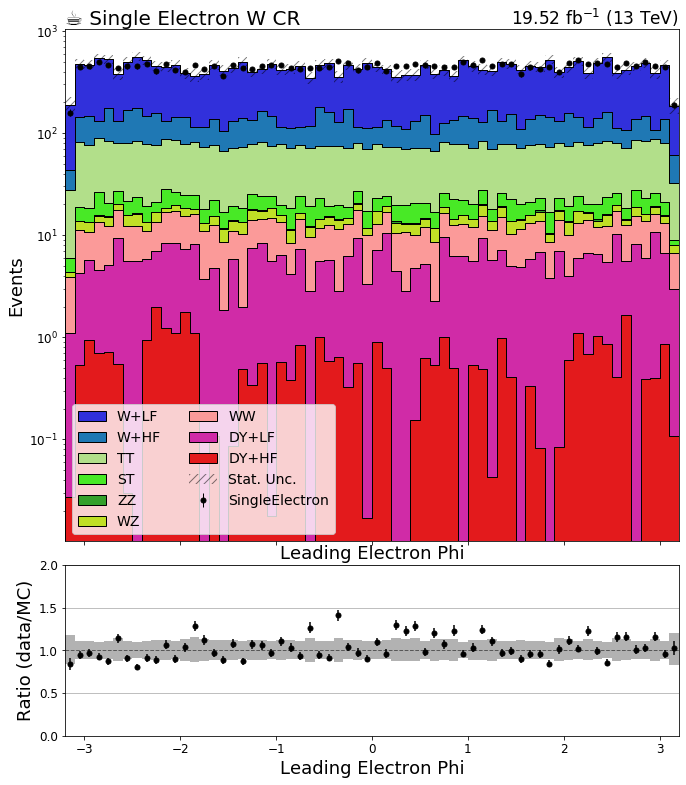

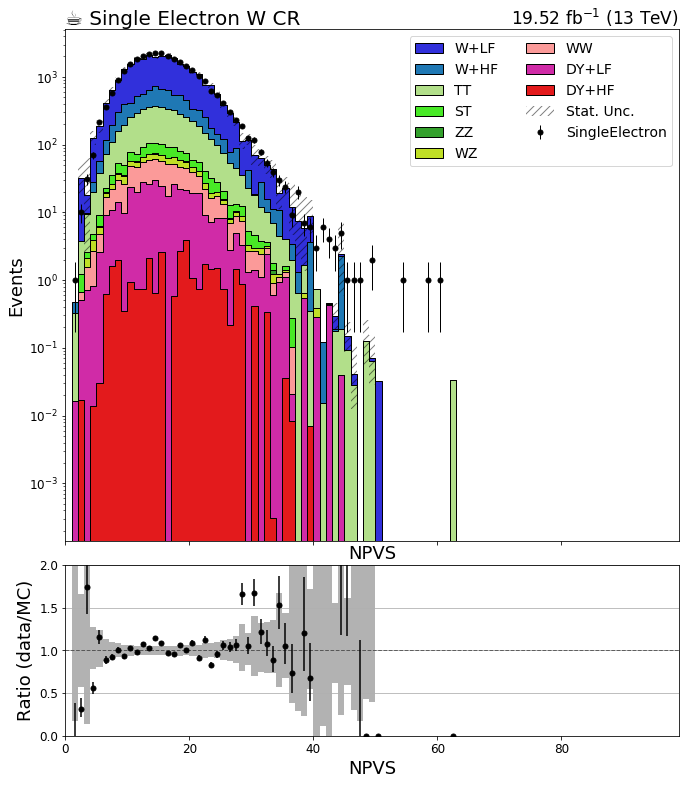

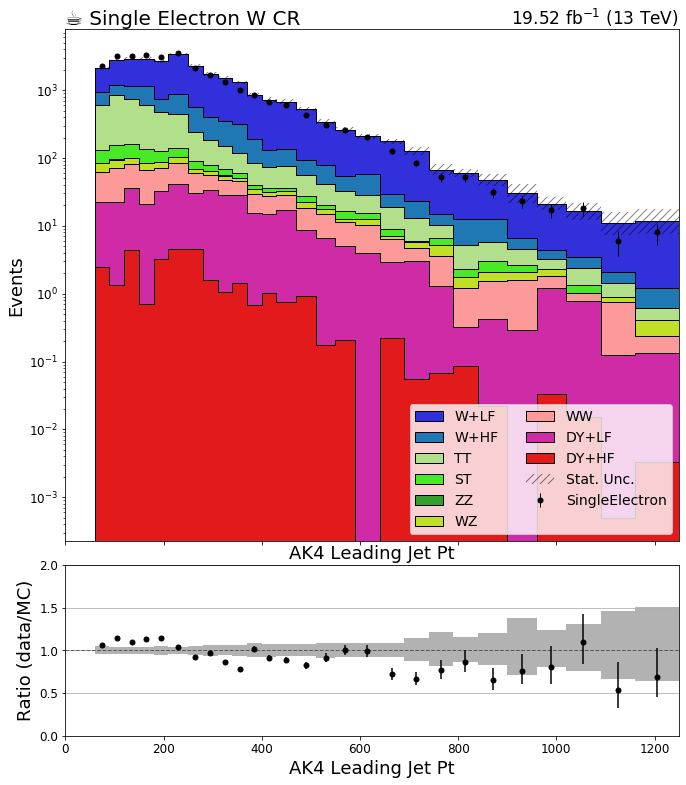

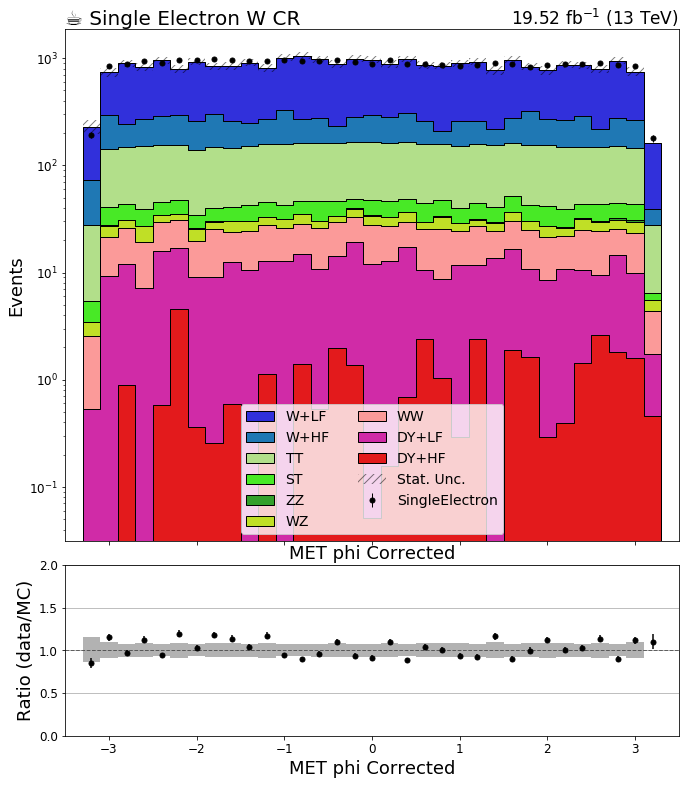

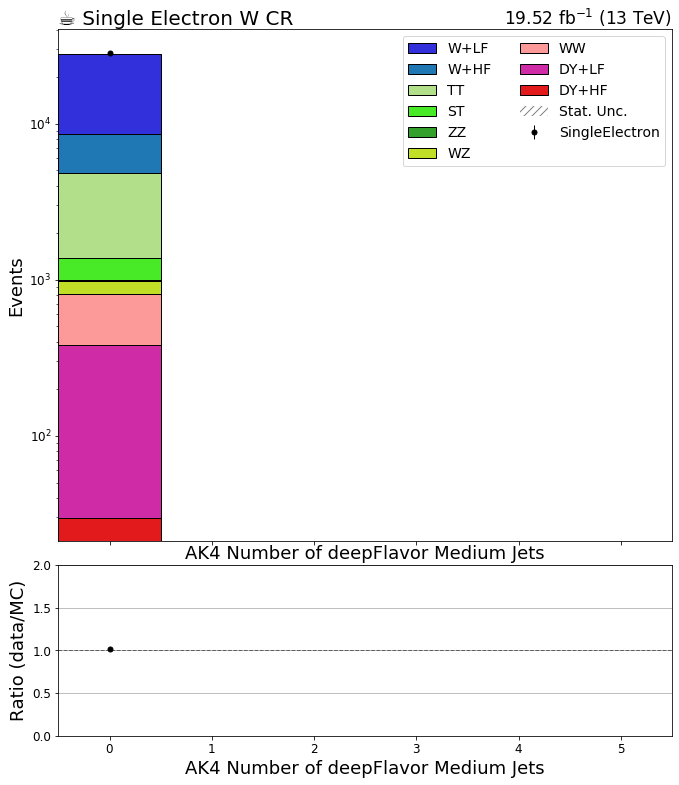

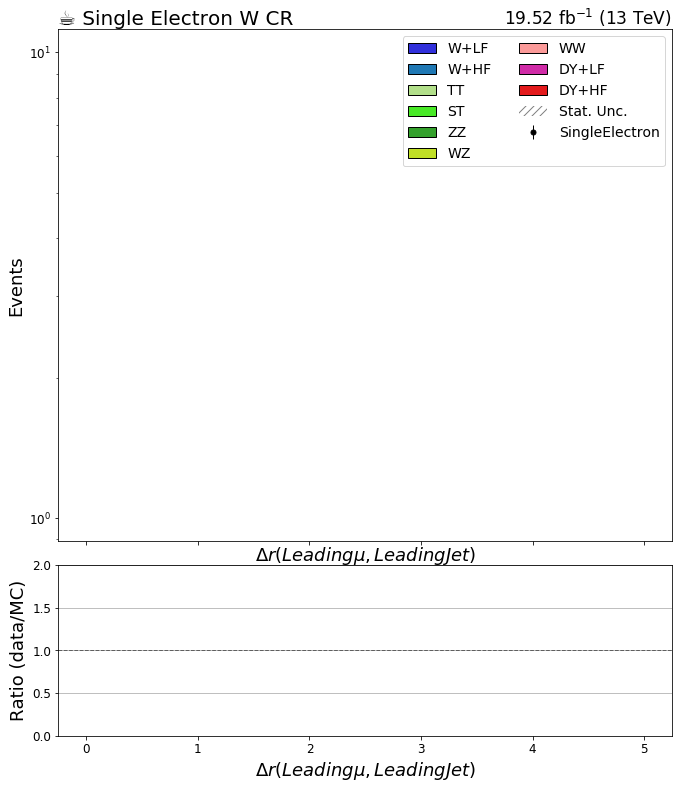

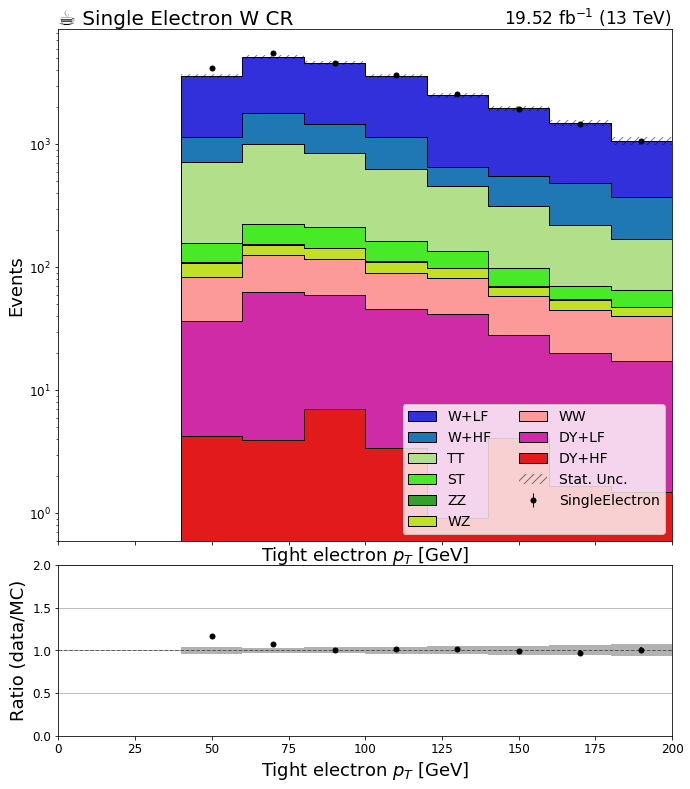

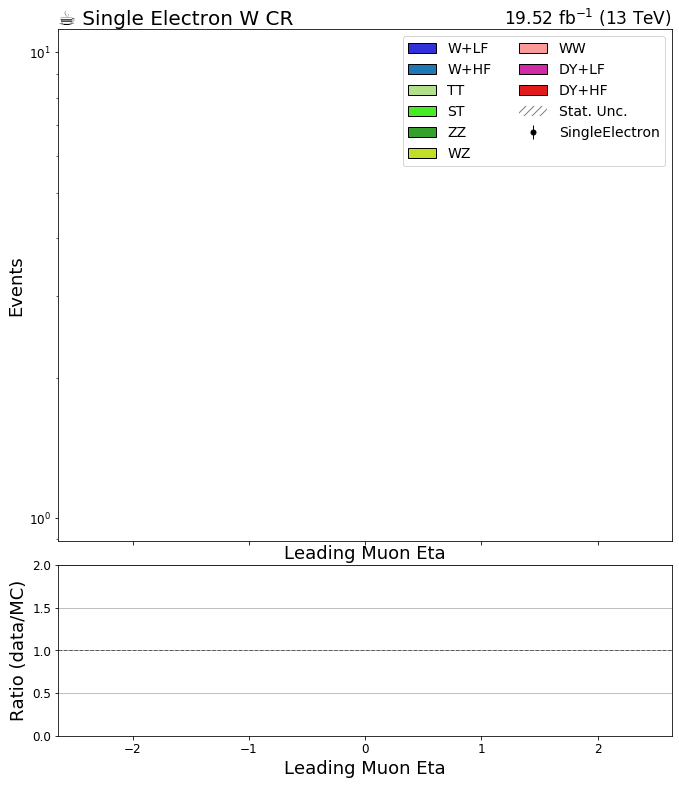

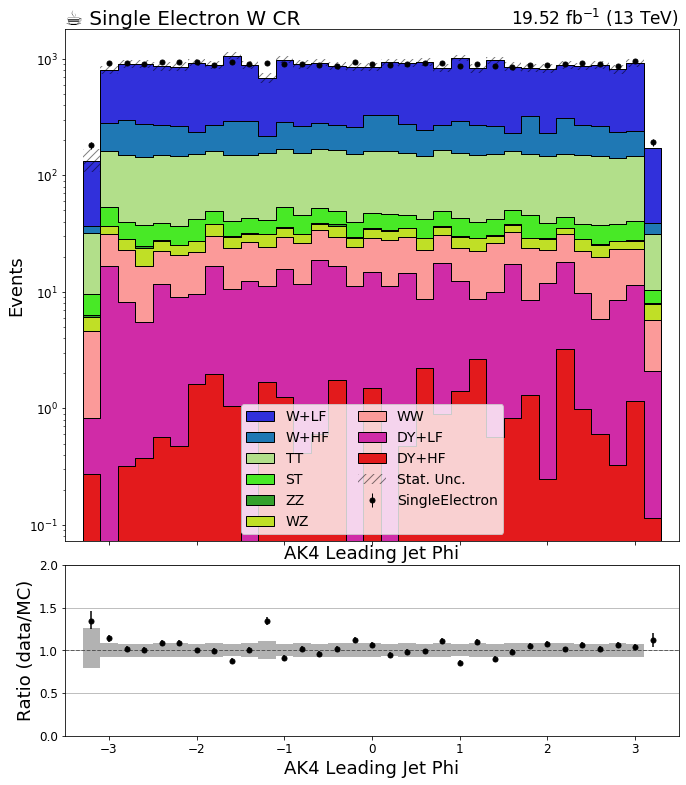

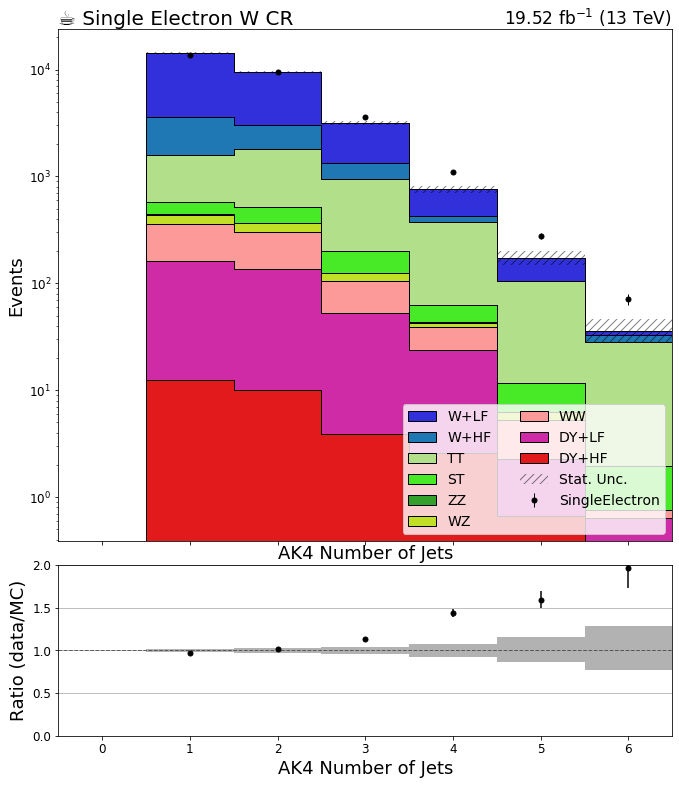

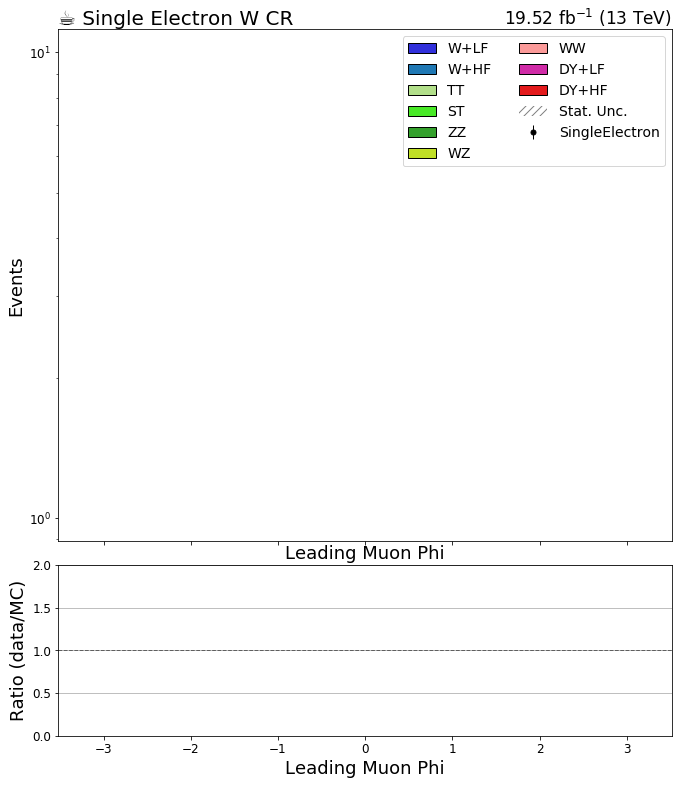

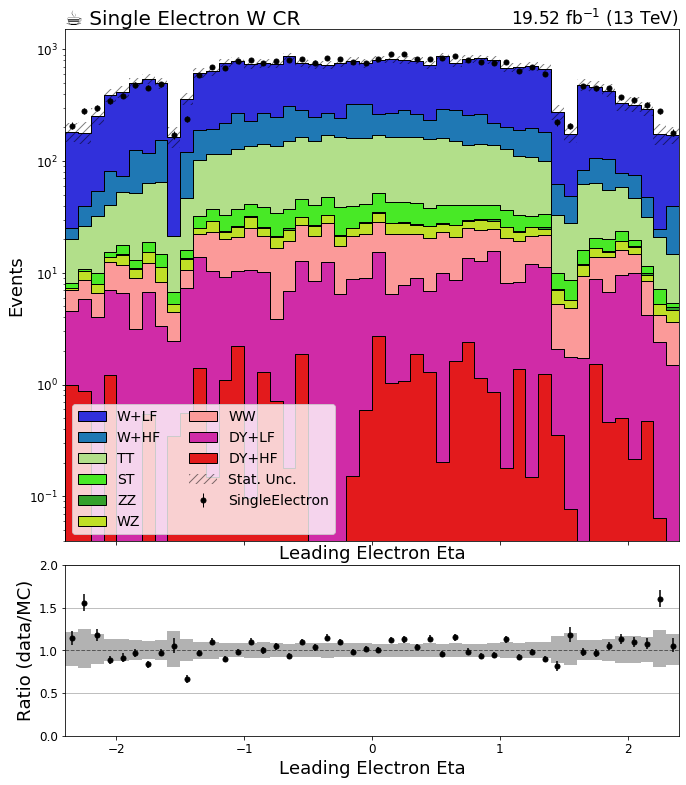

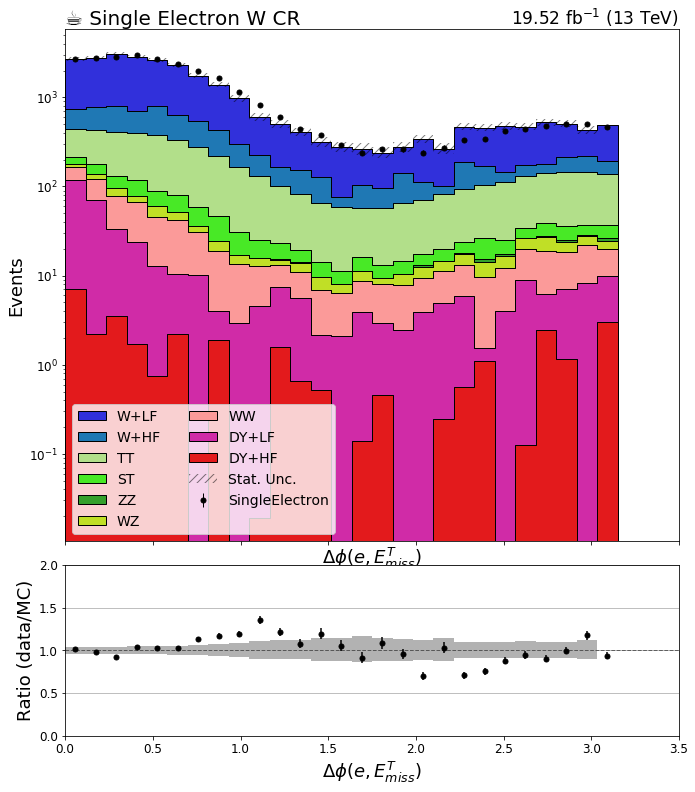

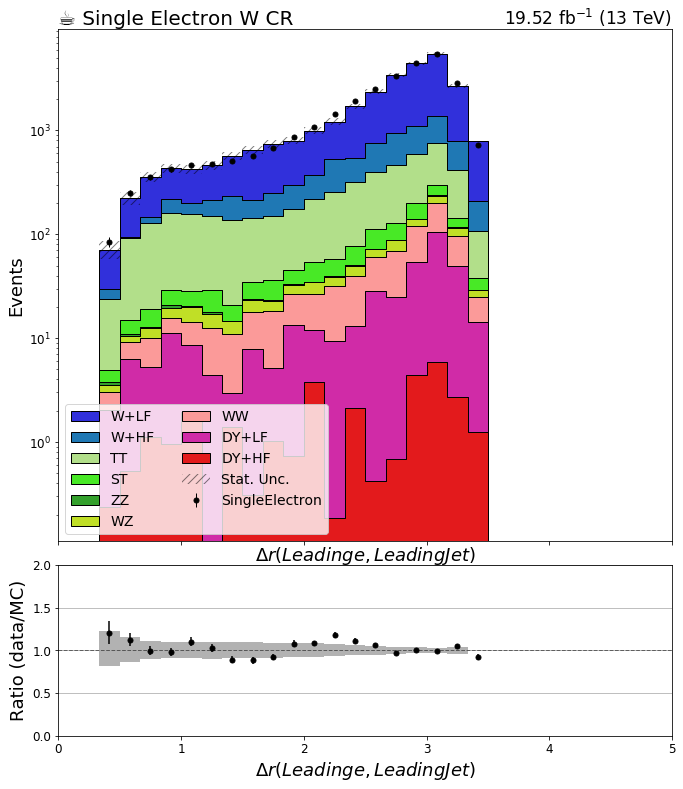

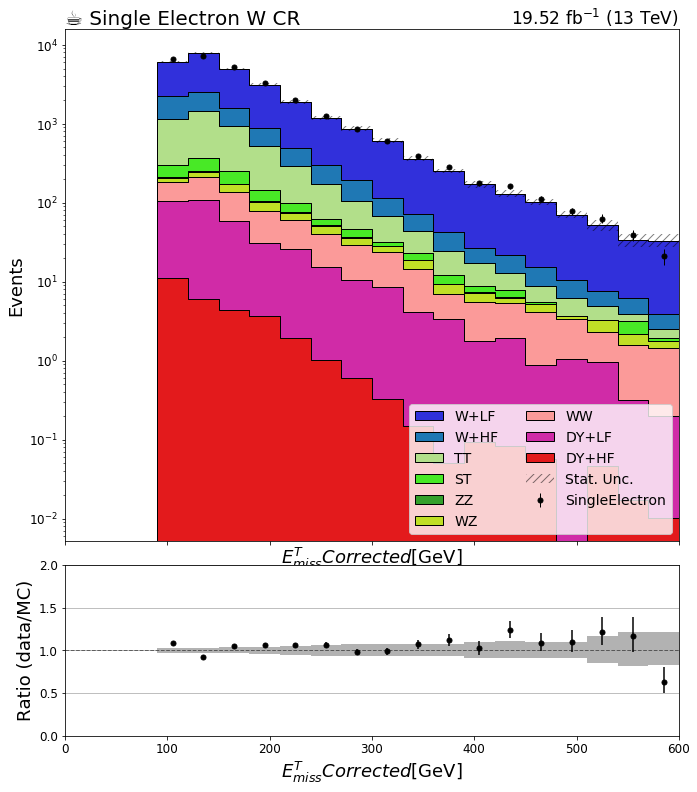

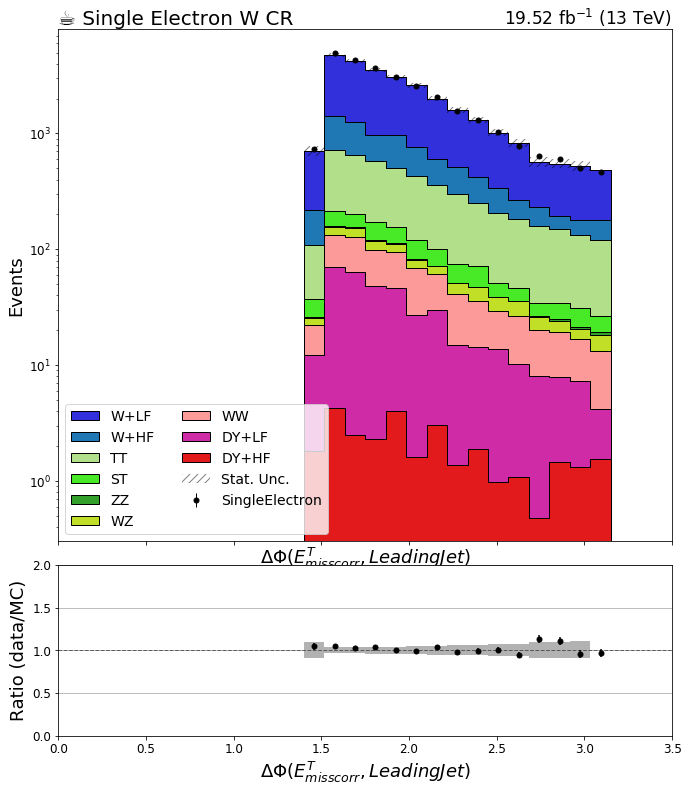

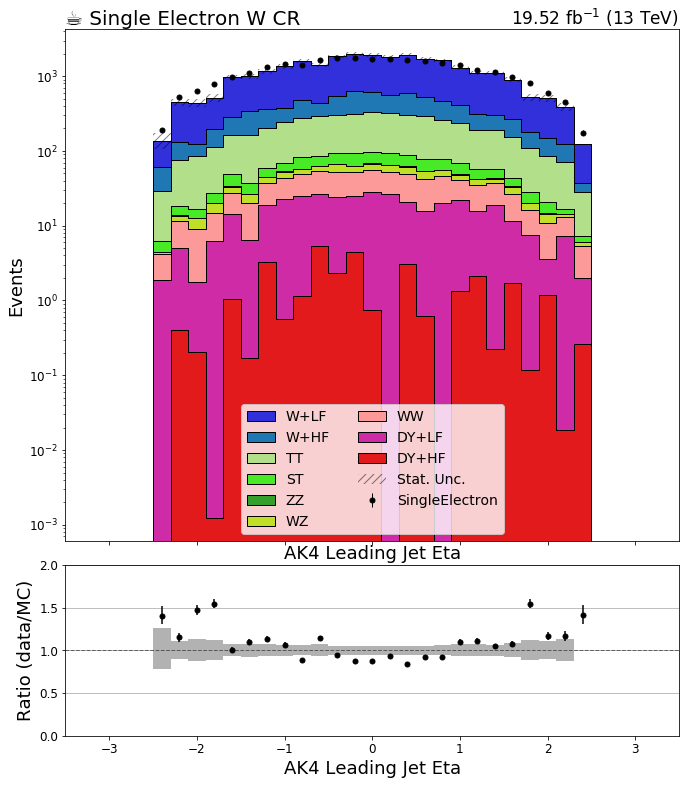

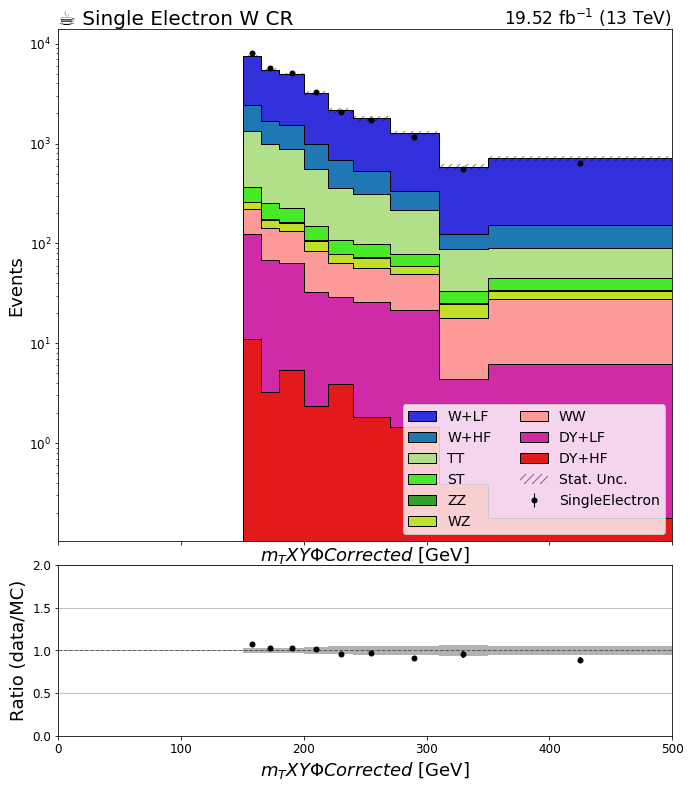

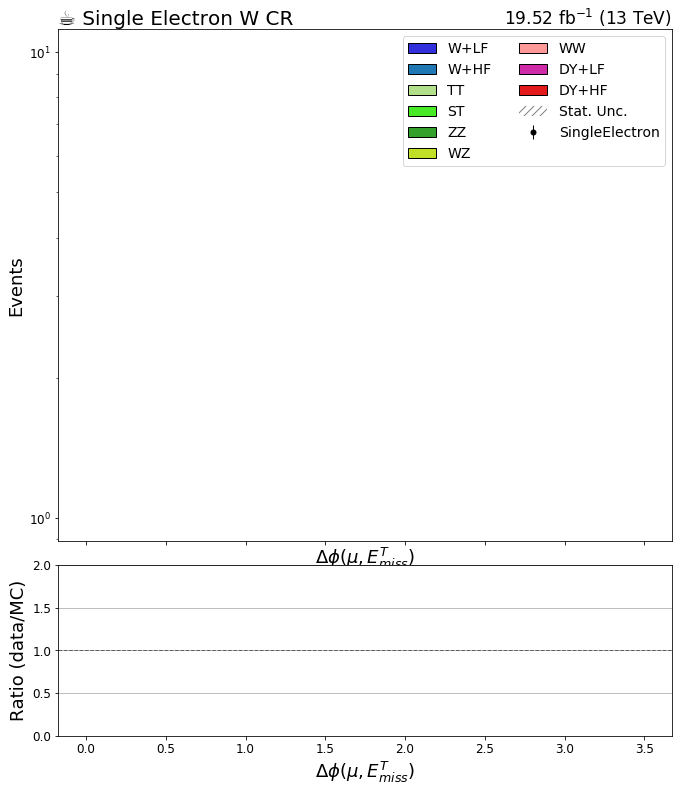

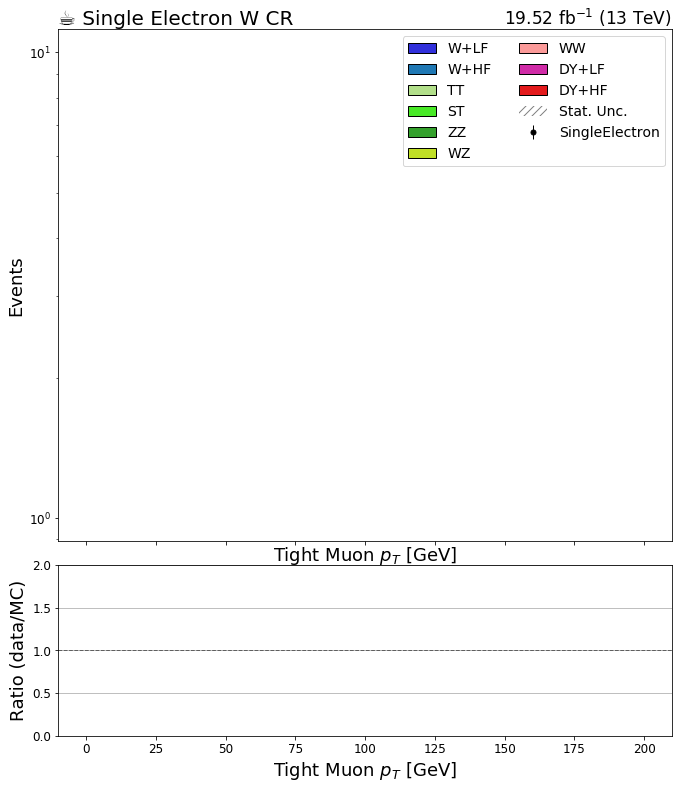

In [3]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2016'
region = 'wjete'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'dphi_Corr_Met_LJ' in key:continue
#     if 'mu_pT' in key:continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
#         print(j, key)
#         print(data_hists[key].integrate("systematic").integrate('region',j)[data[year][str(j)]].values())
        plot.plot1d(data_hists[key].integrate("systematic", sys).integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate("systematic", sys).integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('systematic','nominal').integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('systematic','nominal').integrate('region',j).sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"19.52 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic_preVFP'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic_preVFP'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

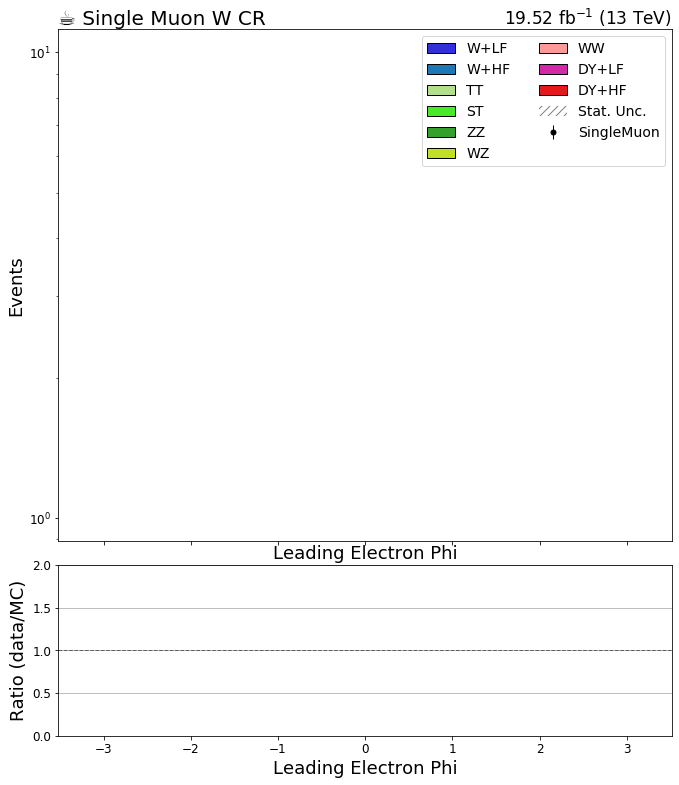

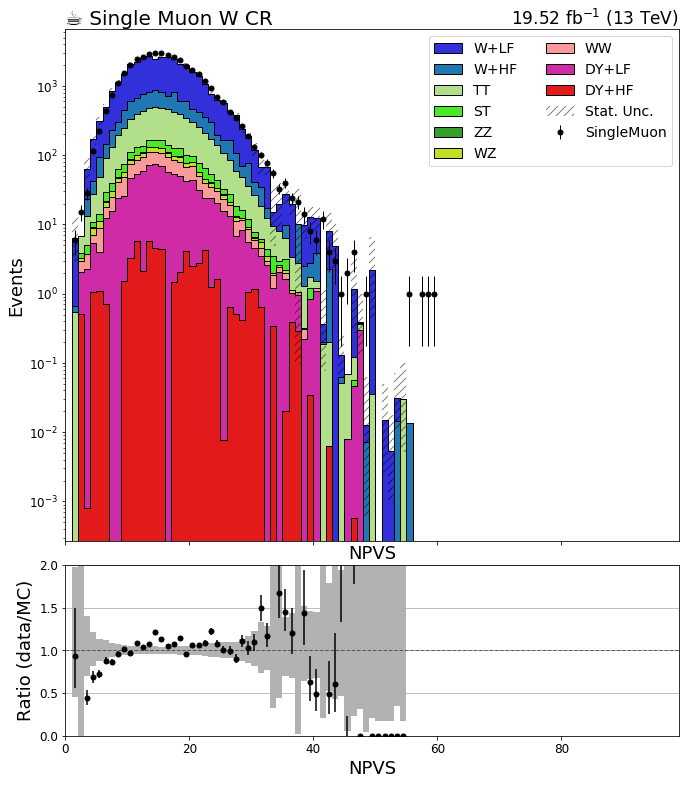

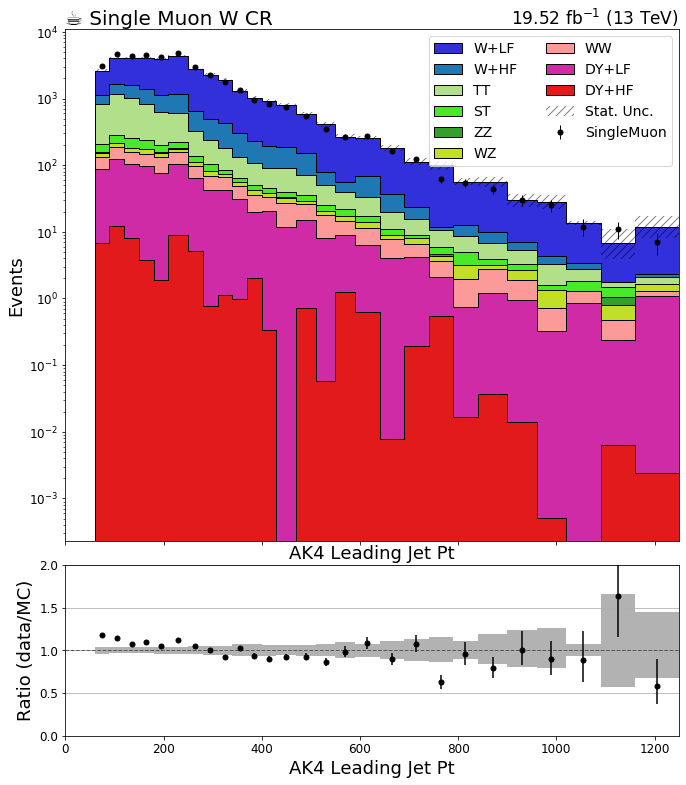

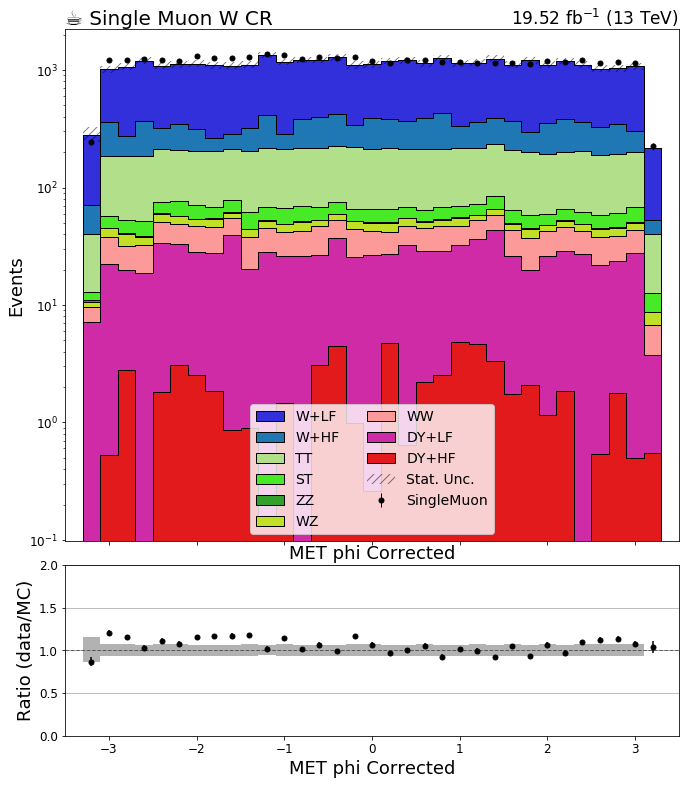

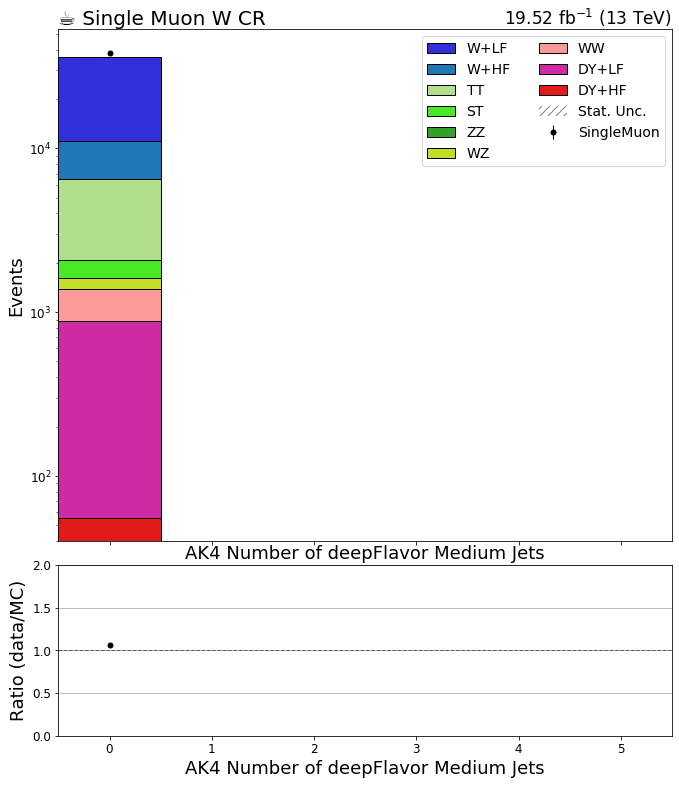

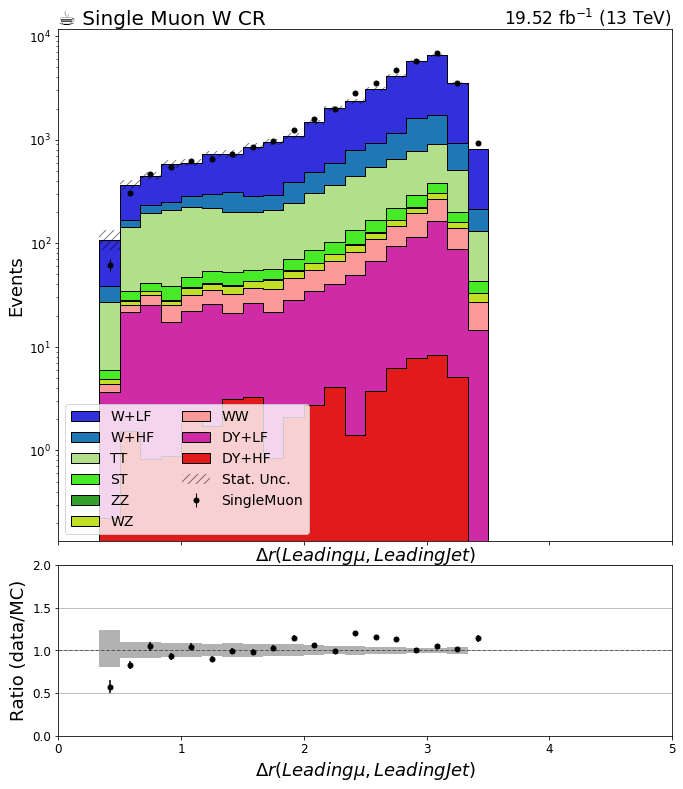

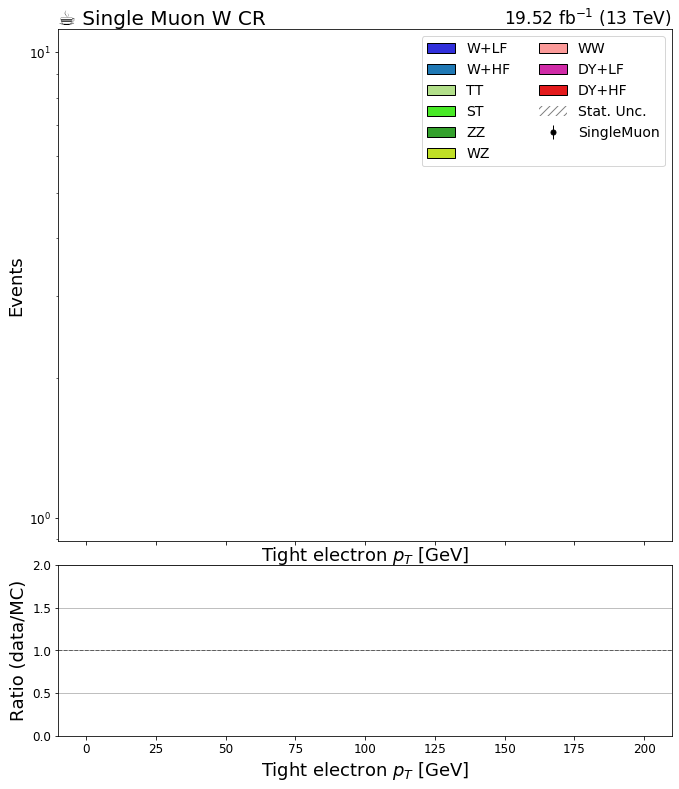

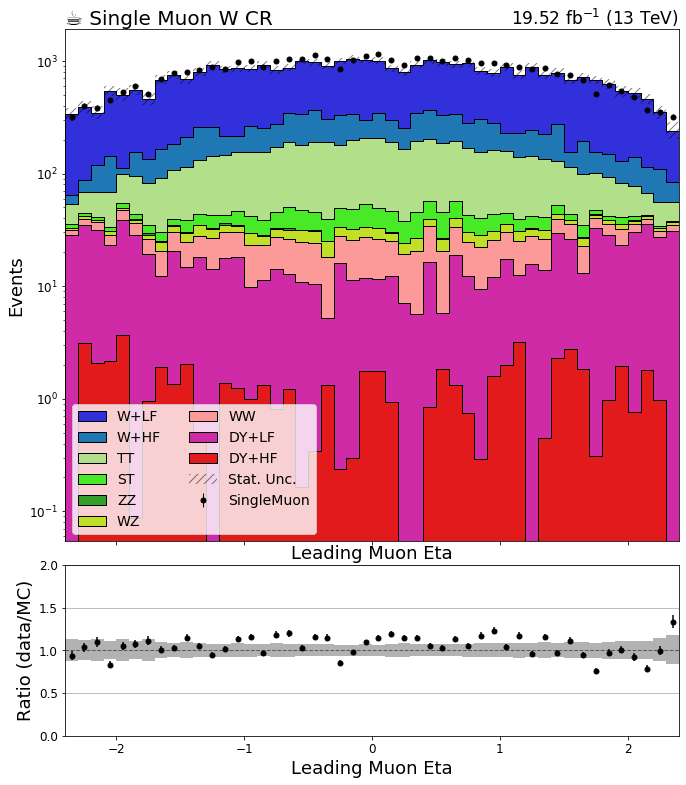

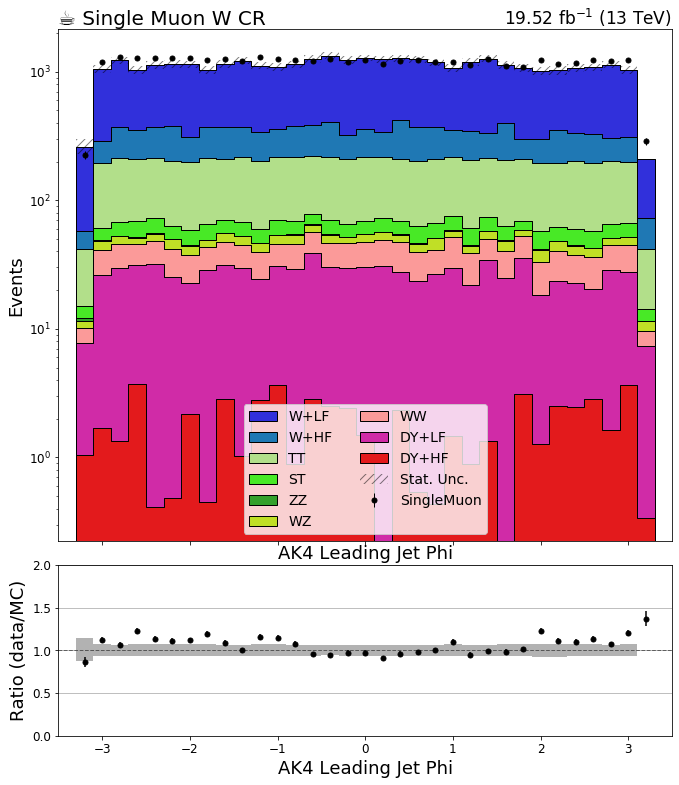

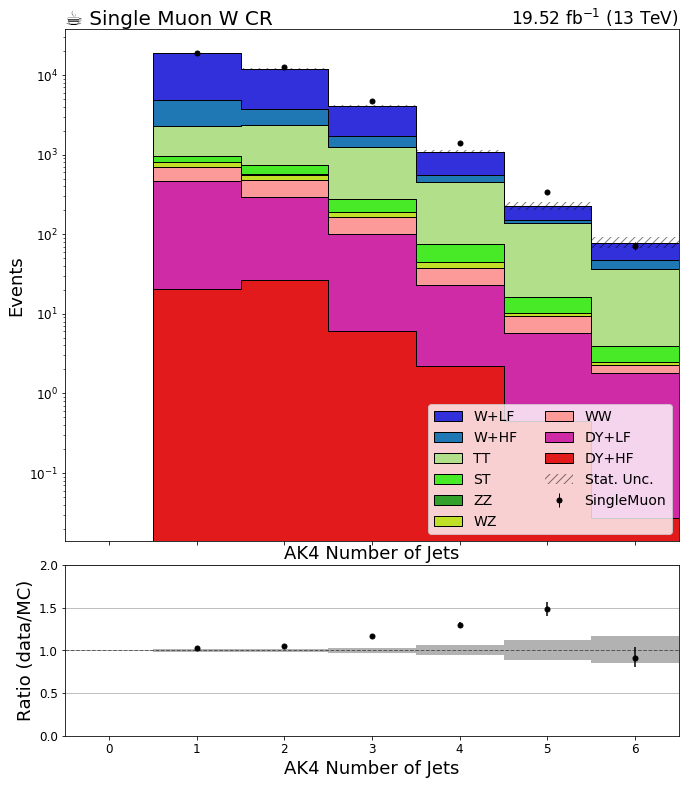

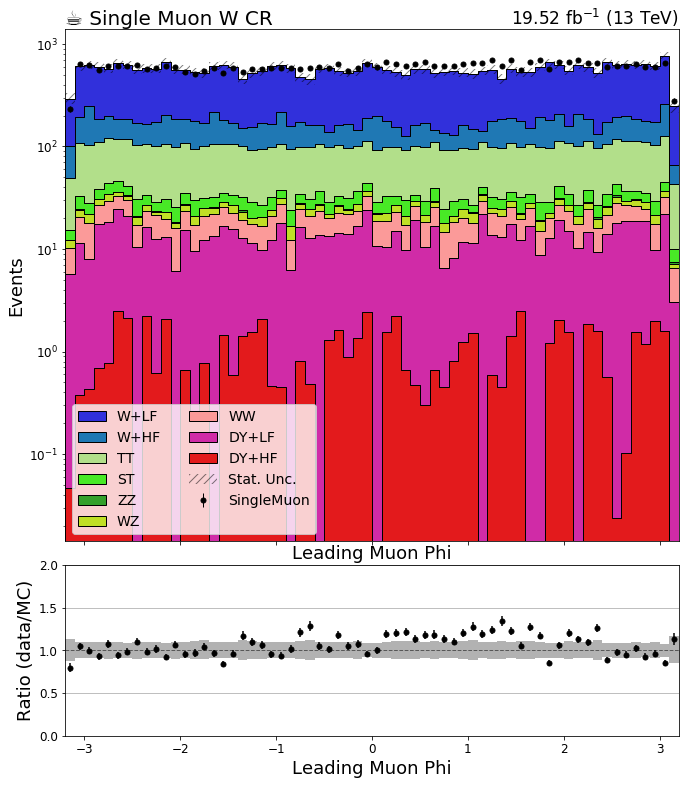

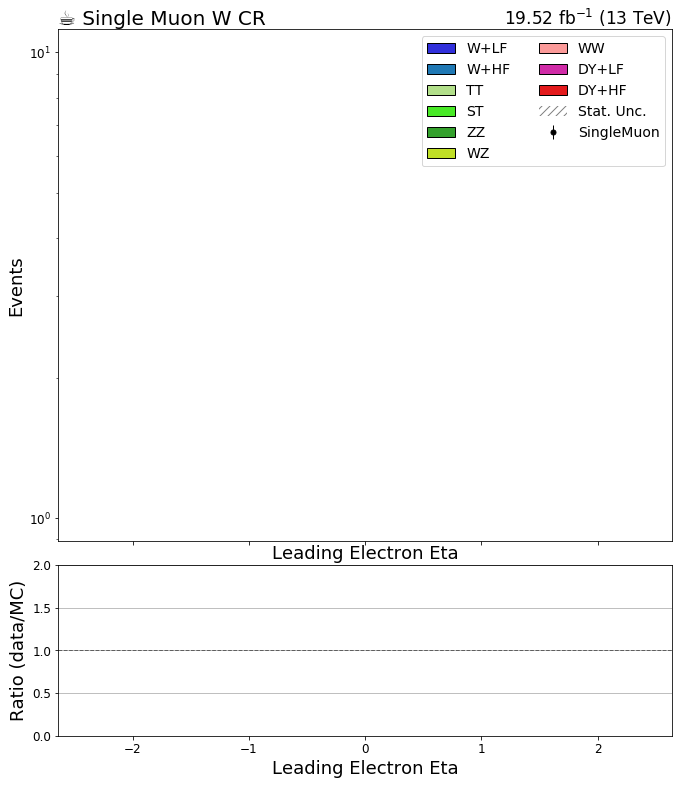

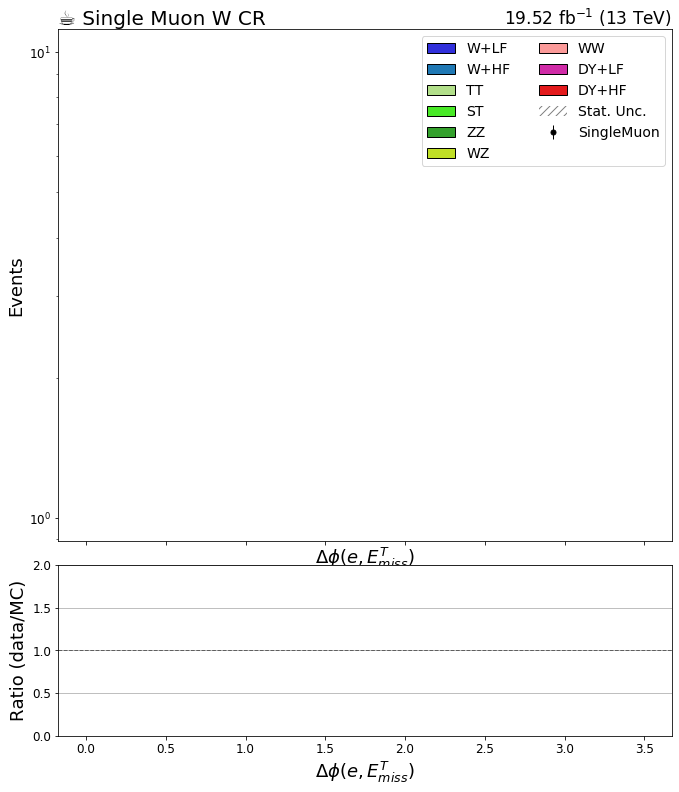

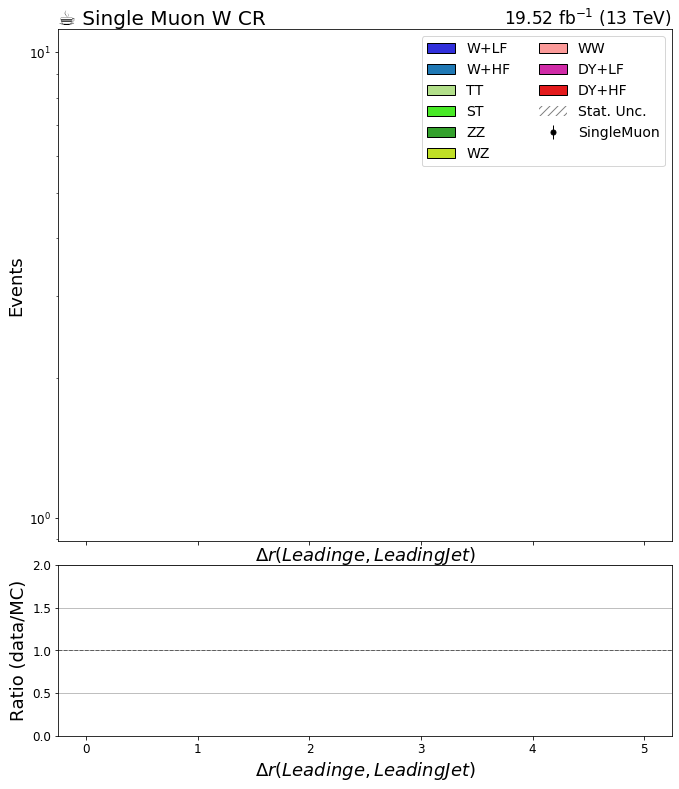

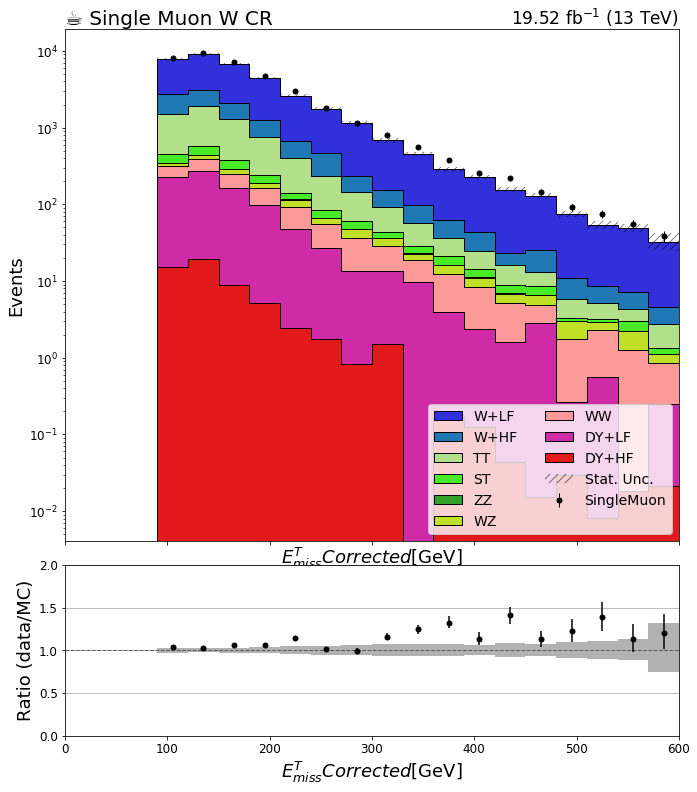

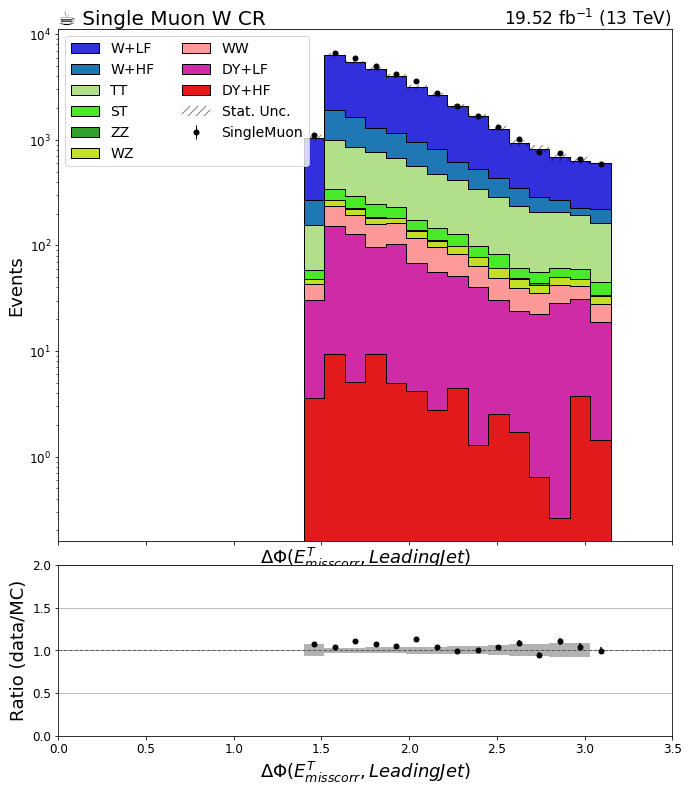

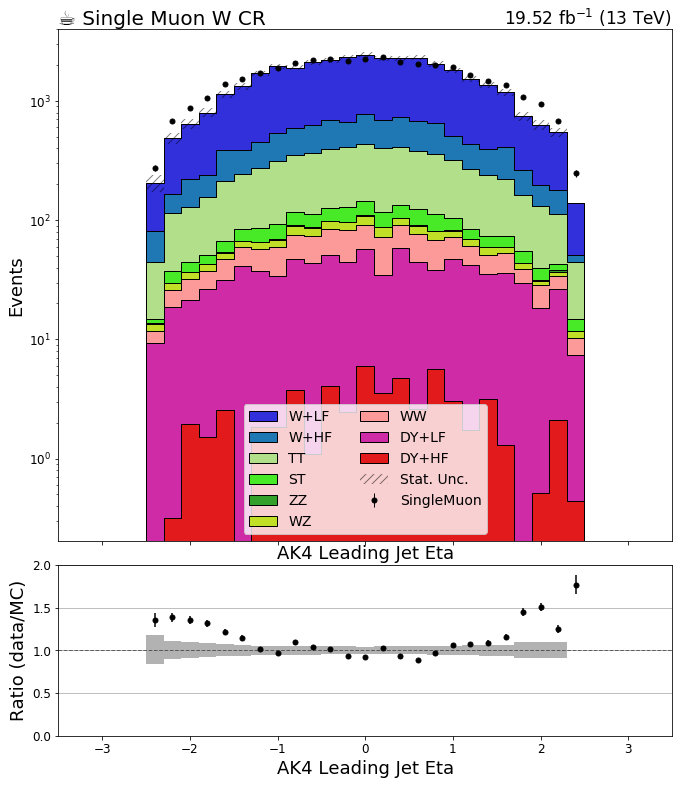

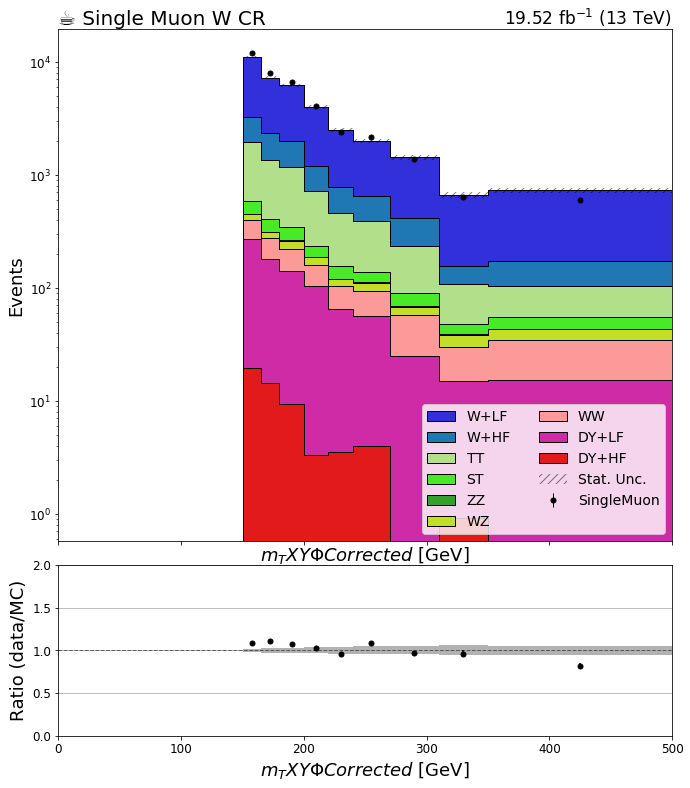

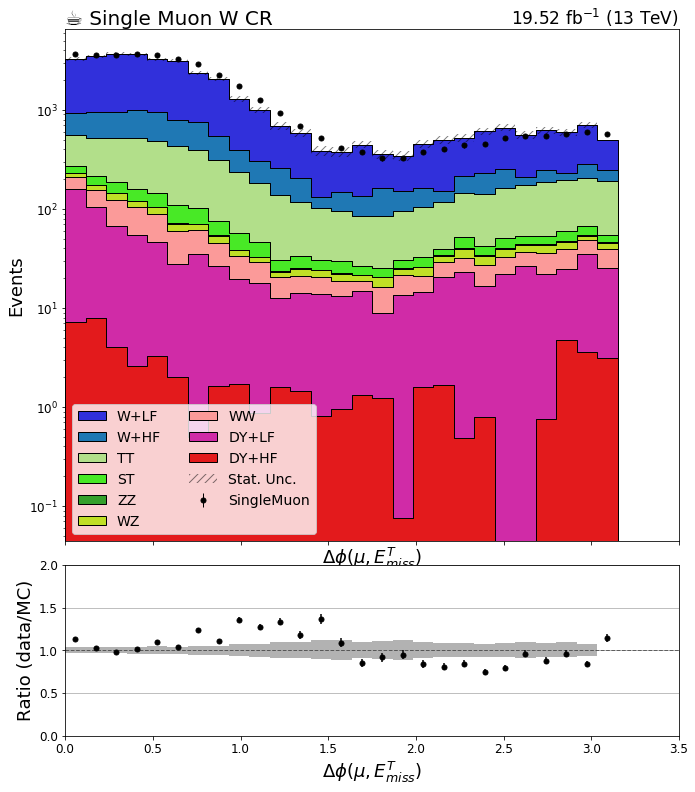

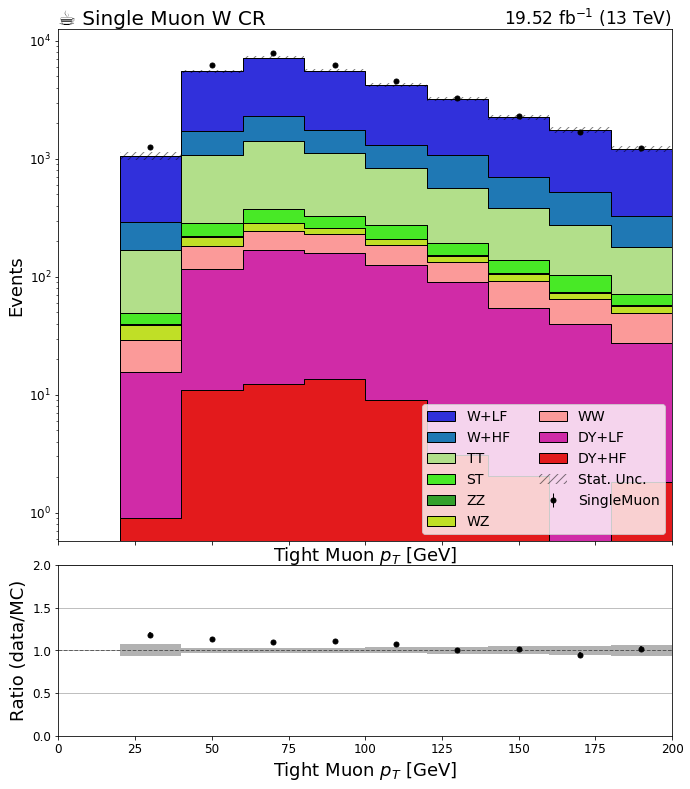

In [4]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2016'
region = 'wjetm'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'corrected' in key:continue
#     if 'dphi_Corr_Met_LJ' in key:continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate("systematic", sys).integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate("systematic", sys).integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate("systematic", sys).integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate("systematic", sys).integrate('region',j).sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"19.52 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic_preVFP'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic_preVFP'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

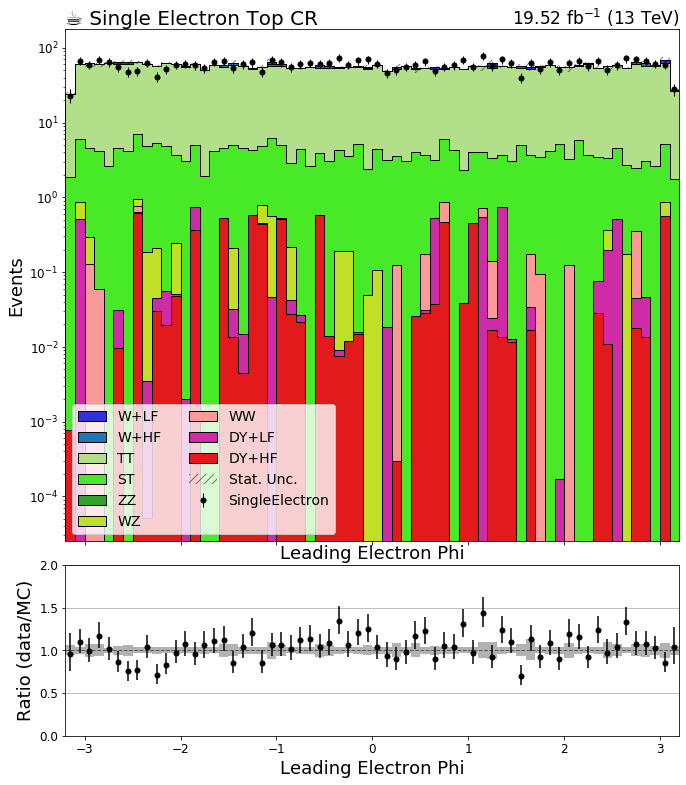

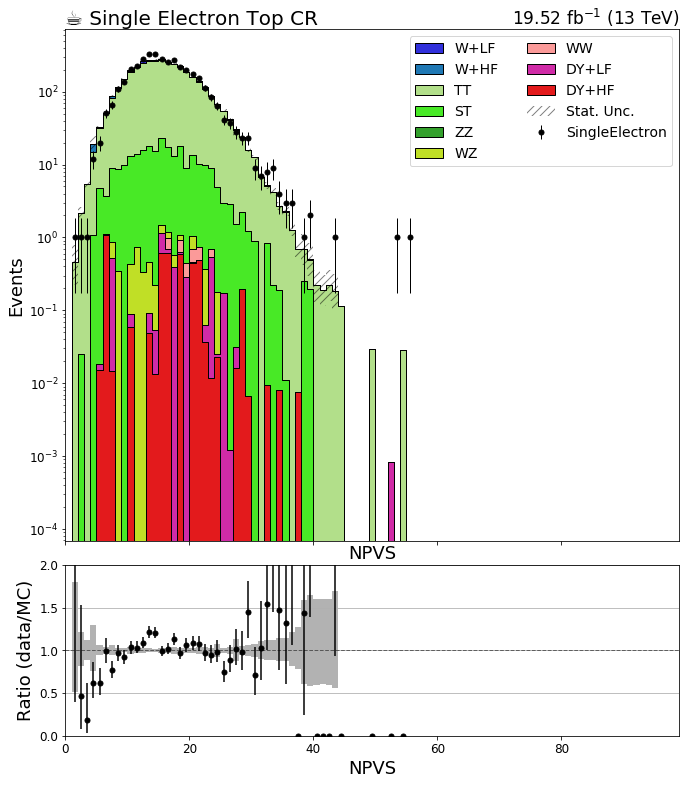

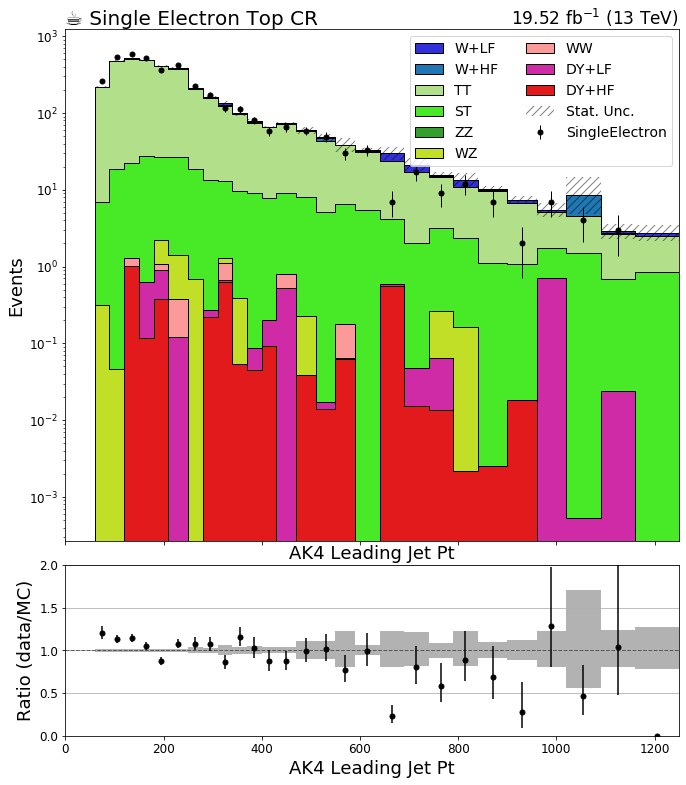

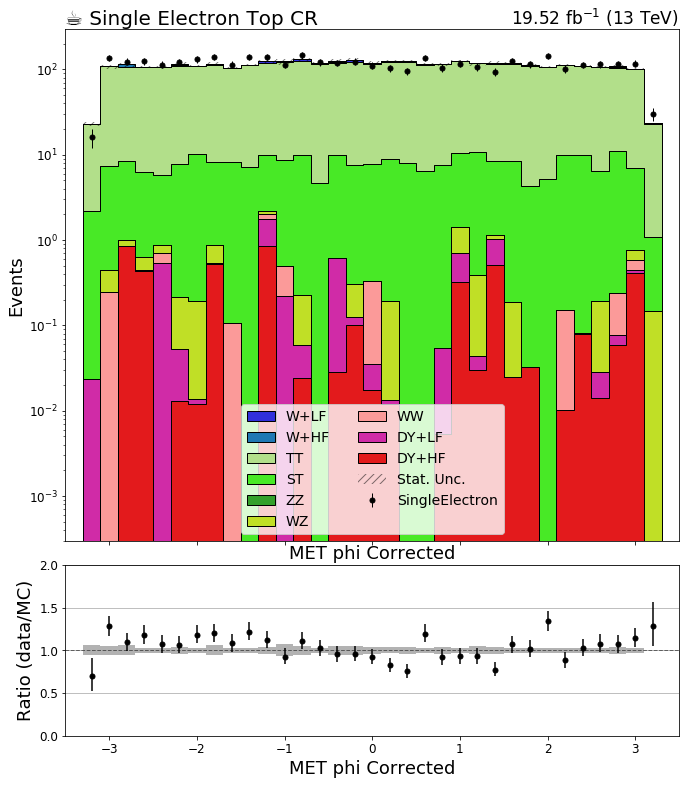

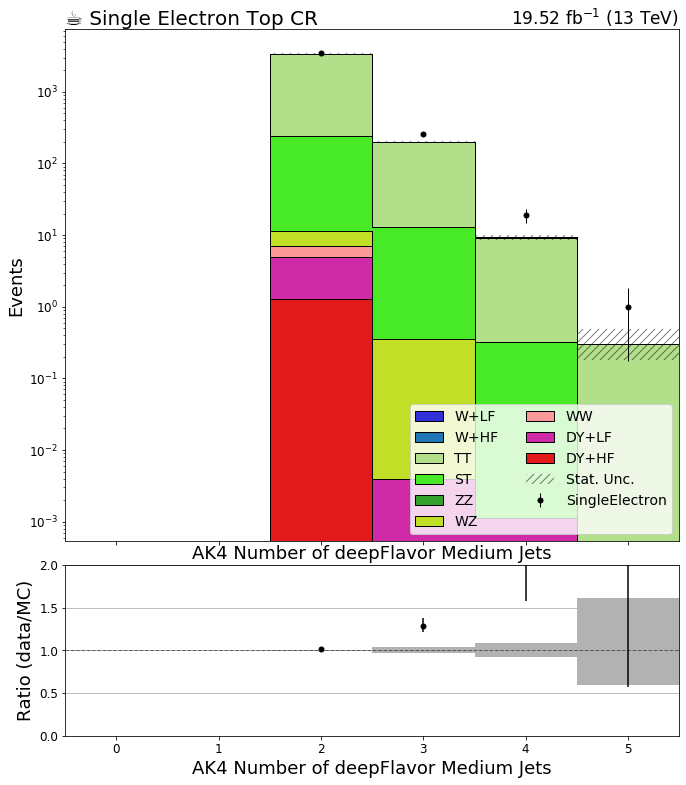

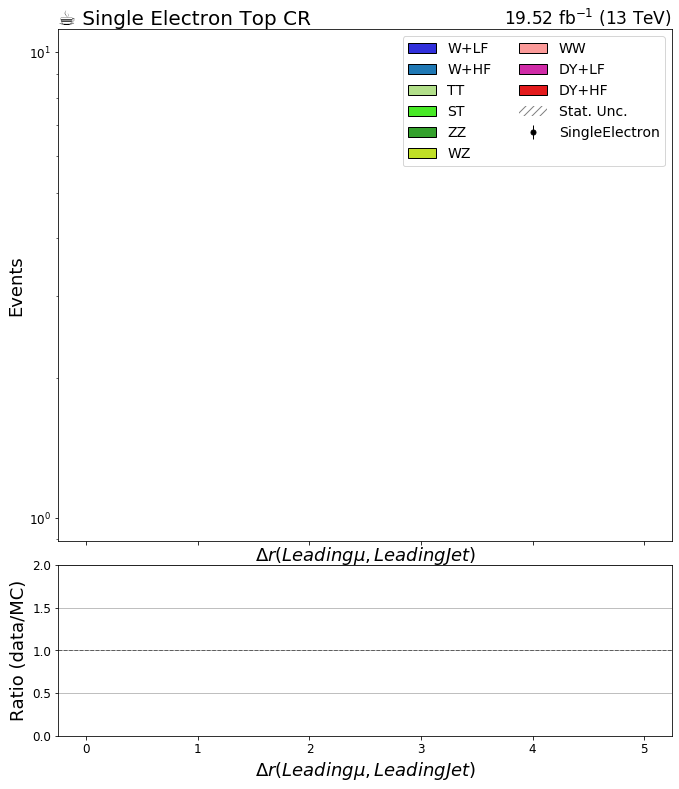

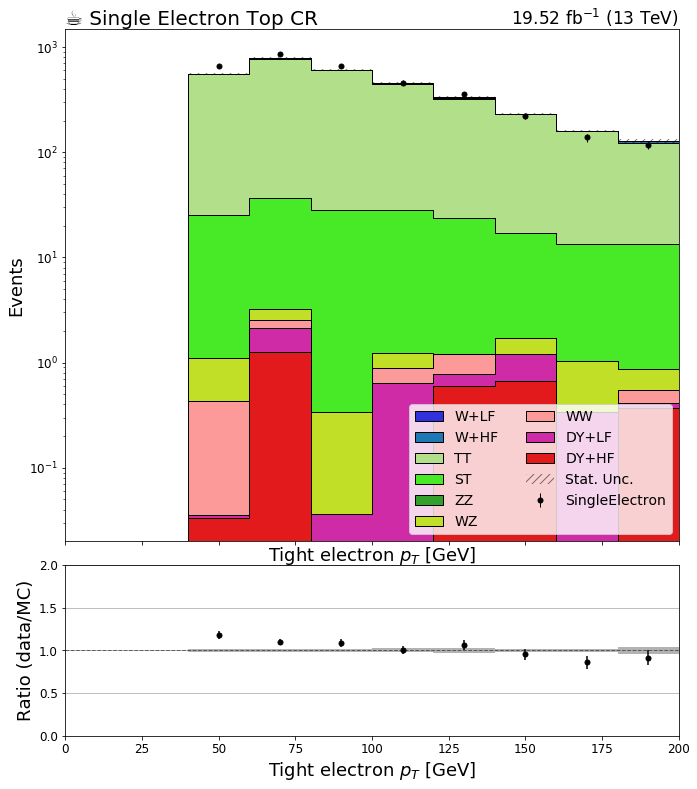

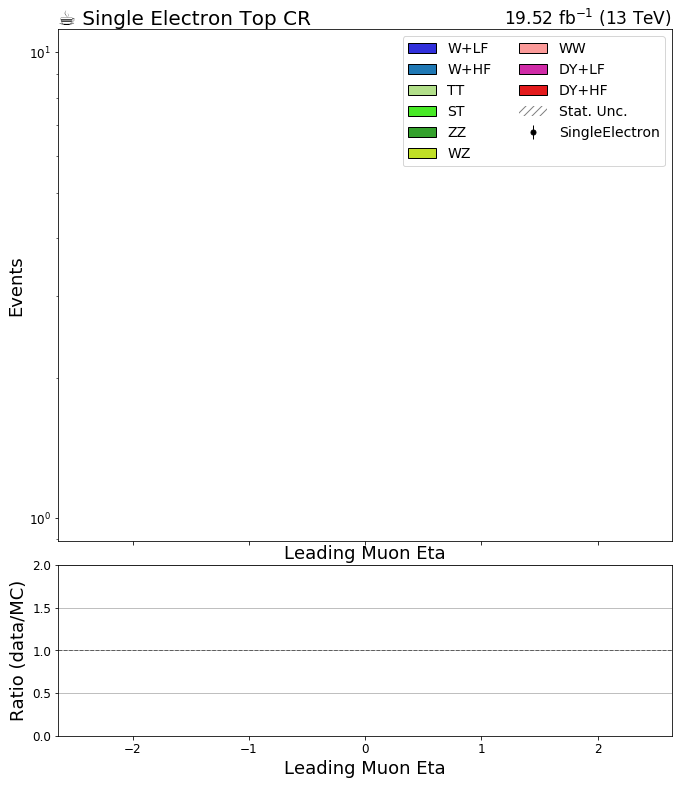

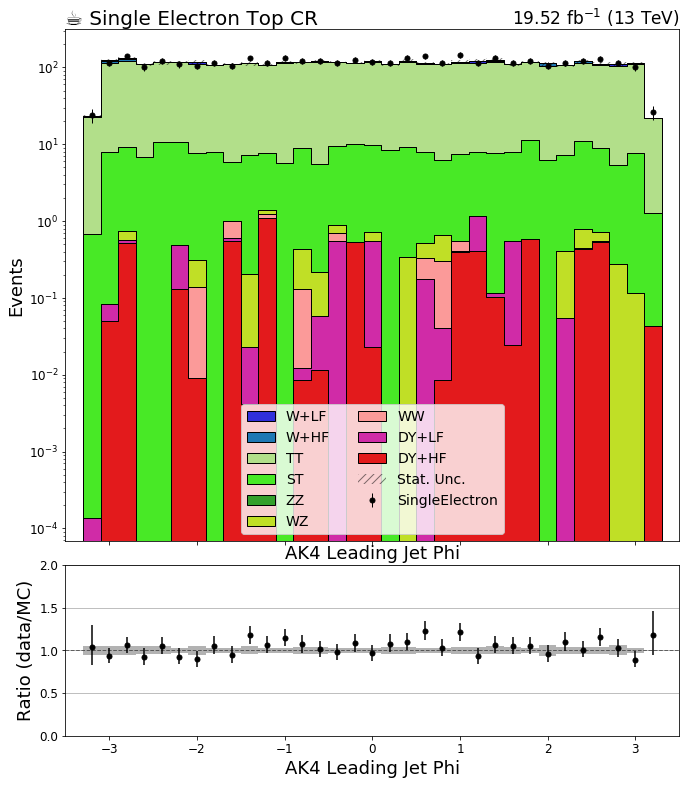

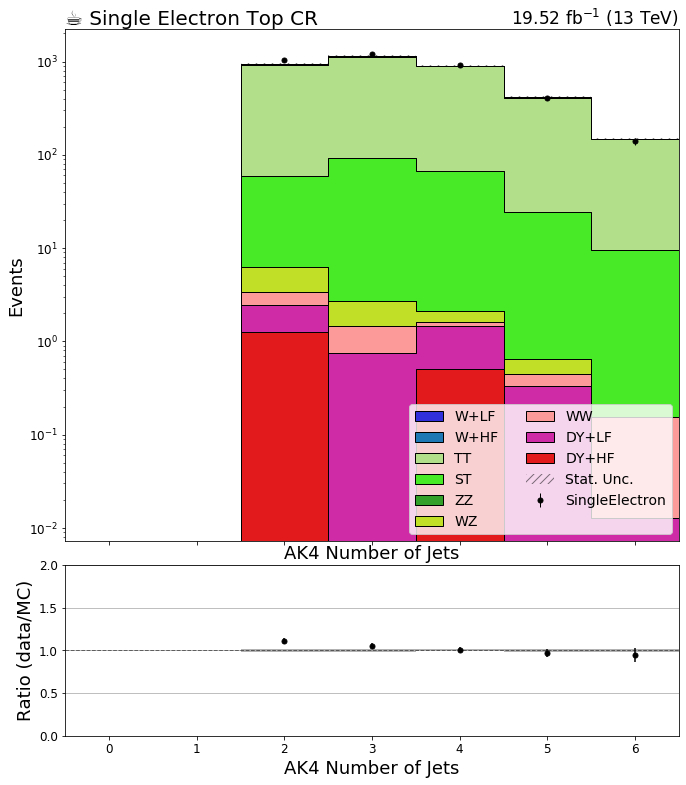

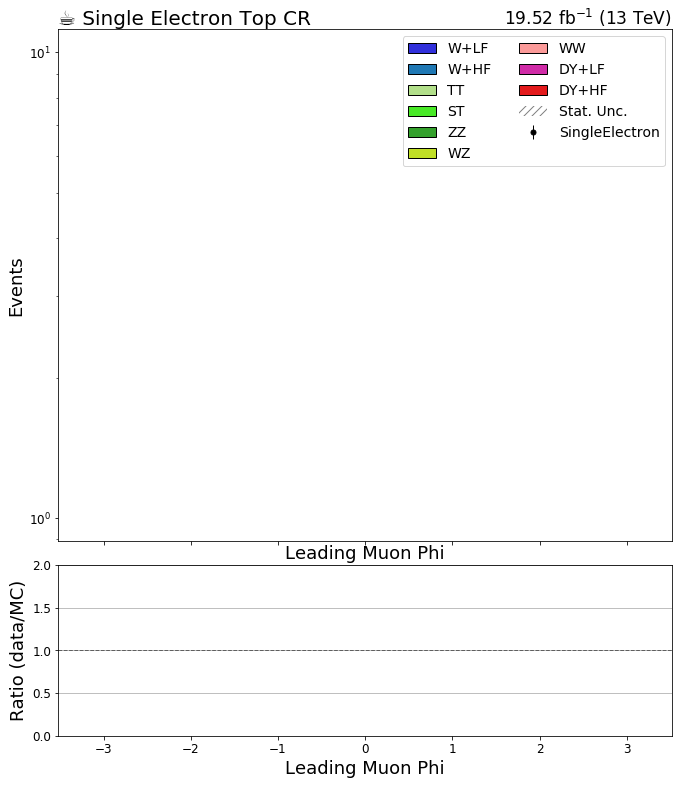

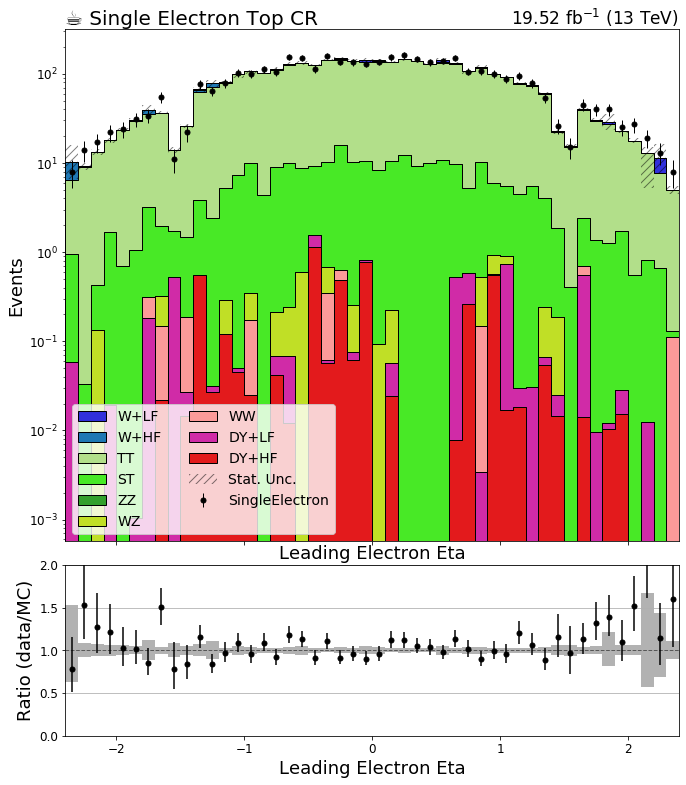

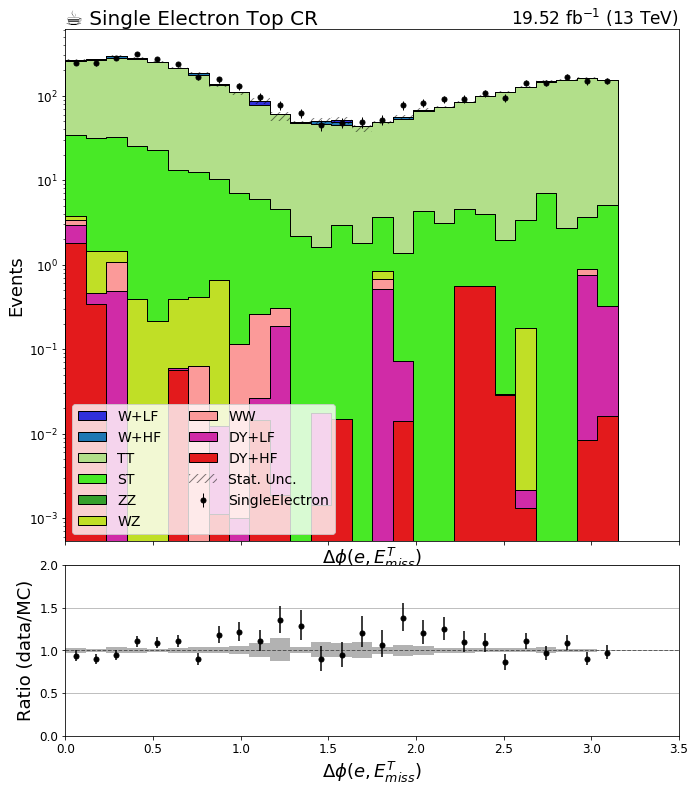

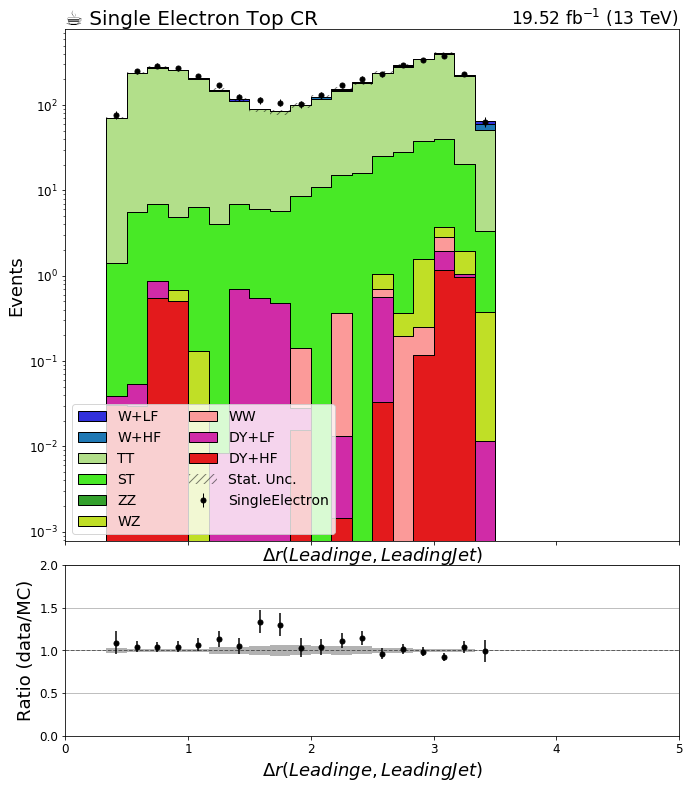

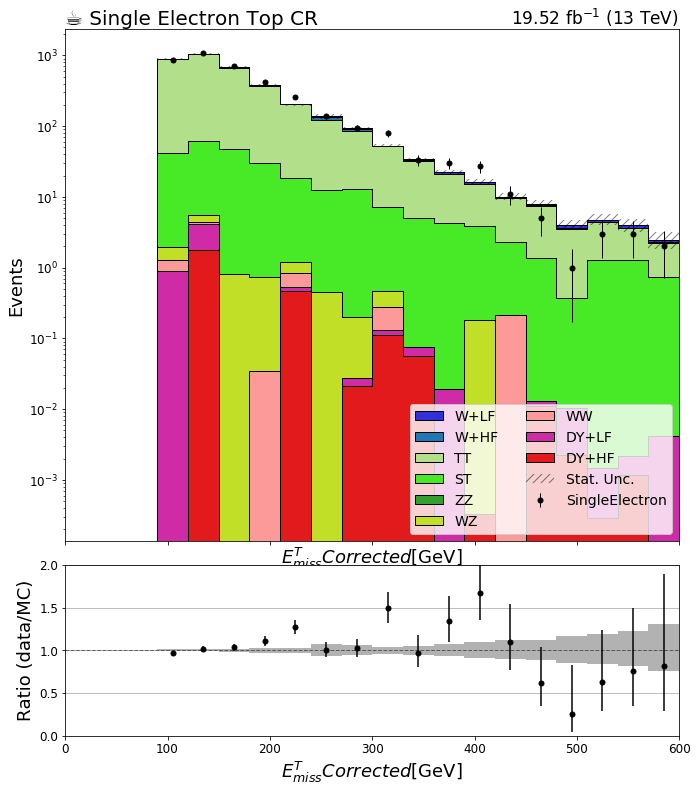

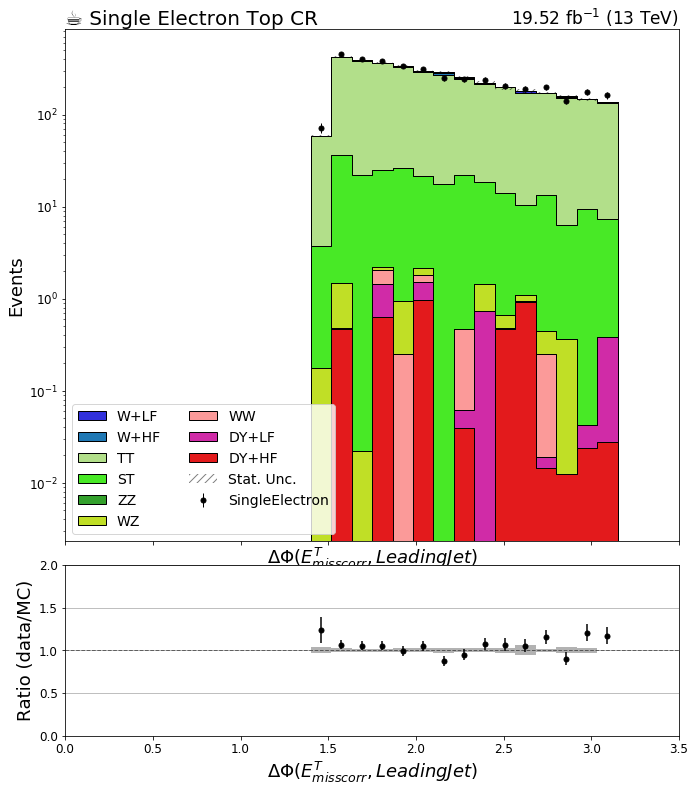

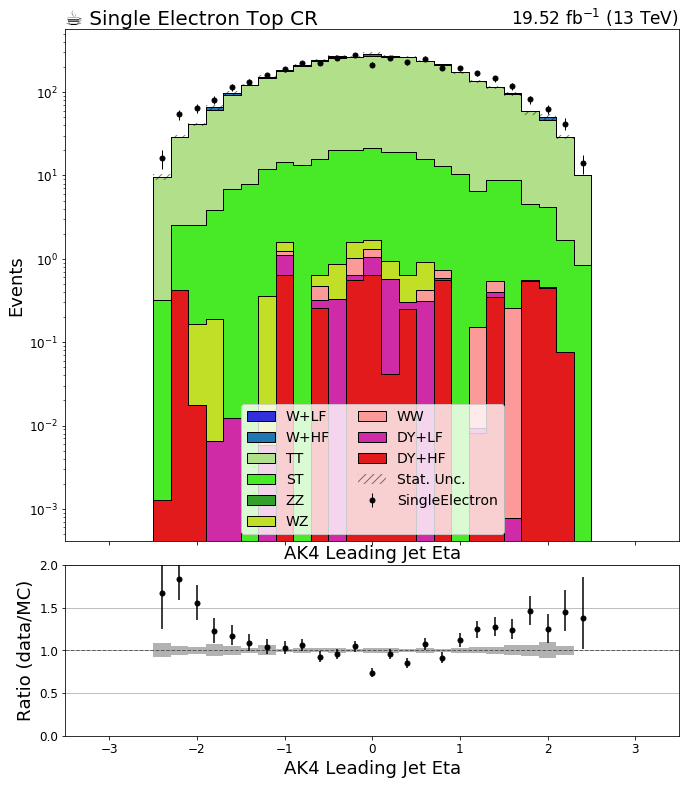

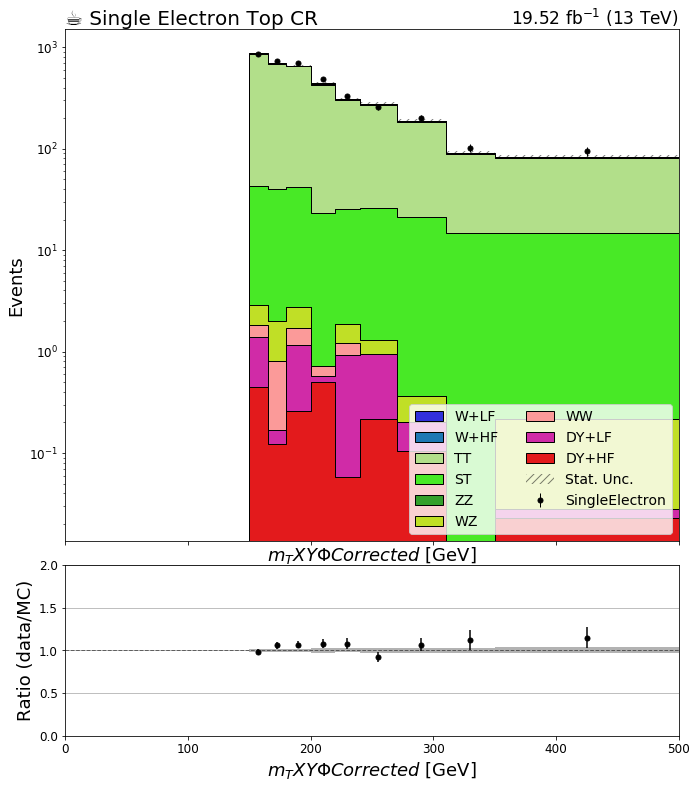

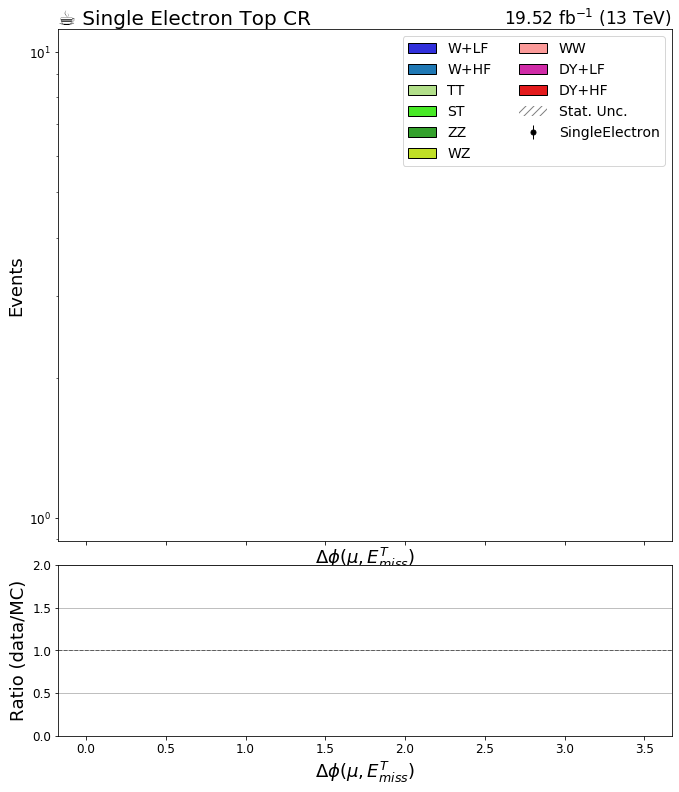

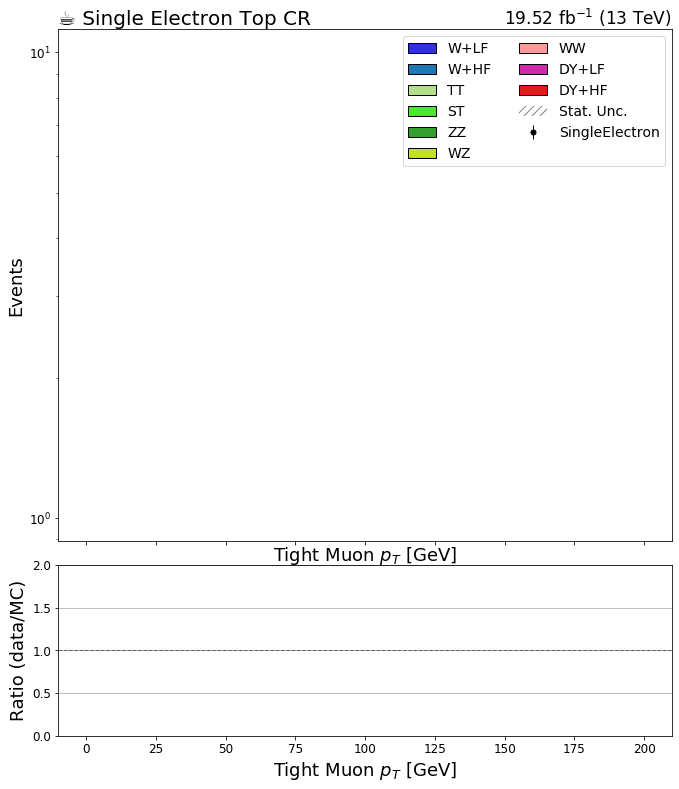

In [5]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2016'
region = 'ttbare'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'dphi_Corr_Met_LJ' in key:continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate("systematic").integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate("systematic", sys).integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate("systematic", sys).integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate("systematic", sys).integrate('region',j).sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"19.52 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic_preVFP'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic_preVFP'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

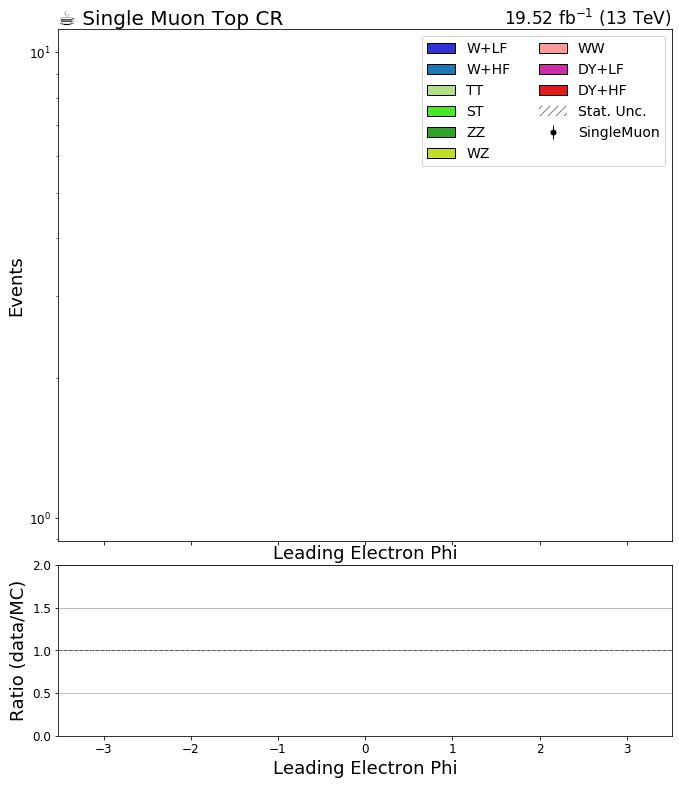

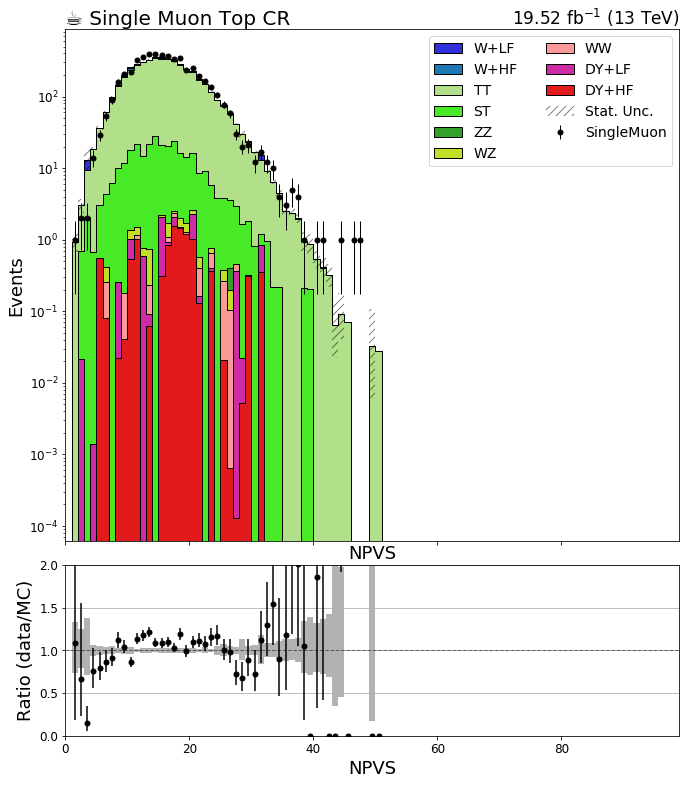

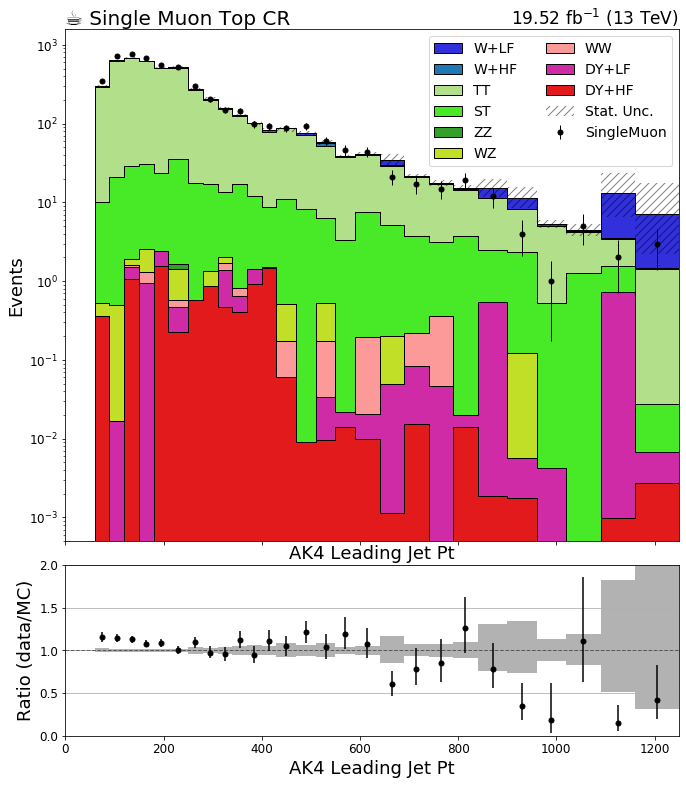

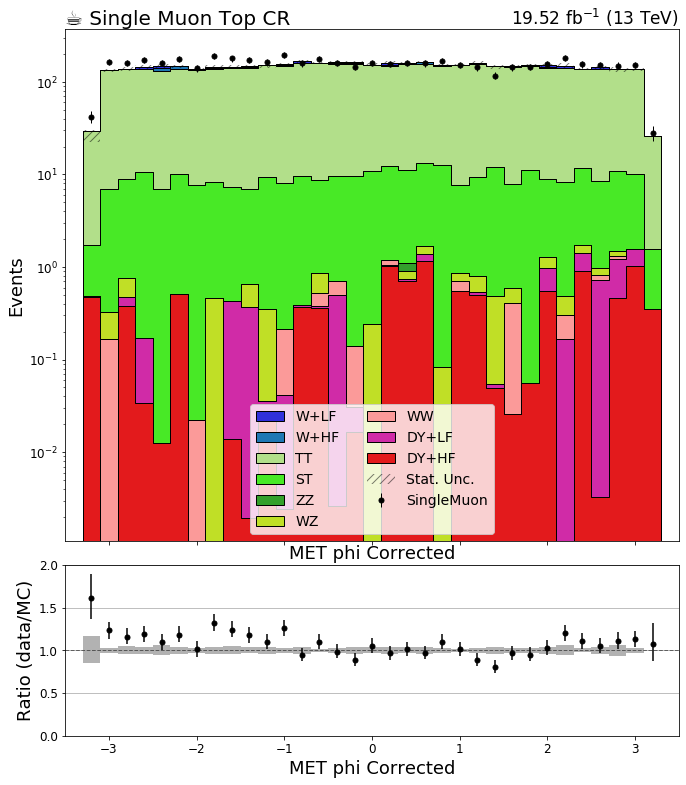

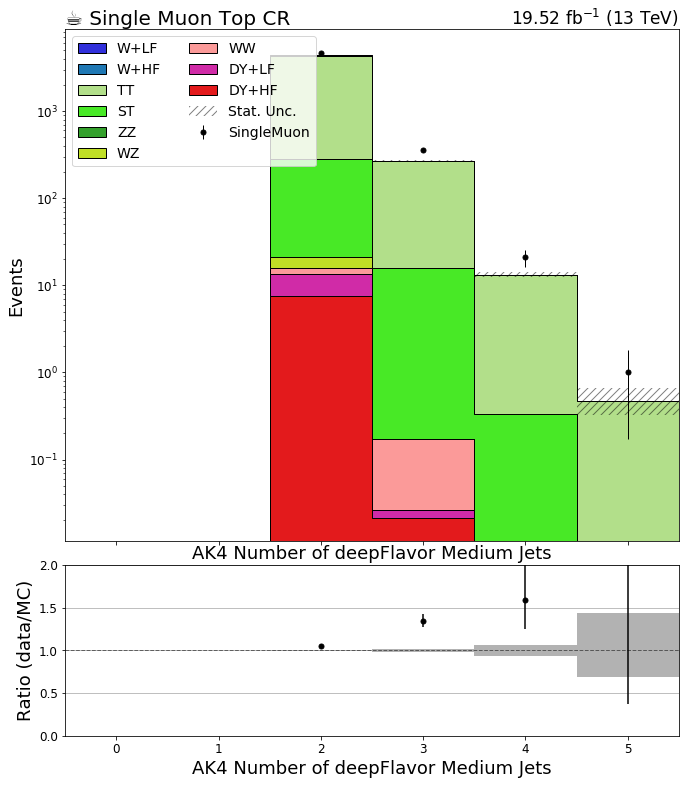

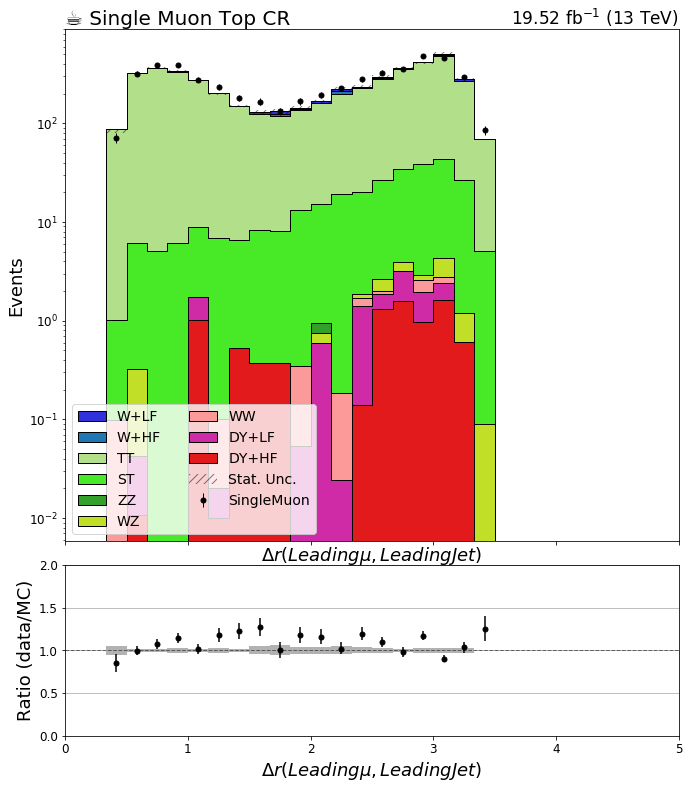

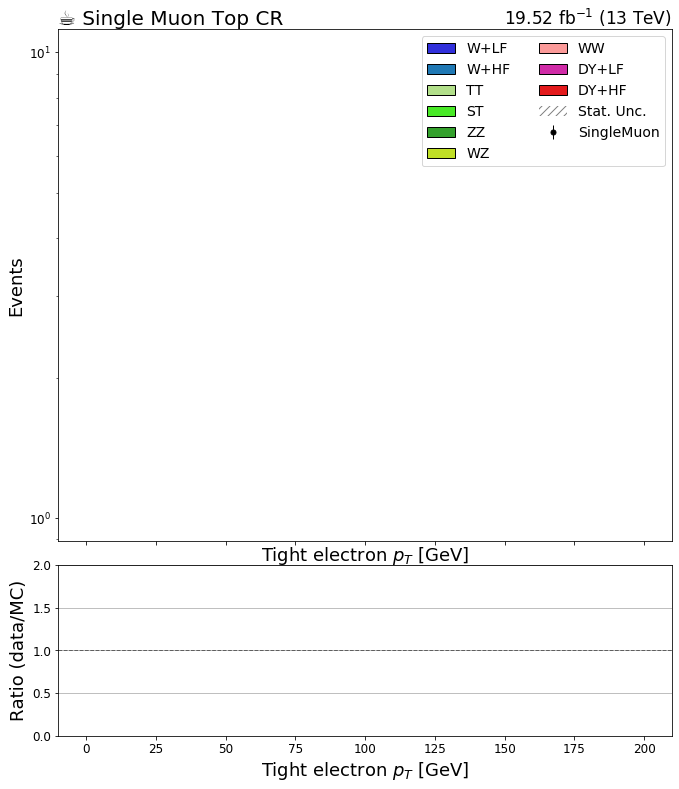

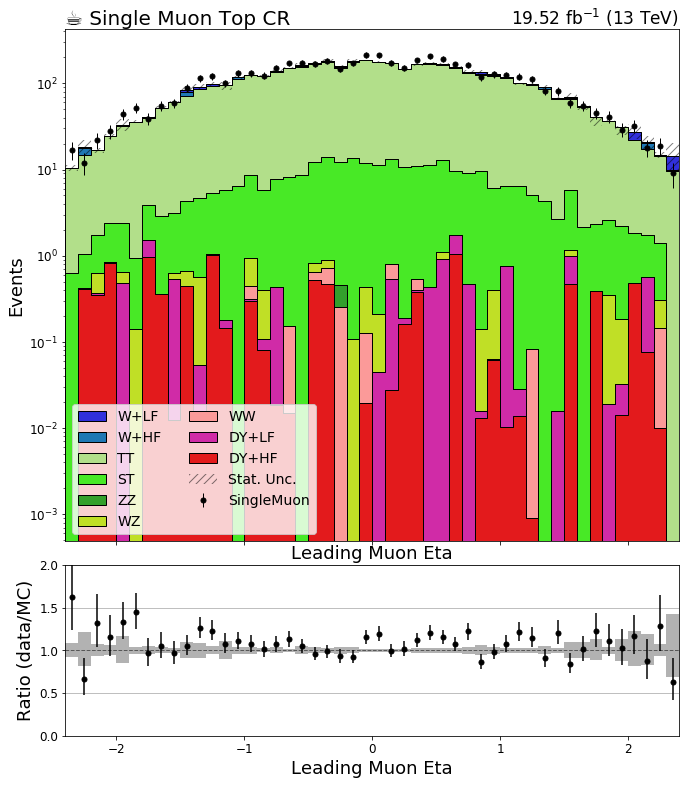

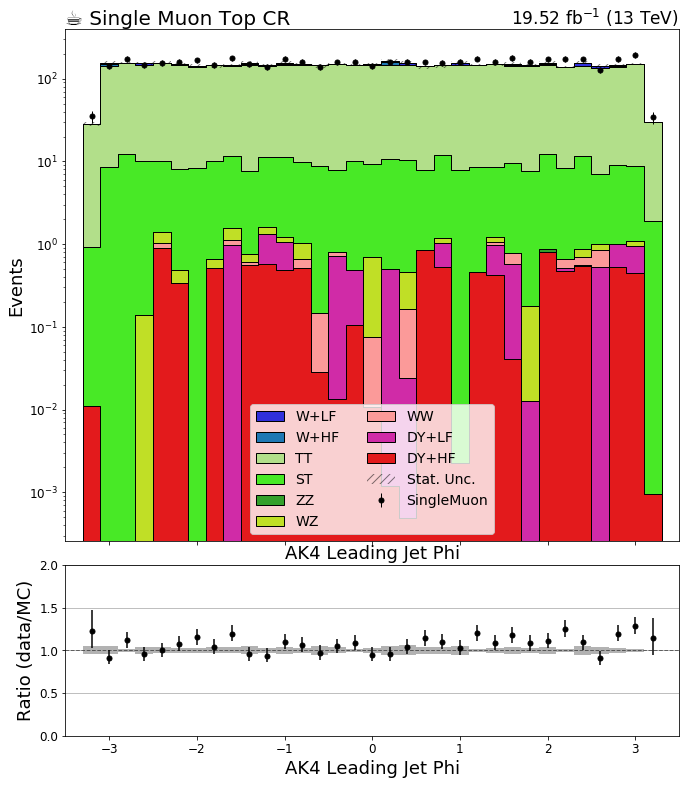

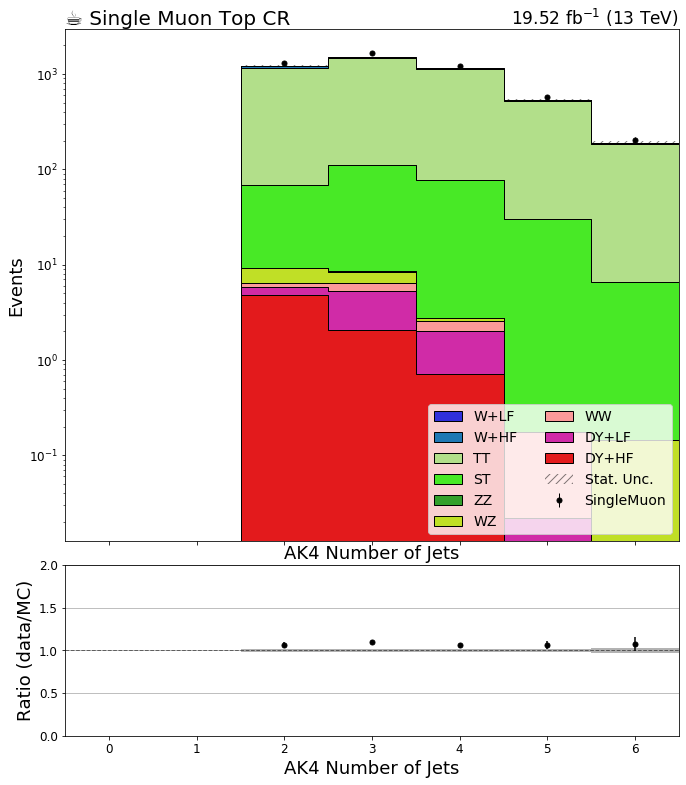

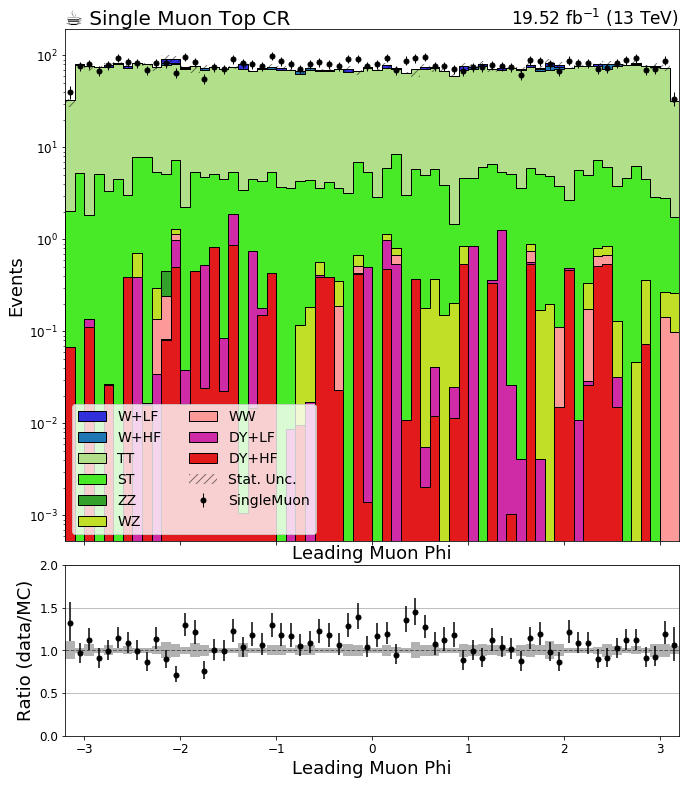

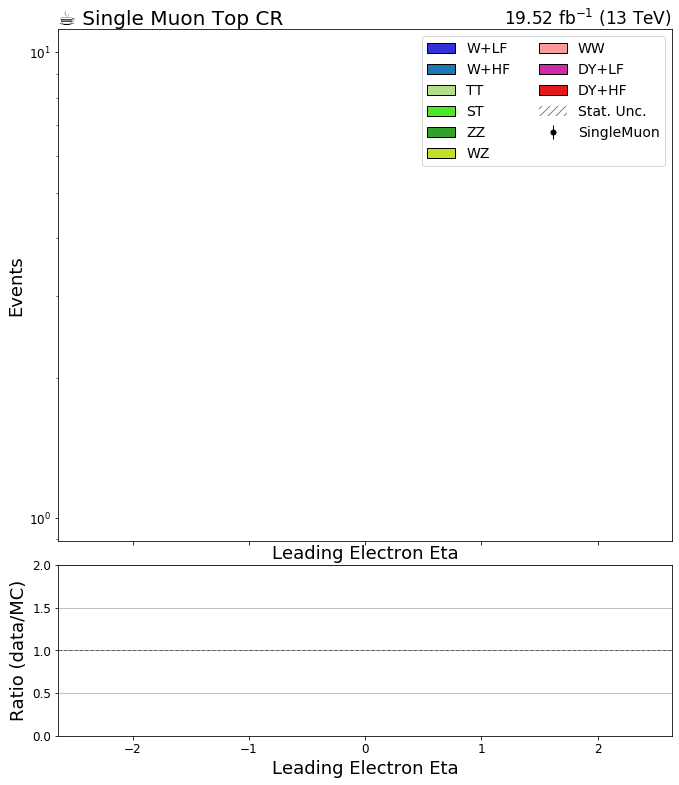

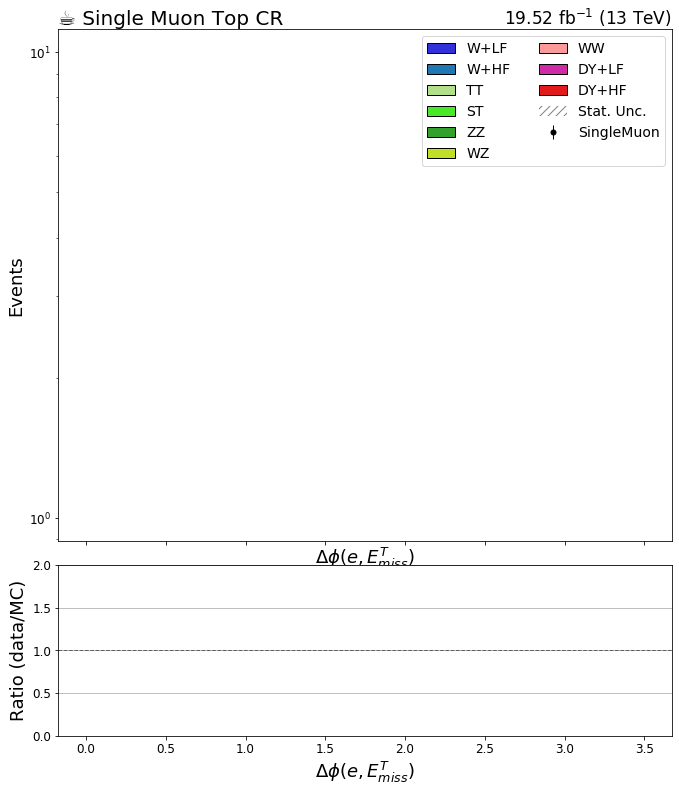

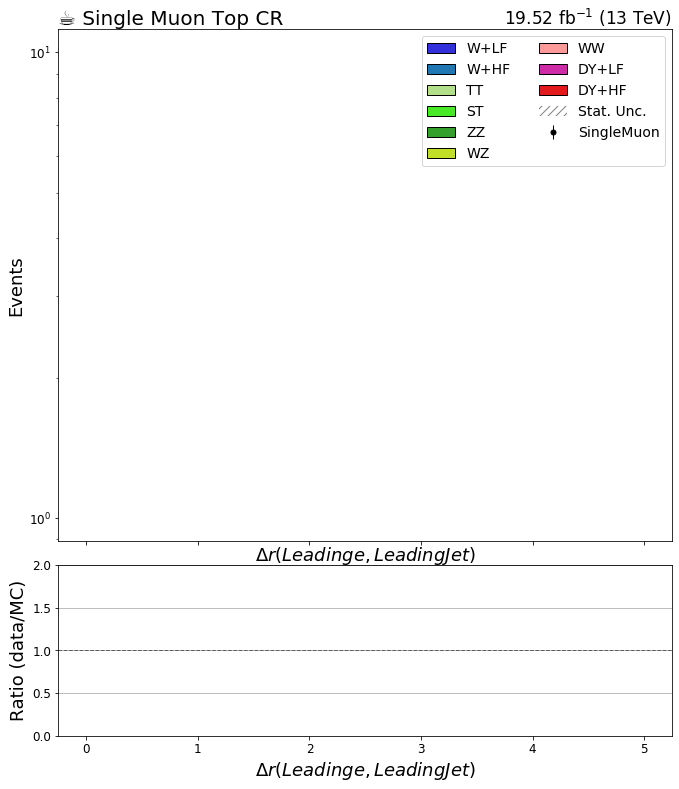

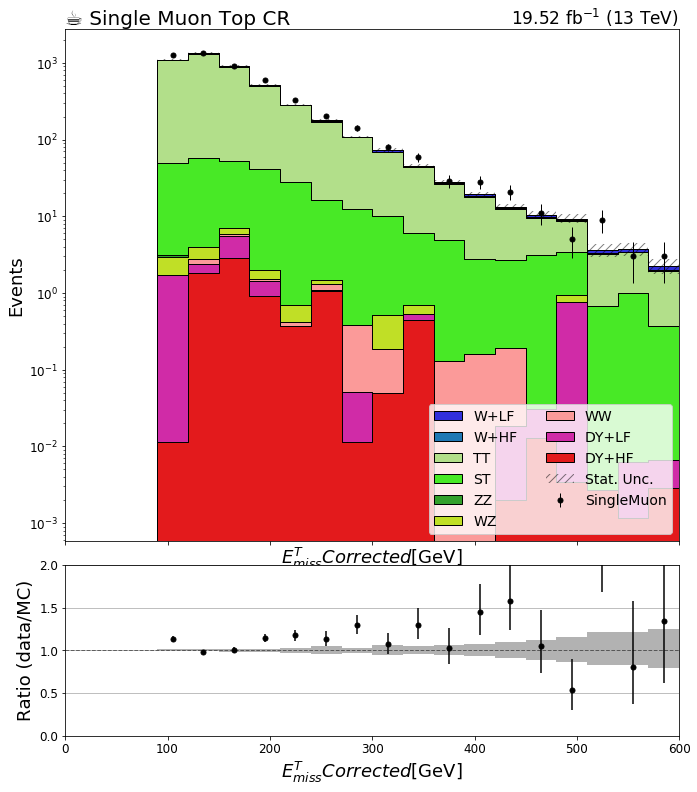

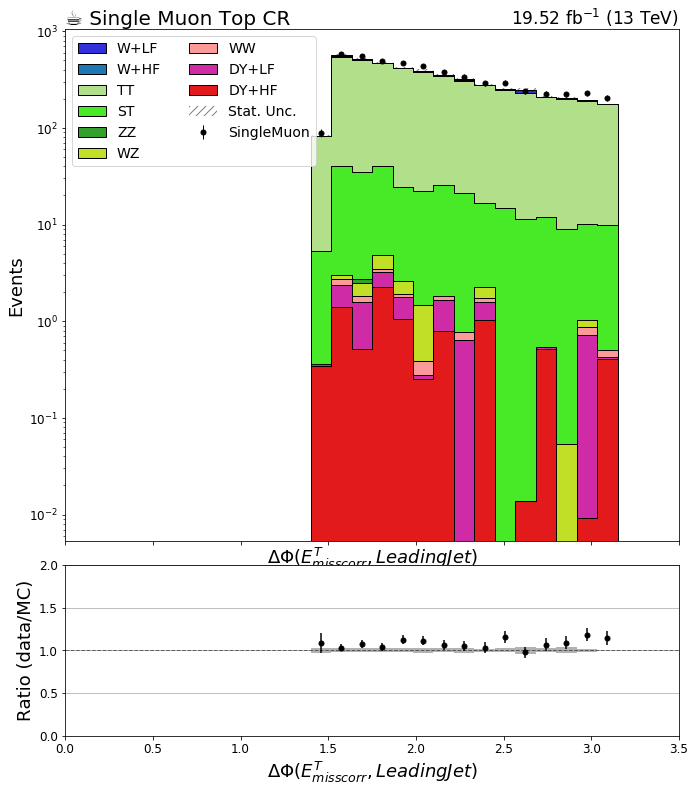

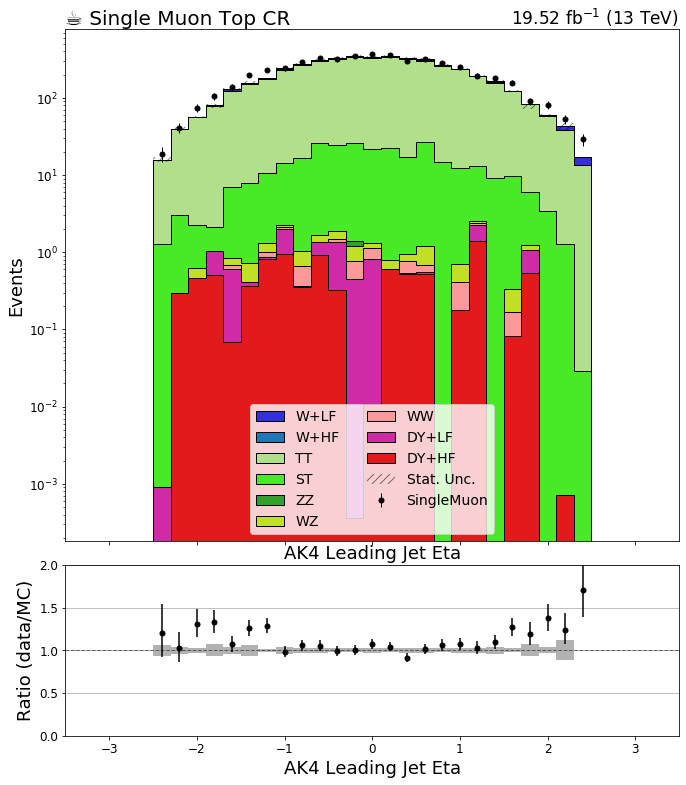

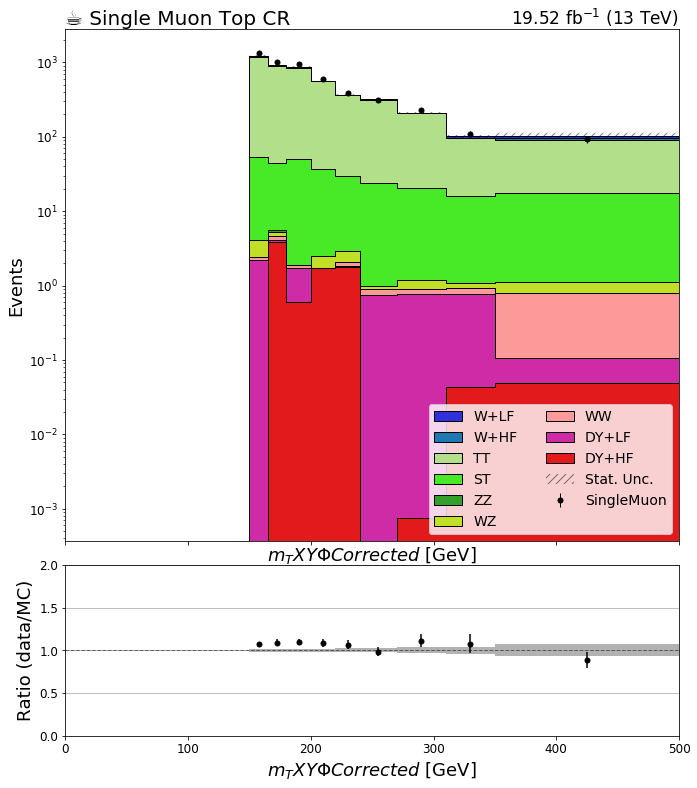

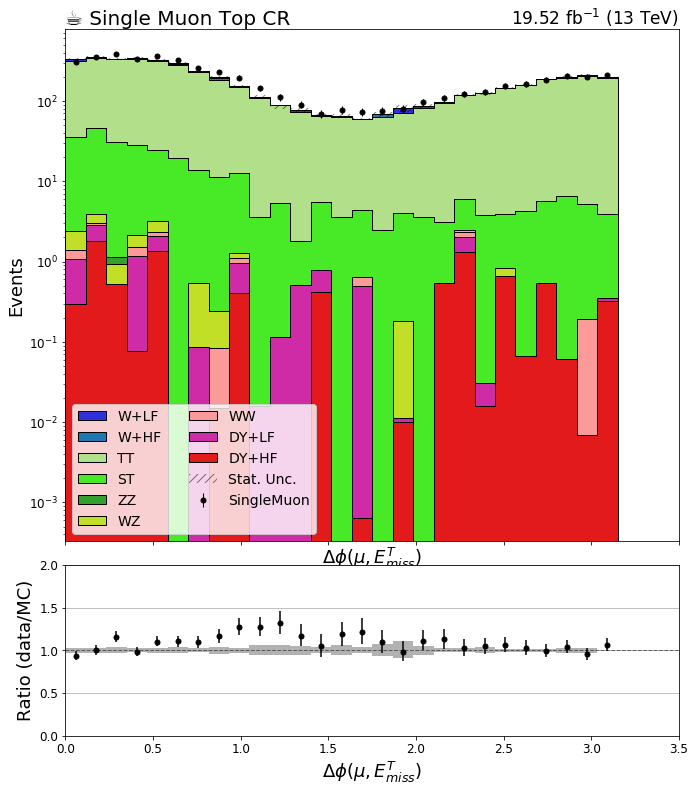

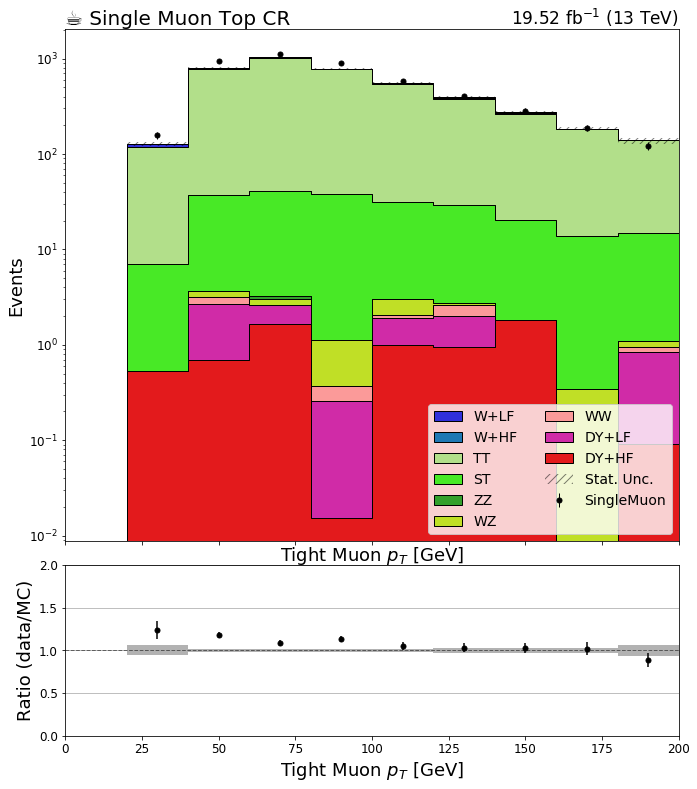

In [6]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2016'
region = 'ttbarm'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'dphi_Corr_Met_LJ' in key:continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate("systematic", sys).integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate("systematic", sys).integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate("systematic", sys).integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate("systematic", sys).integrate('region',j).sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"19.52 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic_preVFP'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic_preVFP'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

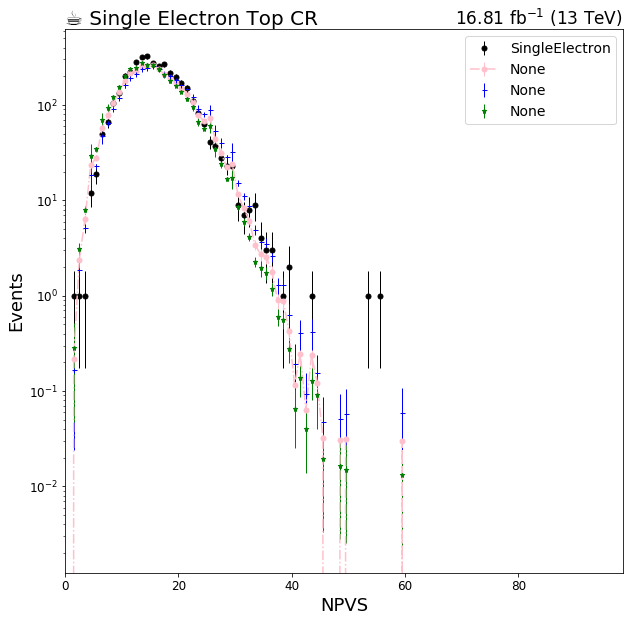

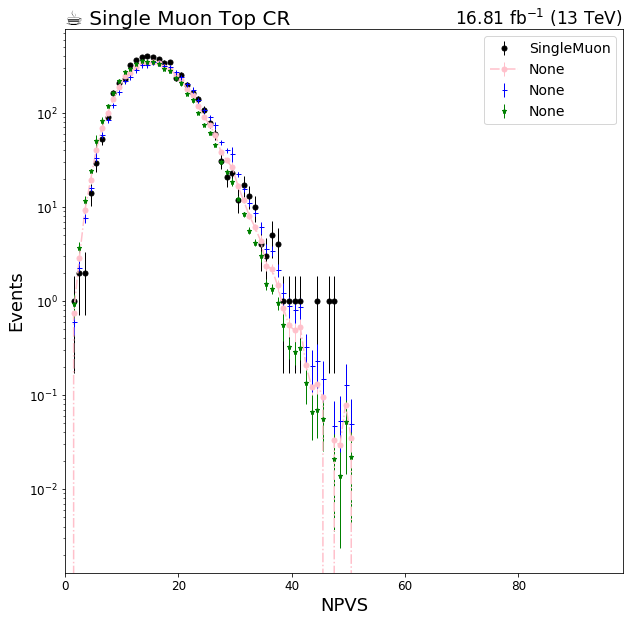

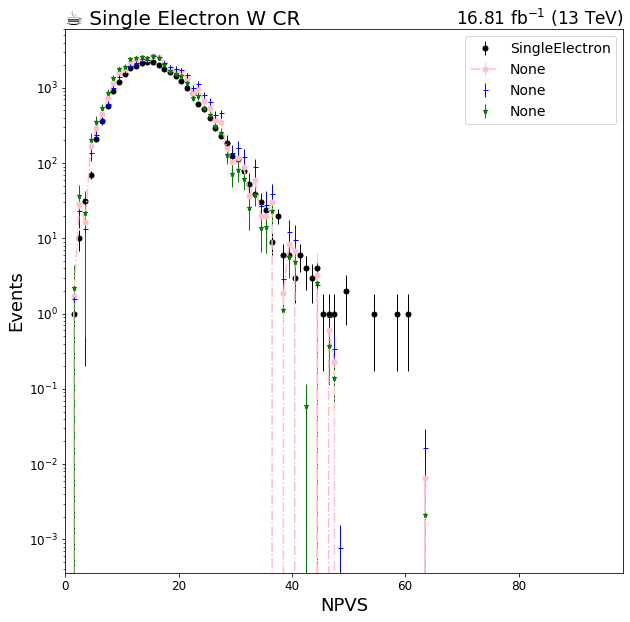

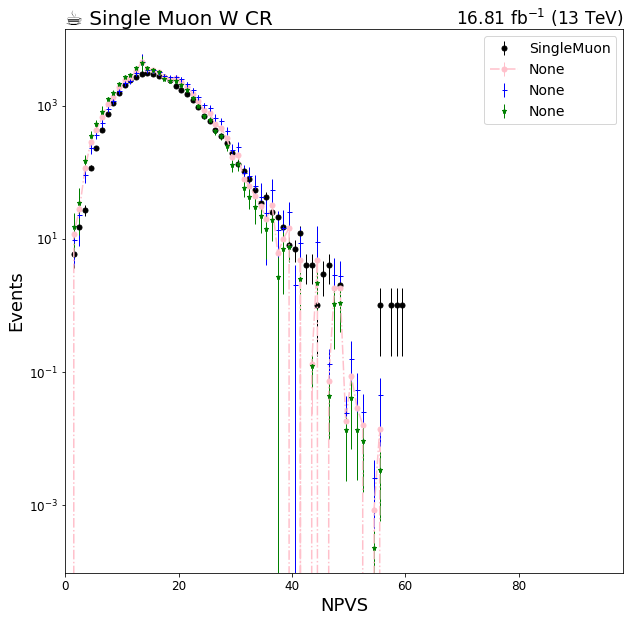

In [8]:


from coffea.hist import plot
import matplotlib.pyplot as plt

R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
for _region in bkg_hists['template'].identifiers('region'):
    if not (str(_region) not  in ['sre', 'srm']): continue
    fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 0.2,}
#     legend_opts = {'Process':"hi"}
    error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
    # nostack_fill_opts = {'alpha': 0.2, 'label': 'hi'}
    data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k',  }#, 'elinewidth': 1, 'emarker': '_'}
    bkg_err_opts_up = {'linestyle':'None', 'marker': '+', 'markersize': 5., 'color':'blue', }#, 'elinewidth': 1, 'emarker': '_'}
    bkg_err_opts_down = {'linestyle':'None', 'marker': '*', 'markersize': 5., 'color':'g', }#, 'elinewidth': 1, 'emarker': '_'}
    bkg_err_opts = {'linestyle':'-.', 'marker': 'o', 'markersize': 5., 'color':'pink', }#, 'elinewidth': 1, 'emarker': '_'}

    fig, ax = plt.subplots(1,1, figsize=(10,10))
    #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
    colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                      '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                      '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']

    plot.plot1d(data_hists['template'].integrate('region',_region).integrate('systematic', 'nominal').integrate('mT_corrected')[data['2016'][str(_region)]],            
    #         overlay="process",
            ax=ax,
            clear=False,
            error_opts=data_err_opts,
#                 legend_opts=legend_opts
               )

    plot.plot1d(bkg_hists['template'].integrate('region',_region).integrate('systematic', 'nominal').integrate('mT_corrected').sum('process'),
#                 overlay="process",
                ax=ax,
                clear=False,
    #             stack=True,
    #             fill_opts=fill_opts,
                error_opts=bkg_err_opts,
#                 legend_opts=legend_opts
                   )
    plot.plot1d(bkg_hists['template'].integrate('region',_region).integrate('systematic', 'puUp').integrate('mT_corrected').sum('process'),
    #             overlay="process",
                ax=ax,
                clear=False,
    #             stack=True,
    #             fill_opts=fill_opts,
                error_opts=bkg_err_opts_up
                   )

    plot.plot1d(bkg_hists['template'].integrate('region',_region).integrate('systematic', 'puDown').integrate('mT_corrected').sum('process'),
    #             overlay="process",
                ax=ax,
                clear=False,
    #             stack=True,
    #             fill_opts=fill_opts,
                error_opts=bkg_err_opts_down,
                   )
    ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
    args = {'linestyle':'--', 'linewidth': 5}
    ax.autoscale(axis='x', tight=True)
    ax.set_yscale('log')
    # if(key=='dilepmass'): ax.set_xlim(50, 130)
    ax.set_ylim(.1, None)
    ax.autoscale()
    leg = ax.legend(ncol=1, loc='best')
    coffee = plt.text(0., 1., u"☕ "+R[str(_region).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
    lumi = plt.text(1., 1., r"16.81 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)

Text(0.5, 1.0, '2016 preVFP wjete')

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


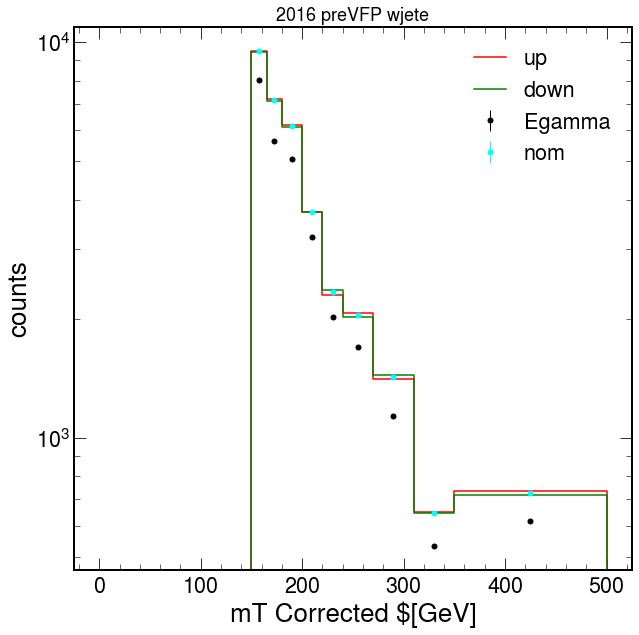

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
# plt.style.use(hep.style.ROOT)

j = 'wjete'
bins = bkg_hists['template'].integrate('region', j).integrate("systematic","puDown").axis("mT_corrected").edges()[()]
data = data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
down = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puDown').integrate('npvs').integrate('process').values()[()]
nom = bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
up = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puUp').integrate('npvs').integrate('process').values()[()]

f, ax = plt.subplots(figsize=[10,10])
hep.histplot(data, bins,color='black',histtype='errorbar',
label="Egamma")
hep.histplot(up, bins, color='red',
label="up")
hep.histplot(down, bins, color='green',
label="down")
hep.histplot(nom, bins, color='cyan',histtype='errorbar',
label="nom")
ax.legend()
ax.set_yscale('log')
ax.set_ylabel("counts")
ax.set_xlabel("mT Corrected $[GeV]")
ax.set_title("2016 preVFP "+j)

Text(0.5, 1.0, '2016 preVFP wjetm')

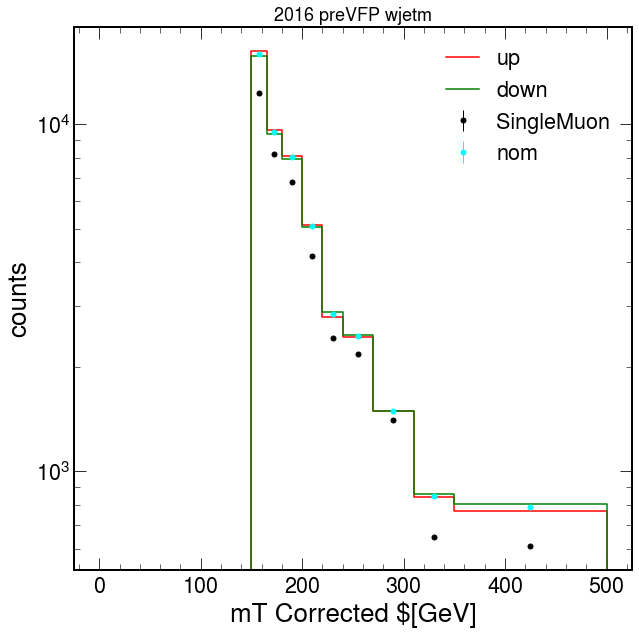

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
plt.style.use(hep.style.ROOT)

j = 'wjetm'
bins = bkg_hists['template'].integrate('region', j).integrate("systematic","puDown").axis("mT_corrected").edges()[()]
data = data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
down = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puDown').integrate('npvs').integrate('process').values()[()]
nom = bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
up = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puUp').integrate('npvs').integrate('process').values()[()]

f, ax = plt.subplots(figsize=[10,10])
hep.histplot(data, bins,color='black',histtype='errorbar',
label="SingleMuon")
hep.histplot(up, bins, color='red',
label="up")
hep.histplot(down, bins, color='green',
label="down")
hep.histplot(nom, bins, color='cyan',histtype='errorbar',
label="nom")
ax.legend()
ax.set_yscale('log')
ax.set_ylabel("counts")
ax.set_xlabel("mT Corrected $[GeV]")
ax.set_title("2016 preVFP "+j)

Text(0.5, 1.0, '2016 preVFP ttbarm')

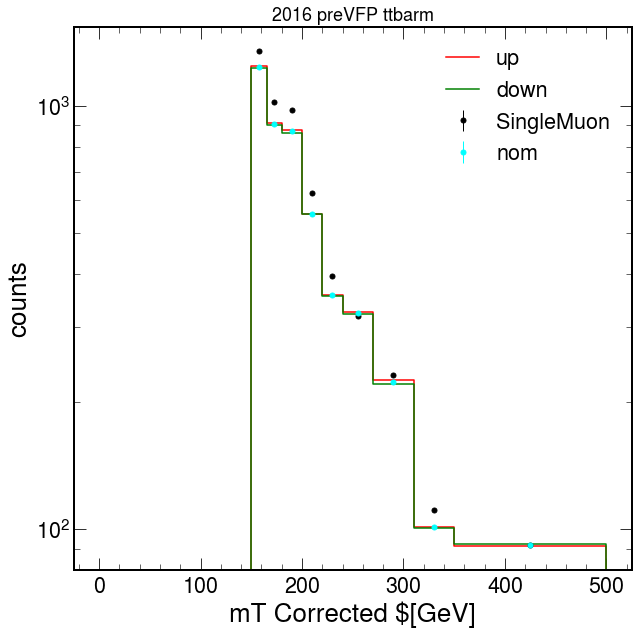

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
plt.style.use(hep.style.ROOT)

j = 'ttbarm'
bins = bkg_hists['template'].integrate('region', j).integrate("systematic","puDown").axis("mT_corrected").edges()[()]
data = data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
down = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puDown').integrate('npvs').integrate('process').values()[()]
nom = bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
up = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puUp').integrate('npvs').integrate('process').values()[()]

f, ax = plt.subplots(figsize=[10,10])
hep.histplot(data, bins,color='black',histtype='errorbar',
label="SingleMuon")
hep.histplot(up, bins, color='red',
label="up")
hep.histplot(down, bins, color='green',
label="down")
hep.histplot(nom, bins, color='cyan',histtype='errorbar',
label="nom")
ax.legend()
ax.set_yscale('log')
ax.set_ylabel("counts")
ax.set_xlabel("mT Corrected $[GeV]")
ax.set_title("2016 preVFP "+j)

Text(0.5, 1.0, '2016 preVFP wjetm')

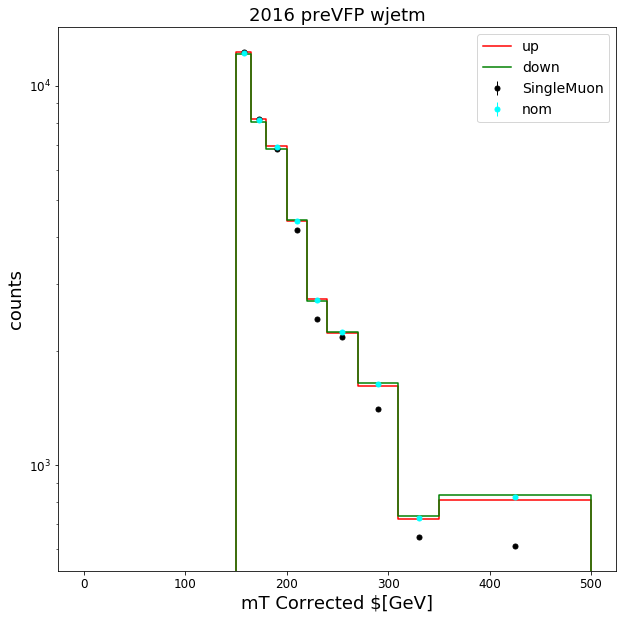

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
# plt.style.use(hep.style.ROOT)

j = 'wjetm'
bins = bkg_hists['template'].integrate('region', j).integrate("systematic","puDown").axis("mT_corrected").edges()[()]
data = data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
down = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puDown').integrate('npvs').integrate('process').values()[()]
nom = bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
up = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puUp').integrate('npvs').integrate('process').values()[()]

f, ax = plt.subplots(figsize=[10,10])
hep.histplot(data, bins,color='black',histtype='errorbar',
label="SingleMuon")
hep.histplot(up, bins, color='red',
label="up")
hep.histplot(down, bins, color='green',
label="down")
hep.histplot(nom, bins, color='cyan',histtype='errorbar',
label="nom")
ax.legend()
ax.set_yscale('log')
ax.set_ylabel("counts")
ax.set_xlabel("mT Corrected $[GeV]")
ax.set_title("2016 preVFP "+j)

In [61]:
nom=bkg_hists['template'].integrate('region', 'ttbare').integrate('systematic', 'nominal').sum('process').sum('npvs').values()[()]
up=bkg_hists['template'].integrate('region', 'ttbare').integrate('systematic', 'METunclUp').sum('process').sum('npvs').values()[()]
down=bkg_hists['template'].integrate('region', 'ttbare').integrate('systematic', 'METunclDown').sum('process').sum('npvs').values()[()]

In [62]:
up[nom<=0]=1
down[nom<=0]=1

In [63]:
up[~(nom<=0)] /= nom[~(nom<=0)]
down[~(nom<=0)] /= nom[~(nom<=0)]

In [64]:
up

array([1.        , 1.        , 0.98793273, 1.05161463, 1.0870678 ,
       0.98029402, 1.01484561, 0.92144899, 1.13383339, 1.02998466,
       0.97423762])

In [65]:
down

array([1.        , 1.        , 0.94296615, 1.03003422, 1.01987031,
       0.95926222, 0.93918632, 0.97697362, 1.04560723, 0.99589909,
       0.99302184])

In [3]:
def remap_histograms(hists):
    data_hists = {}
    bkg_hists = {}
    signal_hists = {}

    process = hist.Cat("process", "Process", sorting="placement")
    cats = ("process",)
    sig_map = OrderedDict()
    bkg_map = OrderedDict()
    data_map = OrderedDict()
    bkg_map["Hbb"] = ("Hbb*",)
    bkg_map["DY+jets"] = ("DY+*",)
    bkg_map["VV"] = (["WW", "WZ", "ZZ"],)
    bkg_map["ST"] = ("ST*",)
    bkg_map["TT"] = ("TT*",)
    bkg_map["W+jets"] = ("W+*")
#     bkg_map["W+HF"] = ("W+HF",)
#     bkg_map["W+LF"] = ("W+LF",)
    bkg_map["Z+jets"] = ("Z+*",)
#     bkg_map["Z+HF"] = ("Z+HF",)
#     bkg_map["Z+LF"] = ("Z+LF",)
#     bkg_map["G+jets"] = ("G+*",)
    bkg_map["QCD"] = ("QCD*",)
    data_map["SingleElectron"] = ("SingleElectron",)
    data_map["SingleMuon"] = ("SingleMuon",)
    data_map["EGamma"] = ("EGamma",)
    sig_map["Mphi1995_Mchi1000"] = ("Mphi-1995_Mchi-1000")
    sig_map["Mphi2000_Mchi1500"] = ("Mphi-2000_Mchi-1500")
    sig_map["Mphi2000_Mchi500"] = ("Mphi-2000_Mchi-500")
#     haven't processed signal yet
    for signal in hists['sig']['template'].identifiers('process'):
        if 'mchi' not in str(signal): continue
        sig_map[str(signal)] = (str(signal),)  ## signals

    for key in hists["data"].keys():
        bkg_hists[key] = hists["bkg"][key].group(cats, process, bkg_map)
        signal_hists[key] = hists["sig"][key].group(cats, process, sig_map)
        data_hists[key] = hists["data"][key].group(cats, process, data_map)

    print('initial mT_corrected binning',bkg_hists["template"].axis("mT_corrected").edges())


    bkg_hists["template"] = bkg_hists["template"].rebin(
        "mT_corrected", hist.Bin("mT_corrected", "mT_corrected", mT_corrected_binning)
    )
    signal_hists["template"] = signal_hists["template"].rebin(
        "mT_corrected", hist.Bin("mT_corrected", "mT_corrected", mT_corrected_binning)
    )
    data_hists["template"] = data_hists["template"].rebin(
        "mT_corrected", hist.Bin("mT_corrected", "mT_corrected", mT_corrected_binning)
    )

    hists = {"bkg": bkg_hists, "data": data_hists, "sig":signal_hists}

    return hists

In [7]:
year = '2016'

mT_corrected_binning_dict = {
    "2018":np.linspace(100, 600, 16),
    "2017":np.linspace(100, 600, 16),
    "2016":np.linspace(100, 600, 16)
#     "2018": np.array([100.0,125.0,150.0, 165.0, 180.0, 200.0, 220.0, 240.0, 270.0, 310.0, 350.0, 500]),
#     "2017": np.array([100.0,125.0,150.0, 165.0, 180.0, 200.0, 220.0, 240.0, 270.0, 310.0, 350.0, 500]),
#     "2016": np.array([100.0,125.0,150.0, 165.0, 180.0, 200.0, 220.0, 240.0, 270.0, 310.0, 350.0, 500])
}
mT_corrected_binning = mT_corrected_binning_dict[year]
mT_correctedbins = np.array(mT_corrected_binning)
nmT_corrected = len(mT_correctedbins) - 1

###
# Extract histograms from input file
###

print("Grouping histograms")
hists = load("../../../hists/UL_lep_monotop_v1_test_preVFP_" + year + ".scaled")
hists = remap_histograms(hists)
data_hists = hists["data"]
bkg_hists = hists["bkg"]
signal_hists = hists["sig"]

###
# Preparing histograms for fit
##

# data = {}
# for r in data_hists["template"].identifiers("region"):
#     data[str(r)] = data_hists["template"].integrate("region", r)

# background = {}
# for r in bkg_hists["template"].identifiers("region"):
#     background[str(r)] = bkg_hists["template"].integrate("region", r)

# signal = {}
# for r in signal_hists["template"].identifiers("region"):
#     signal[str(r)] = signal_hists["template"].integrate("region", r)

Grouping histograms
initial mT_corrected binning [100.         133.33333333 166.66666667 200.         233.33333333
 266.66666667 300.         333.33333333 366.66666667 400.
 433.33333333 466.66666667 500.         533.33333333 566.66666667
 600.        ]


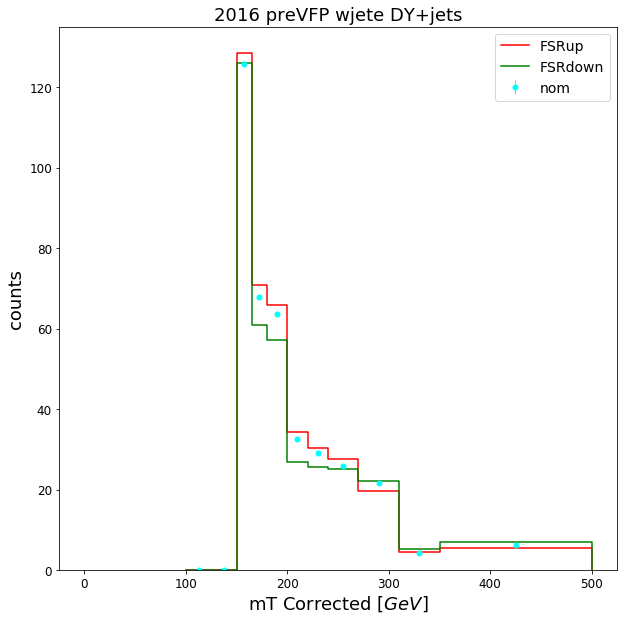

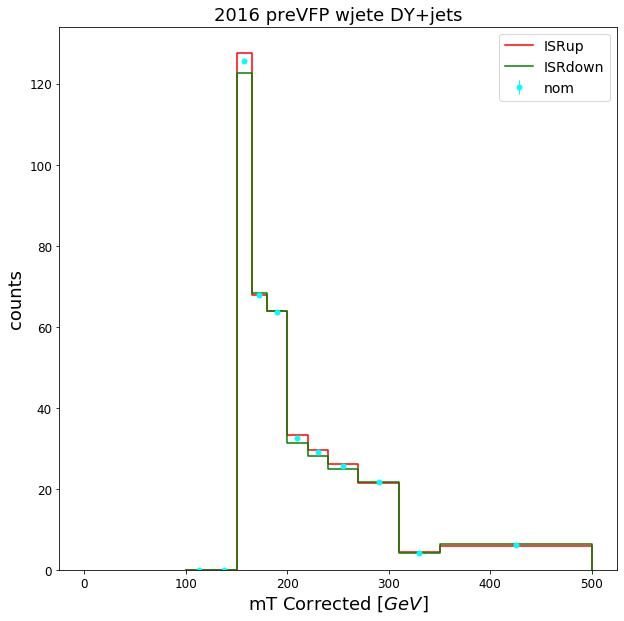

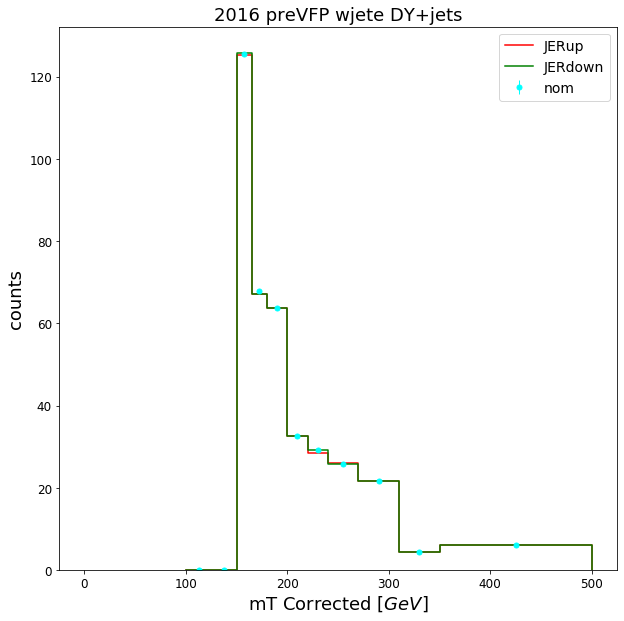

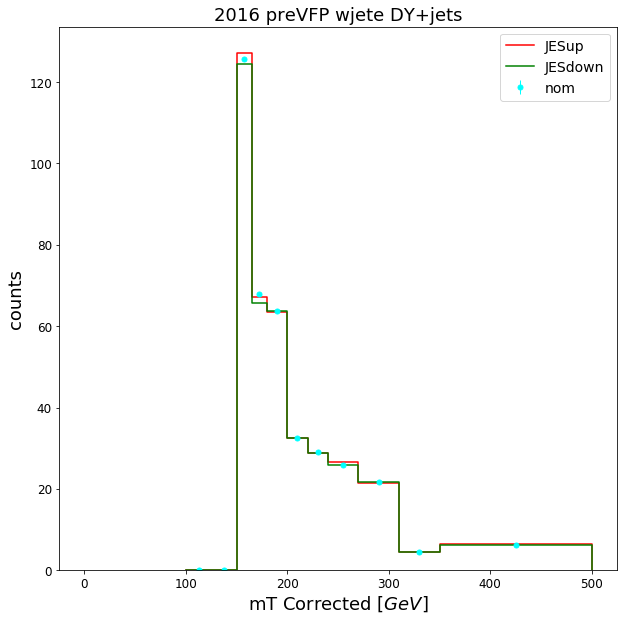

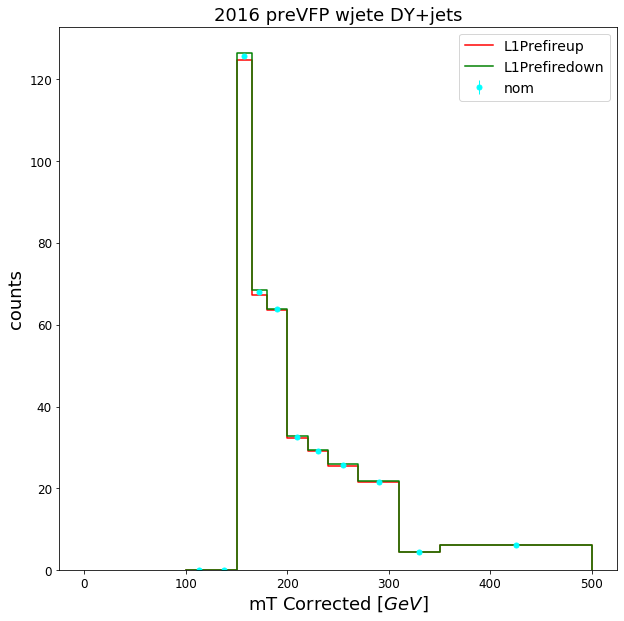

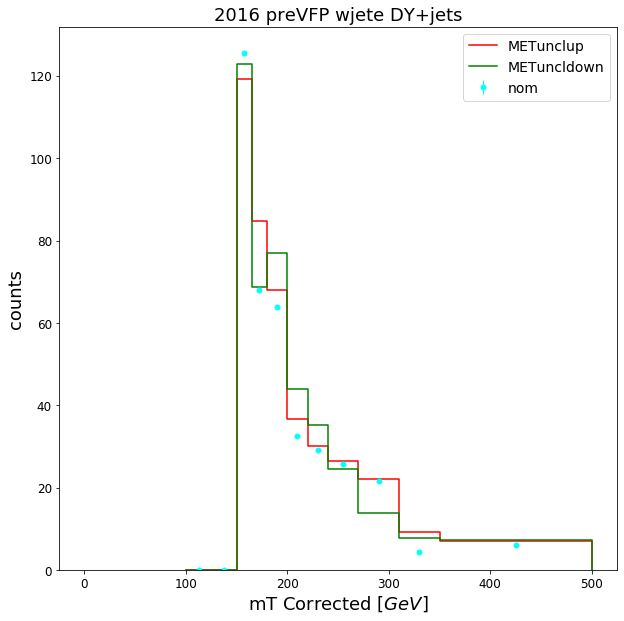

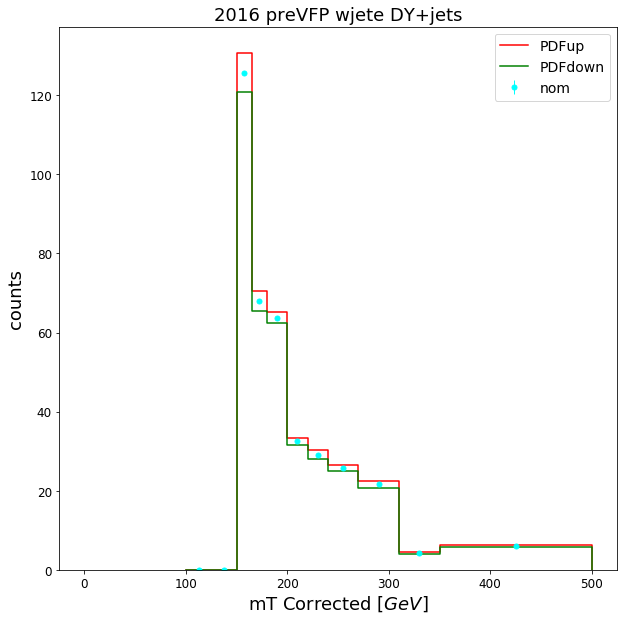

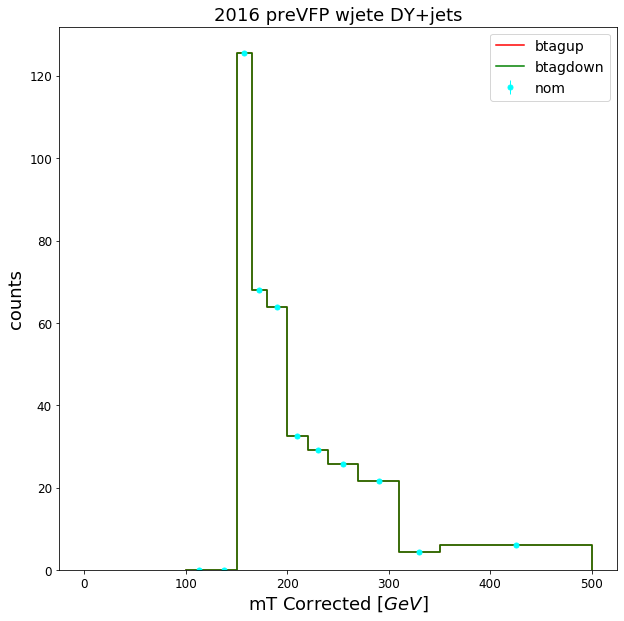

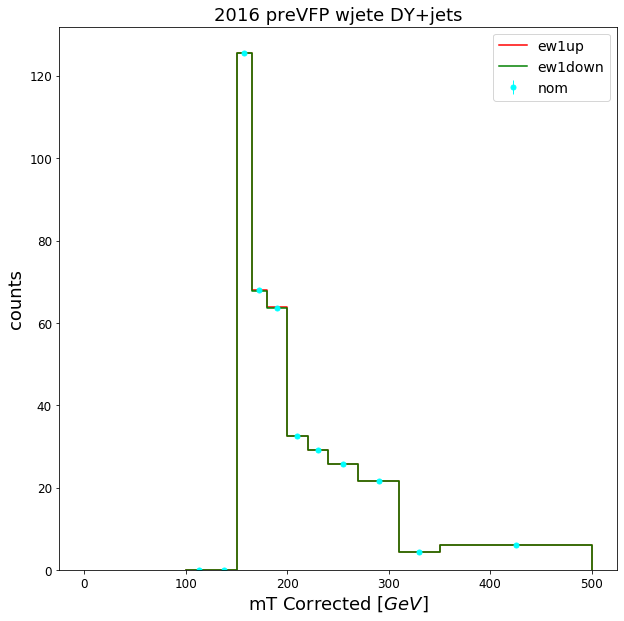

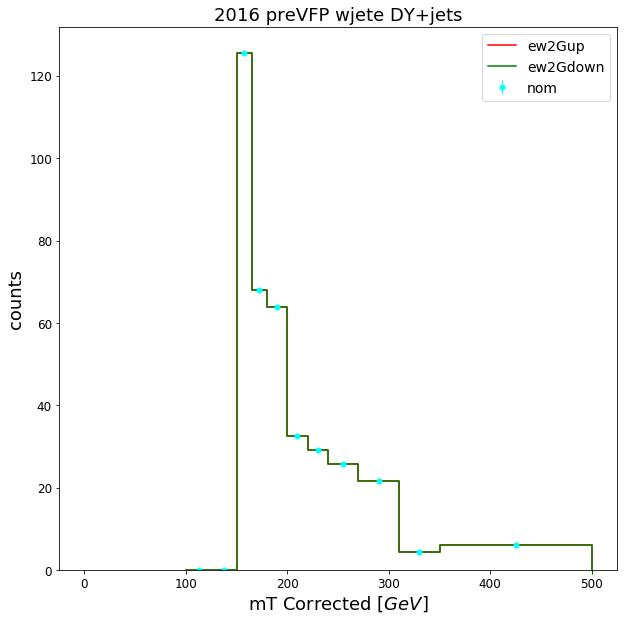

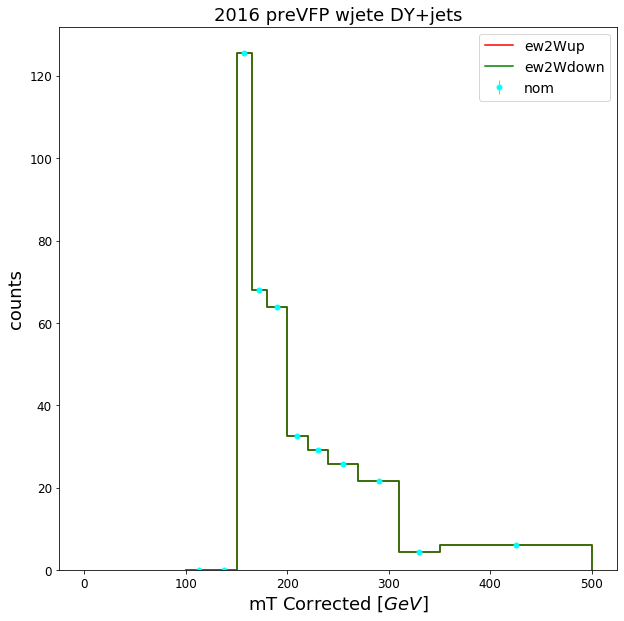

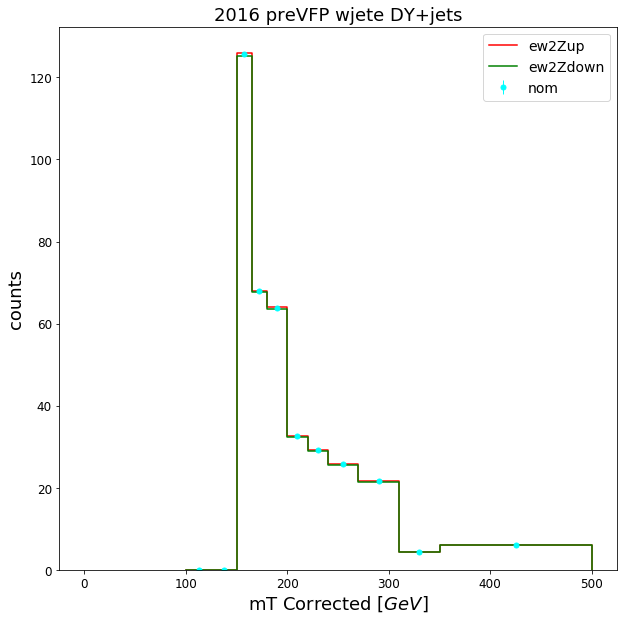

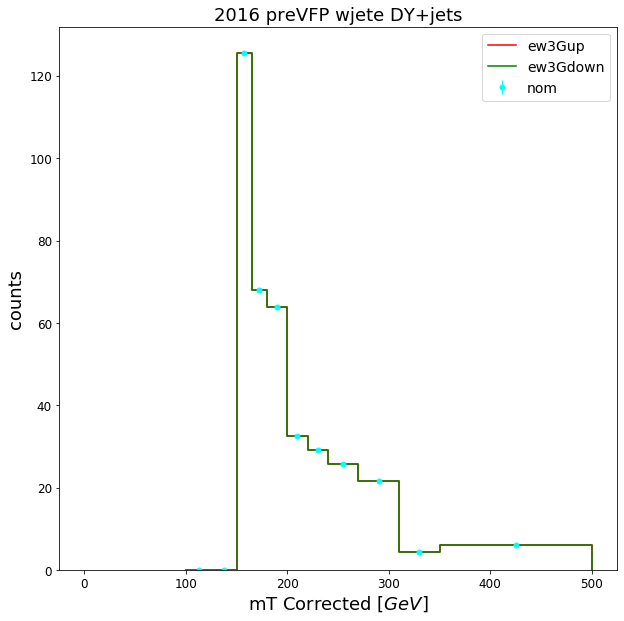

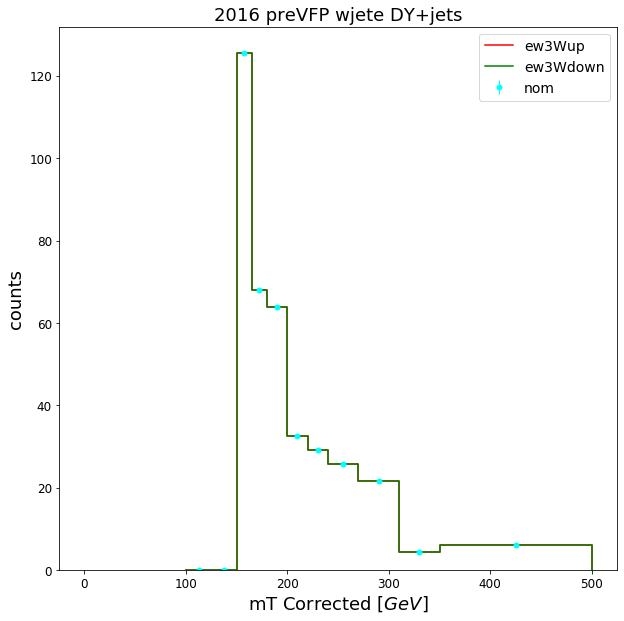

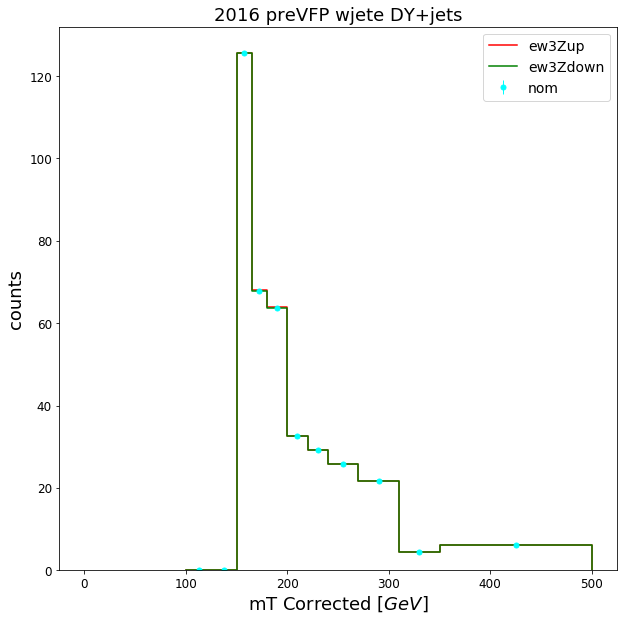

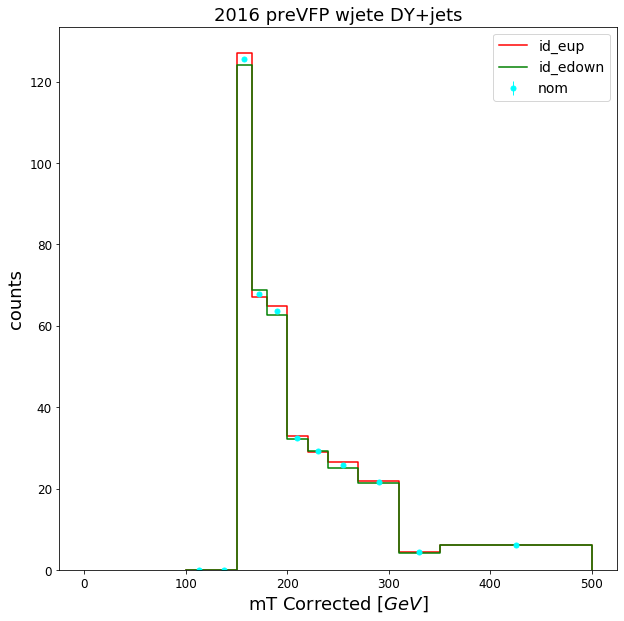

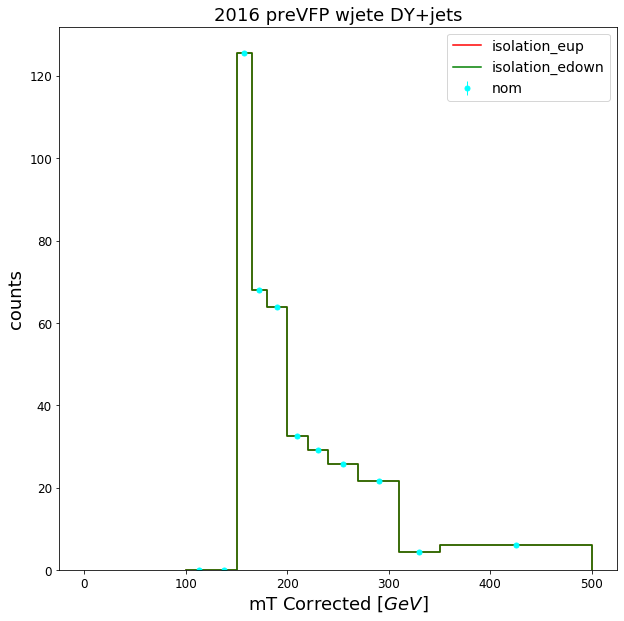

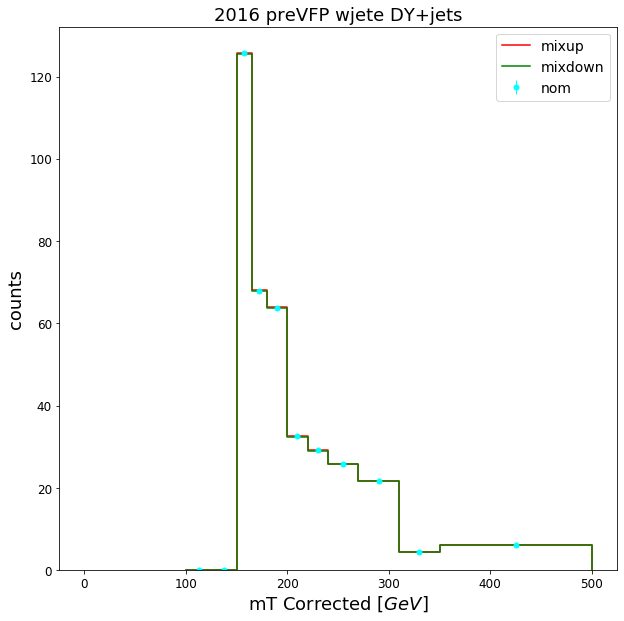

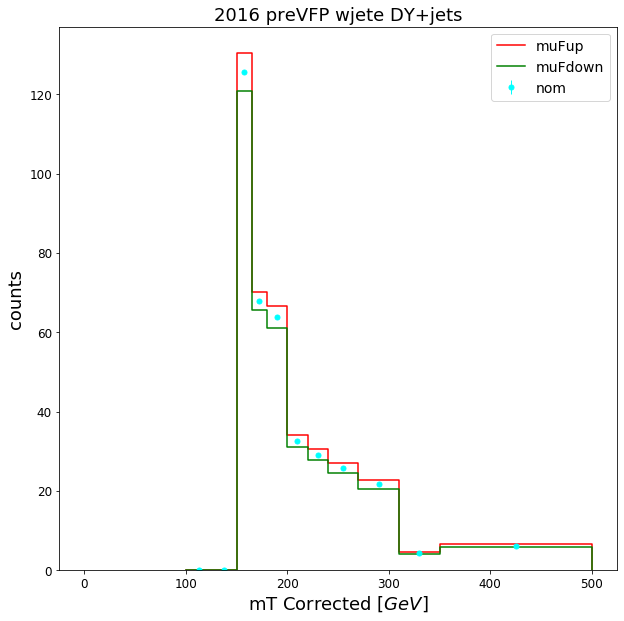

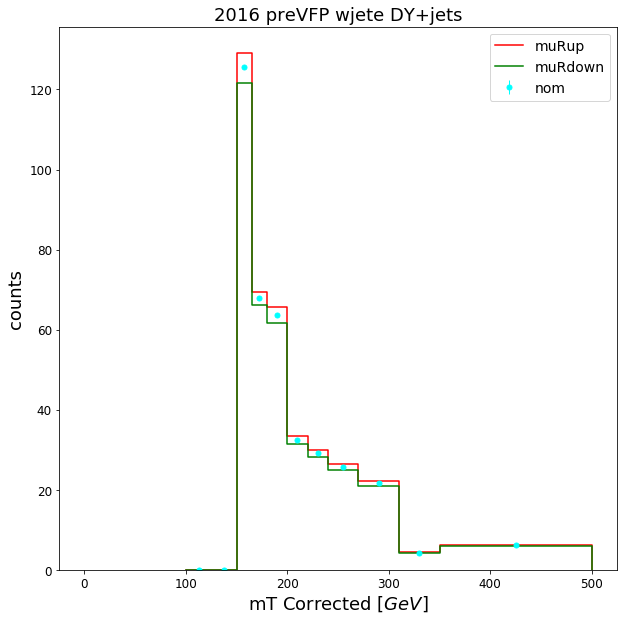

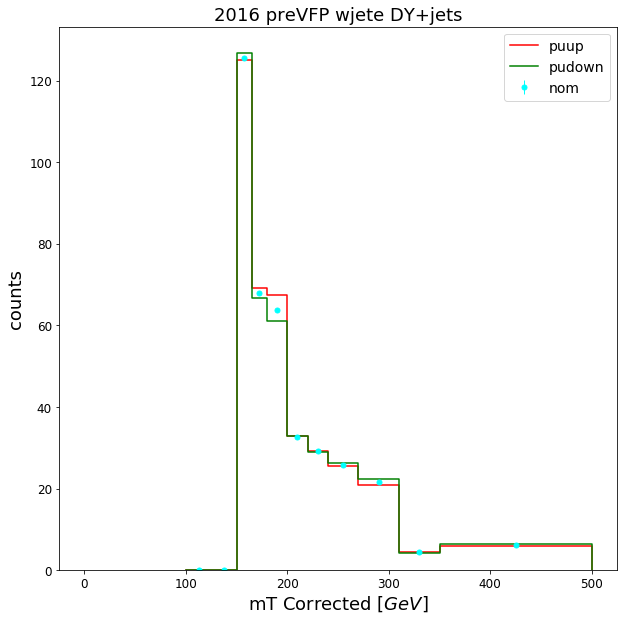

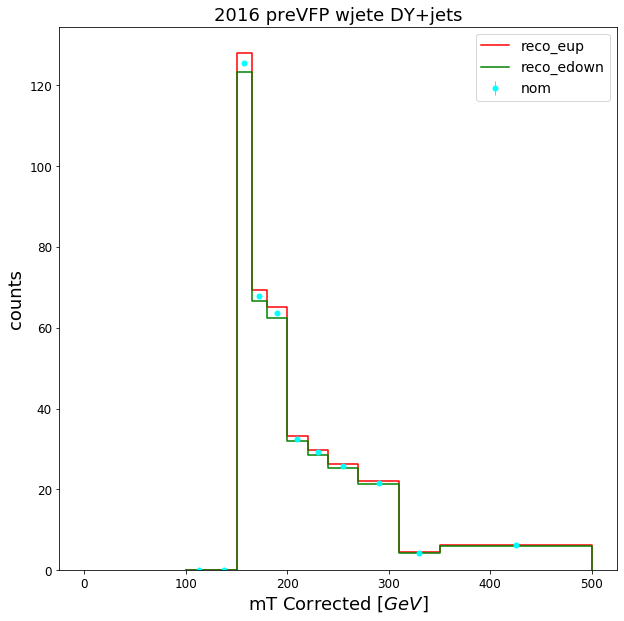

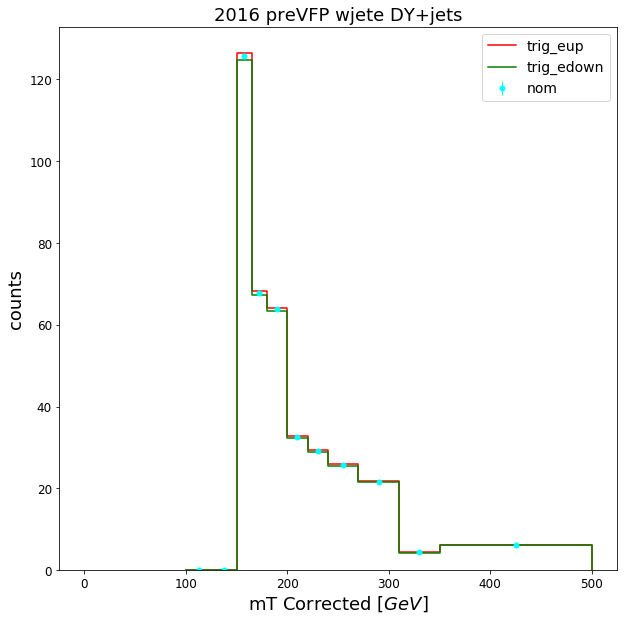

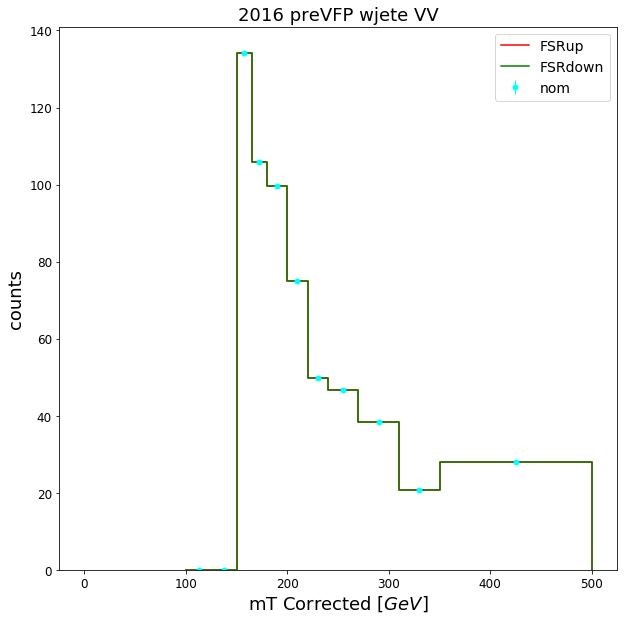

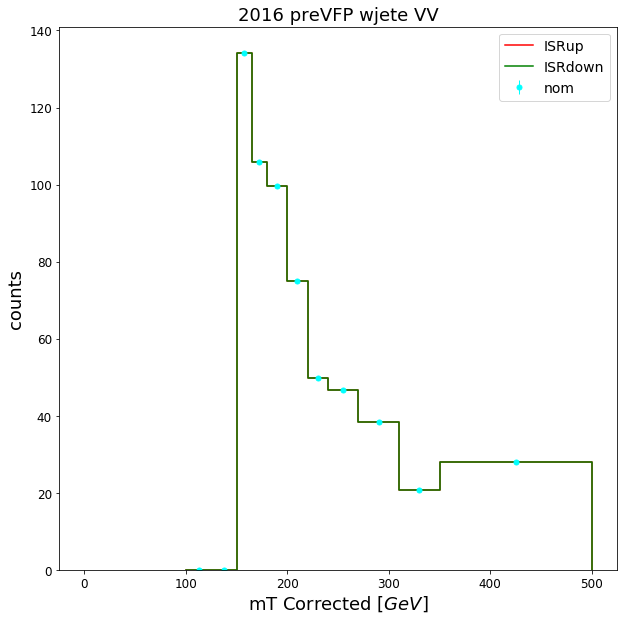

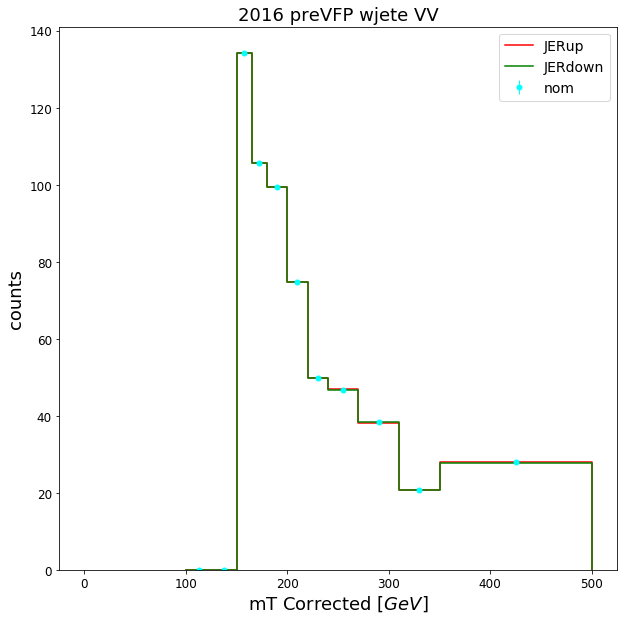

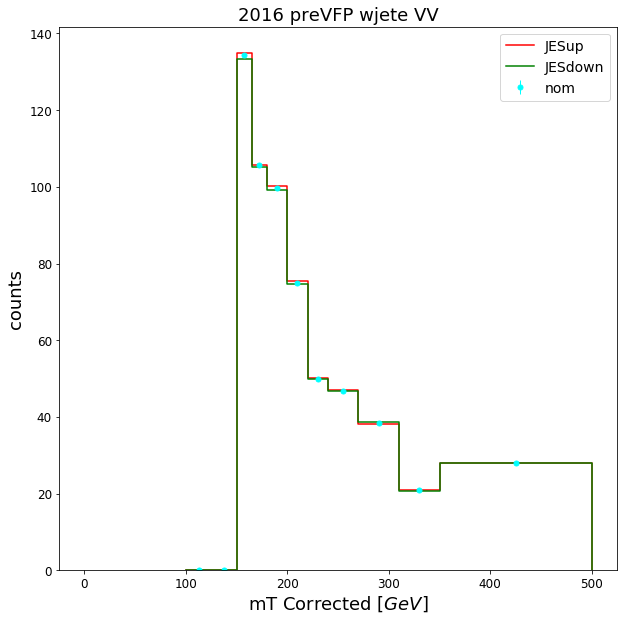

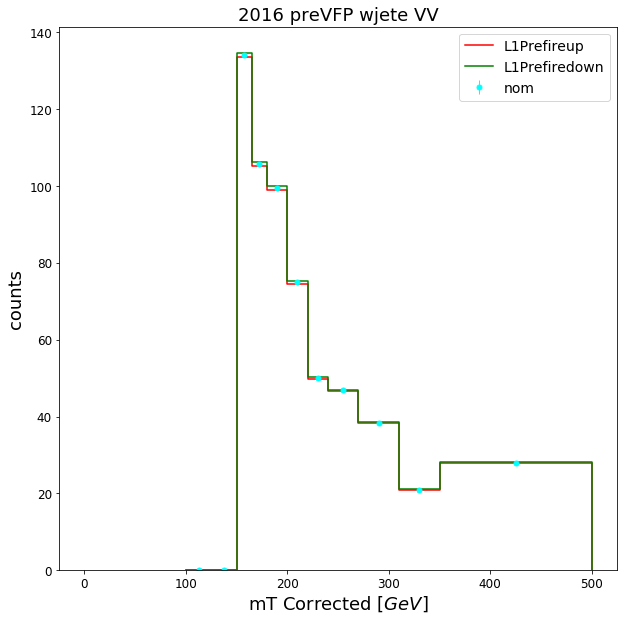

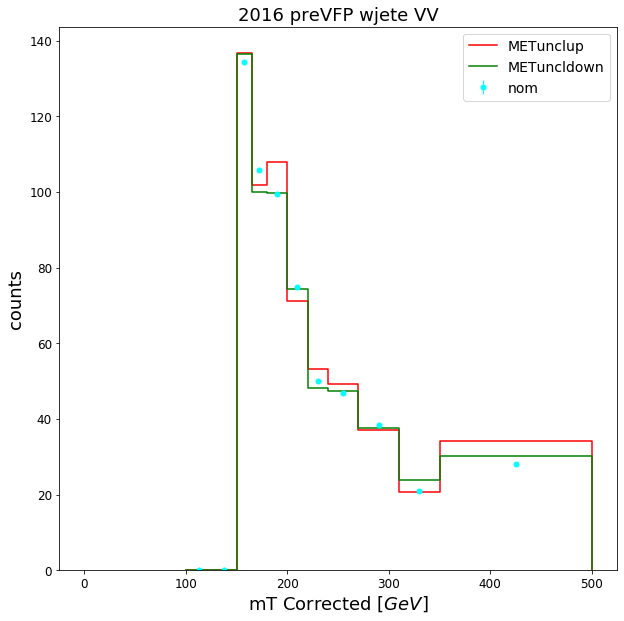

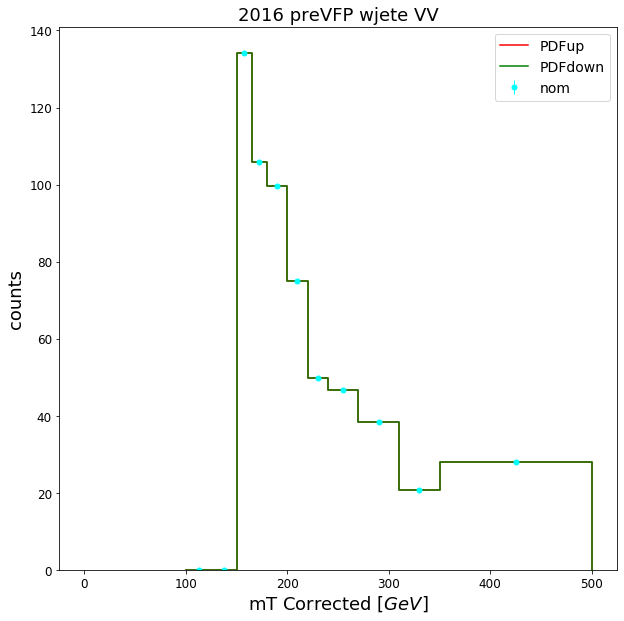

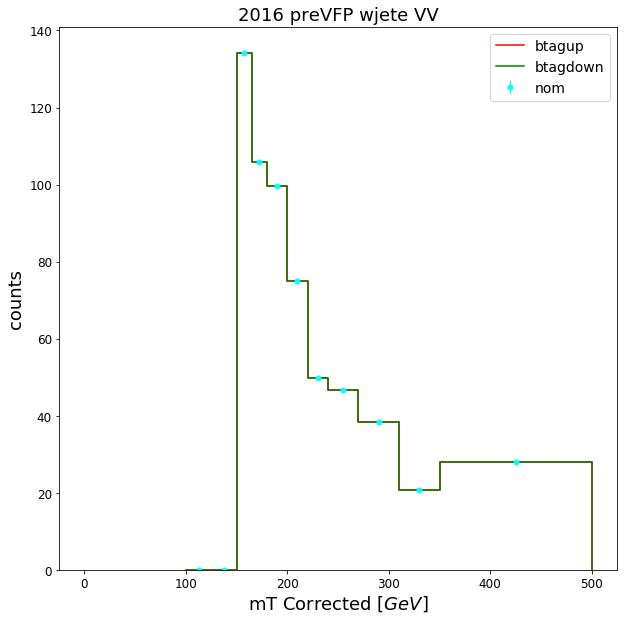

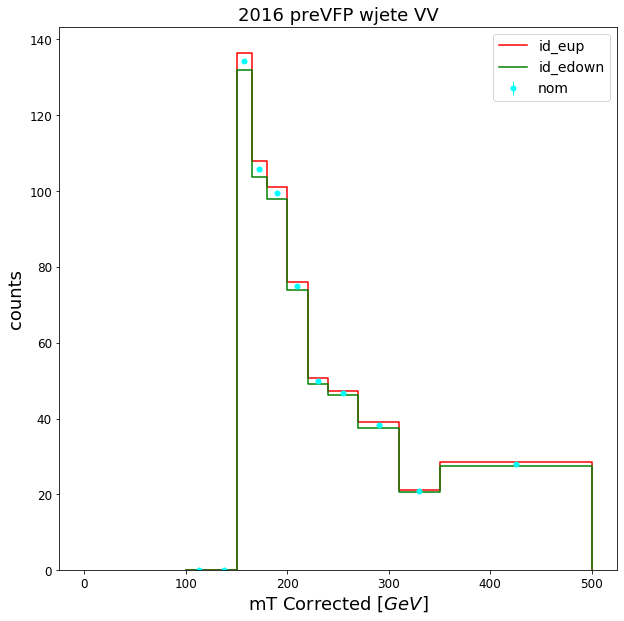

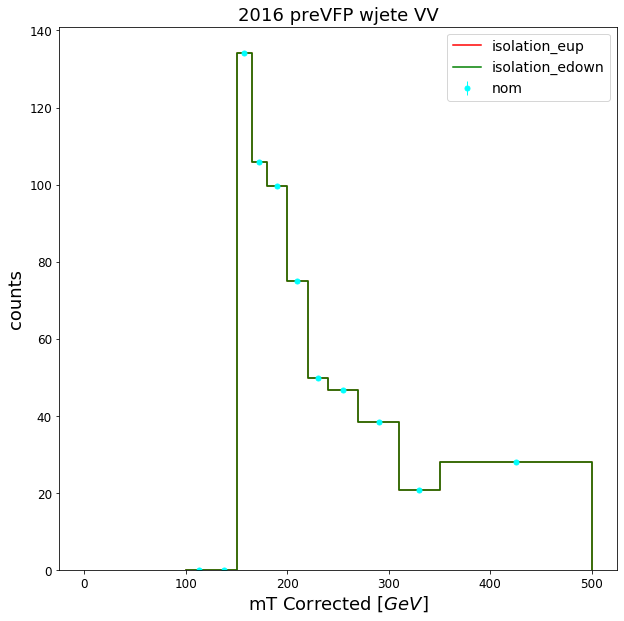

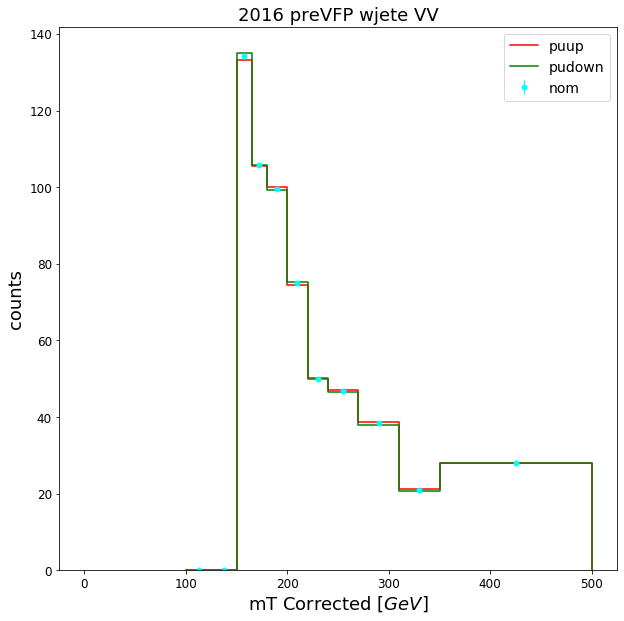

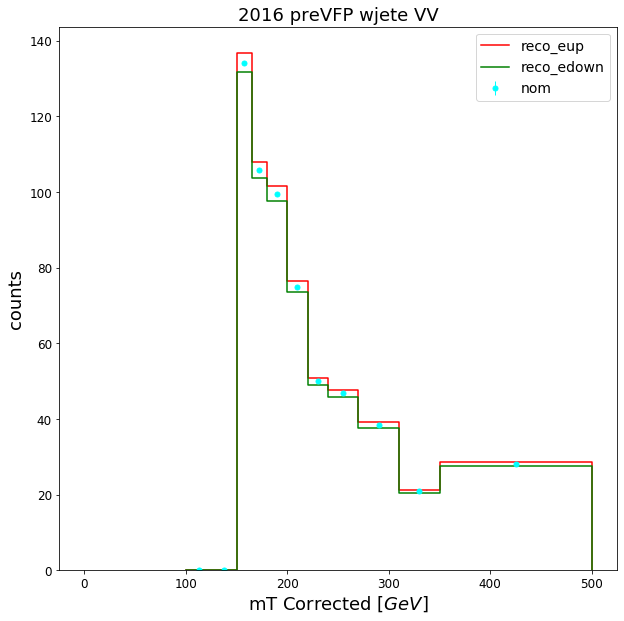

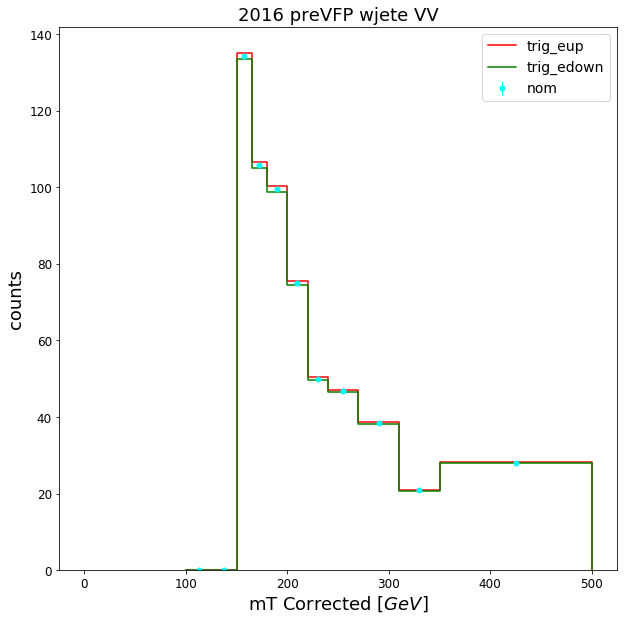

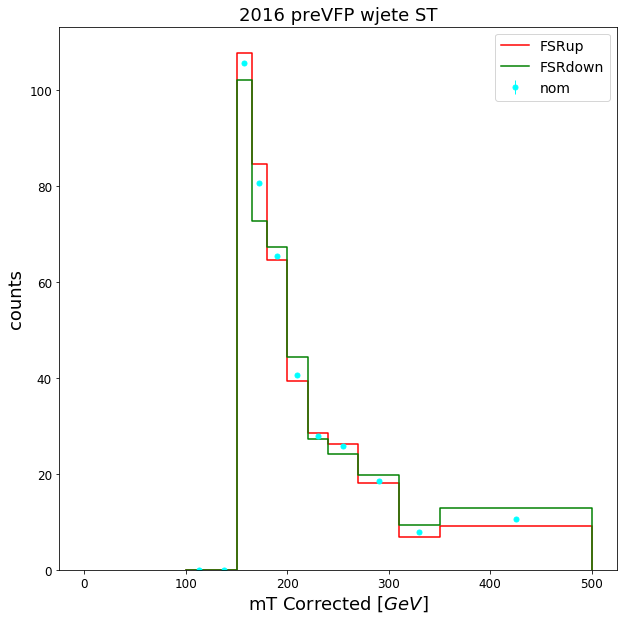

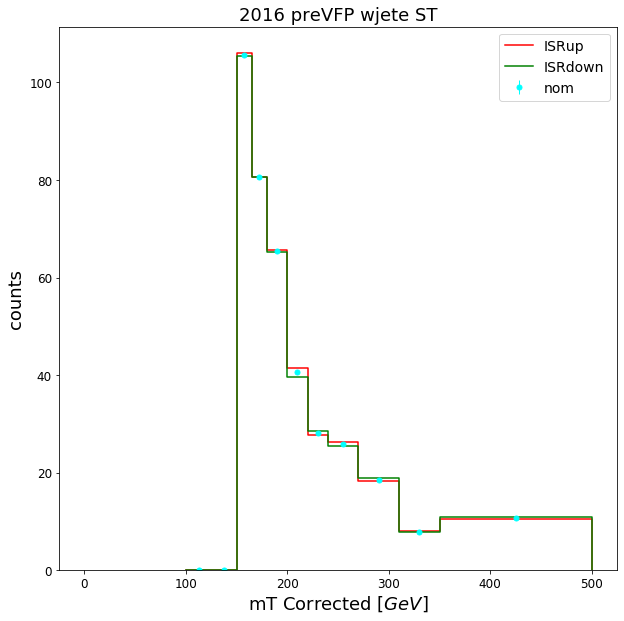

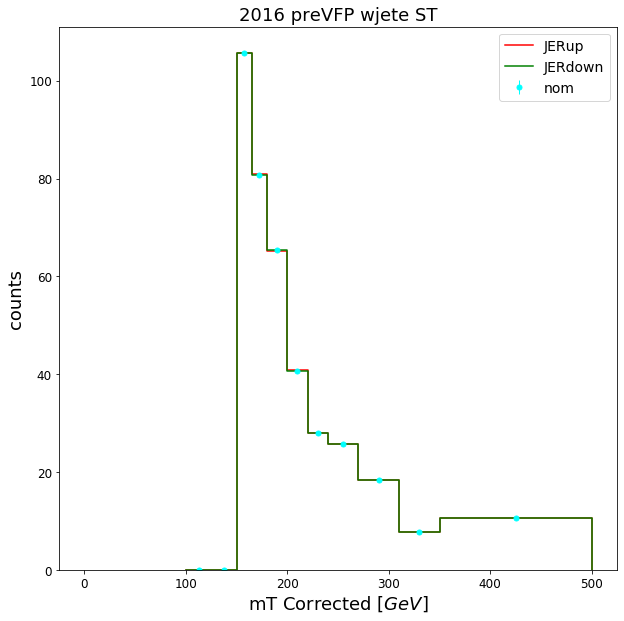

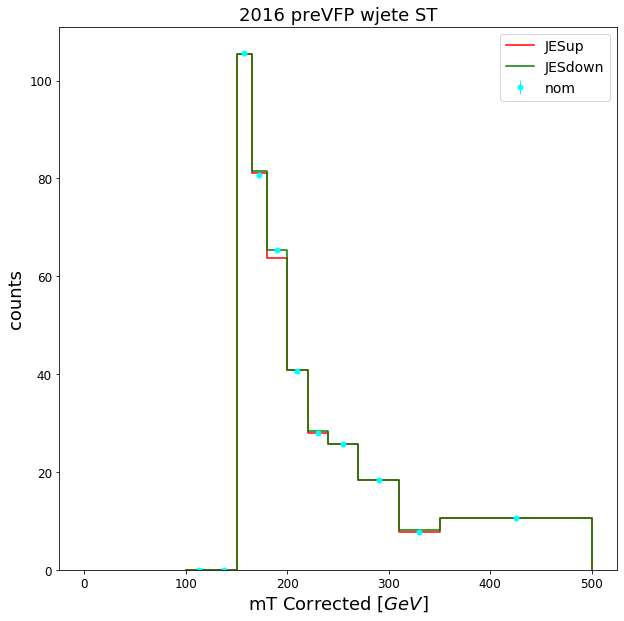

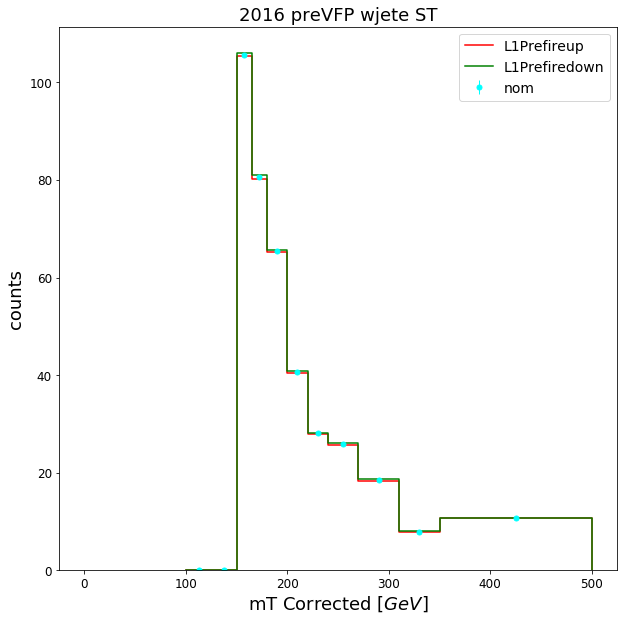

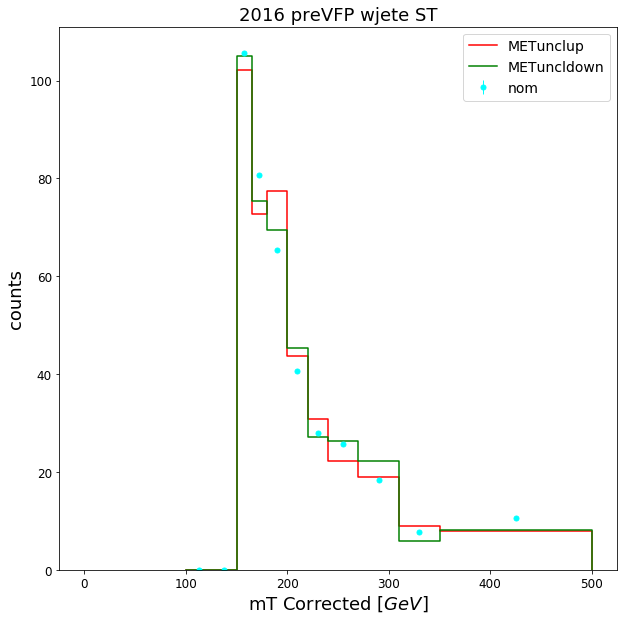

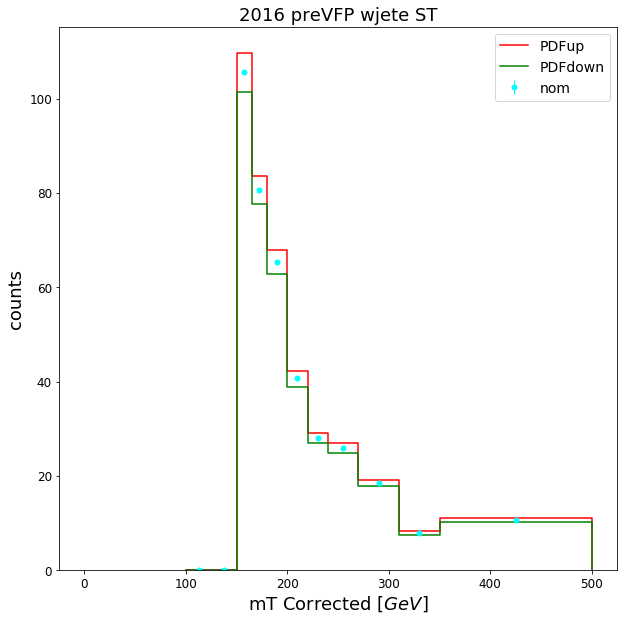

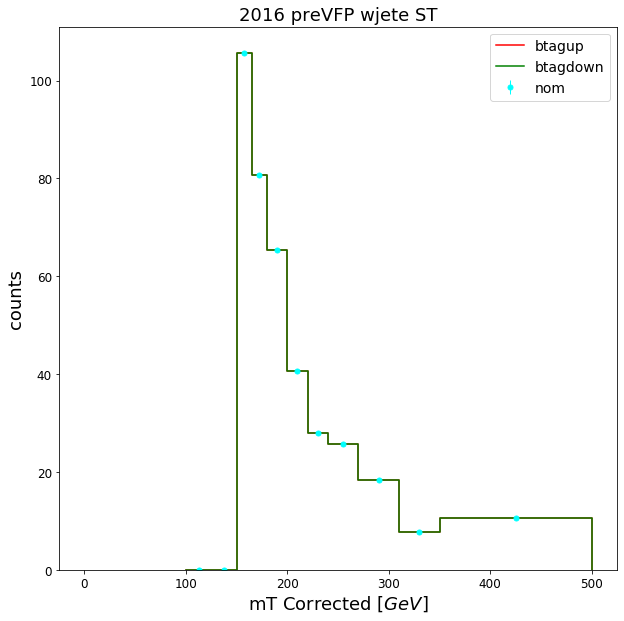

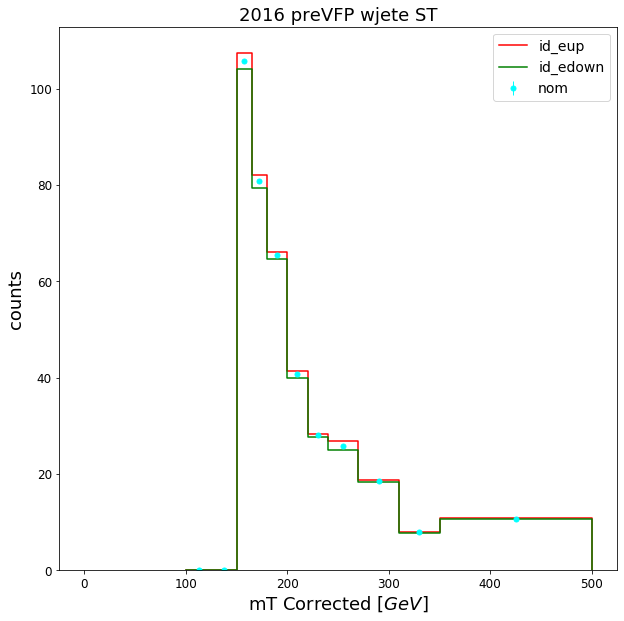

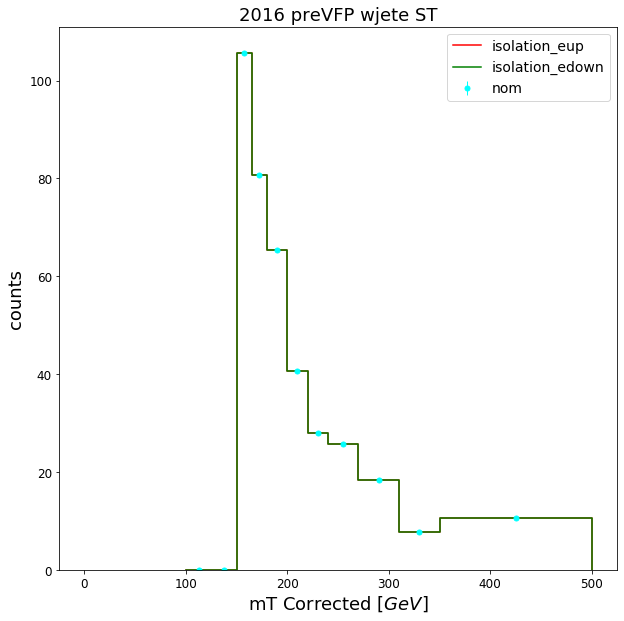

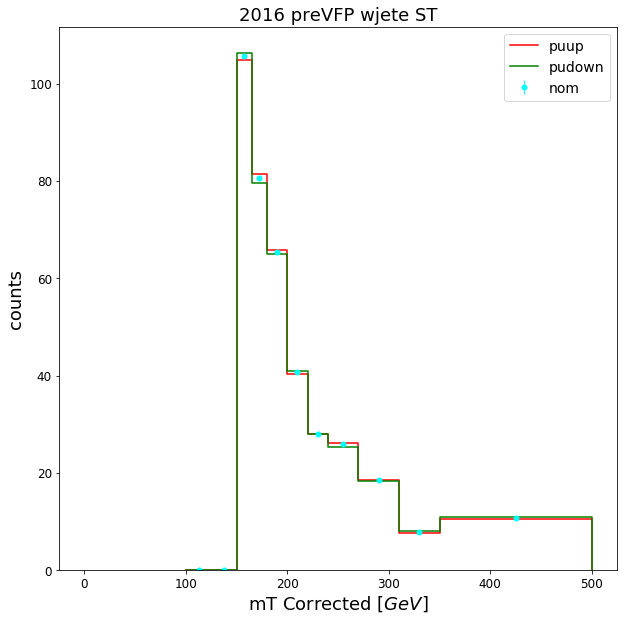

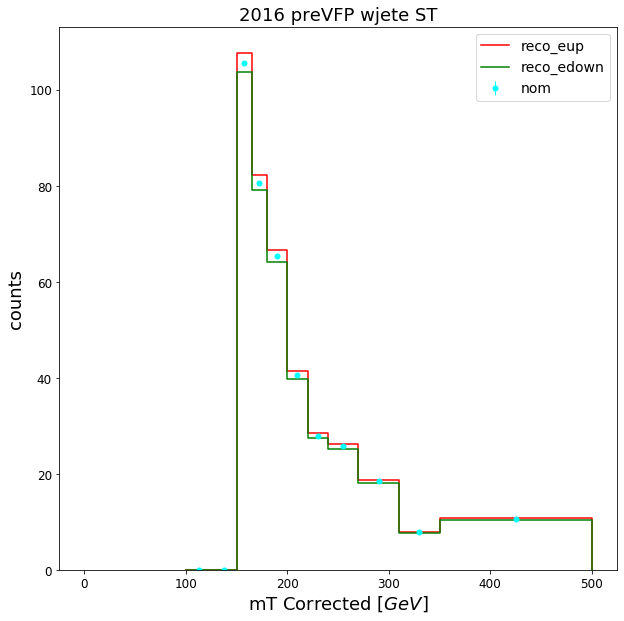

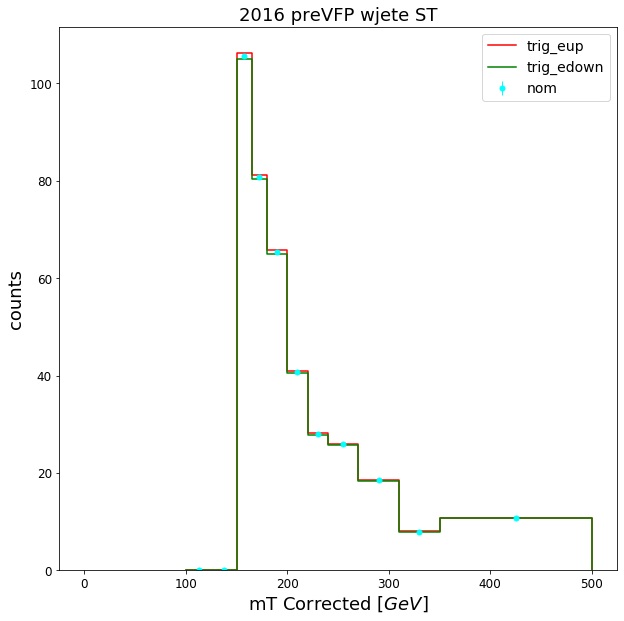

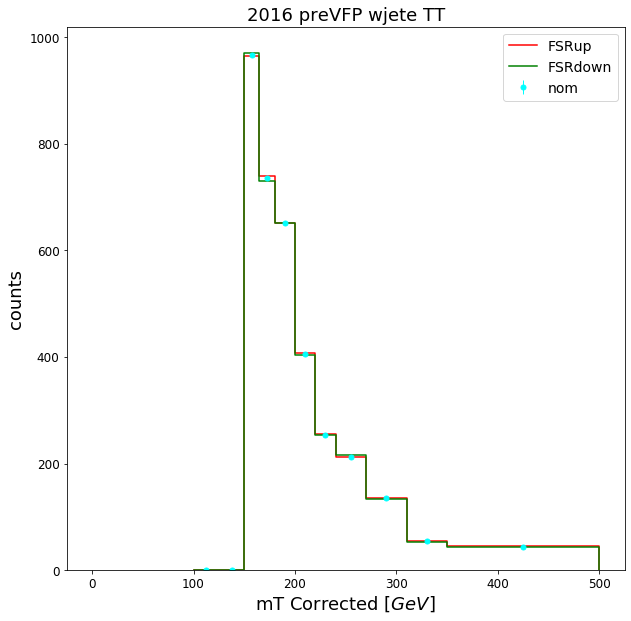

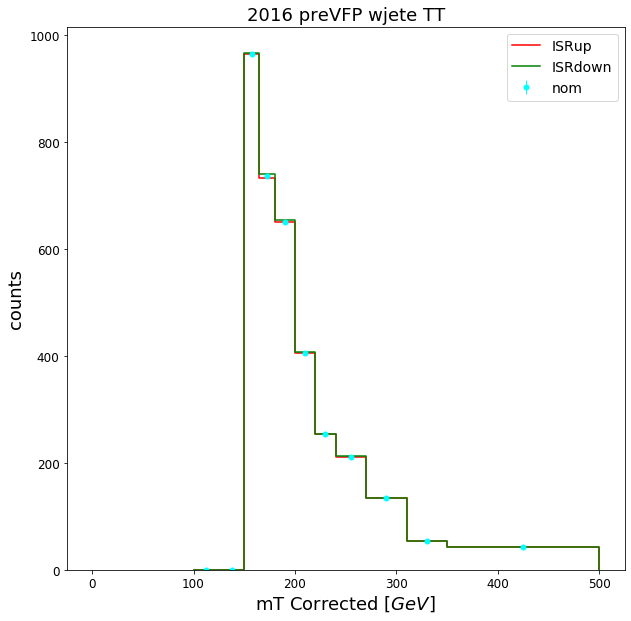

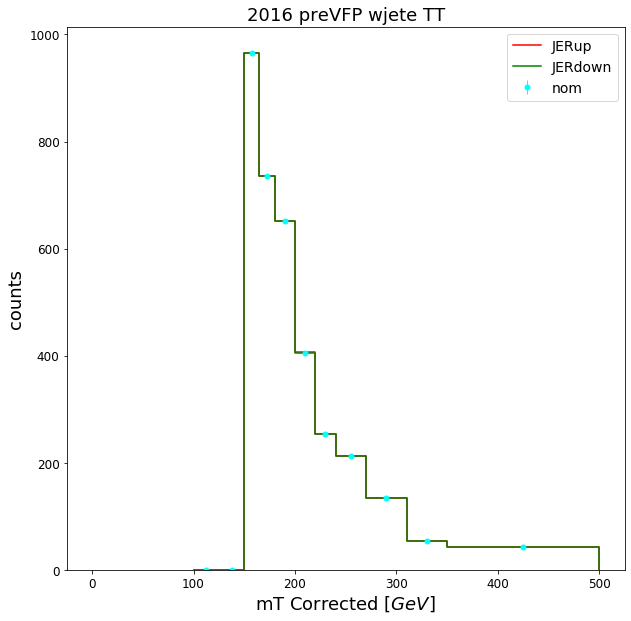

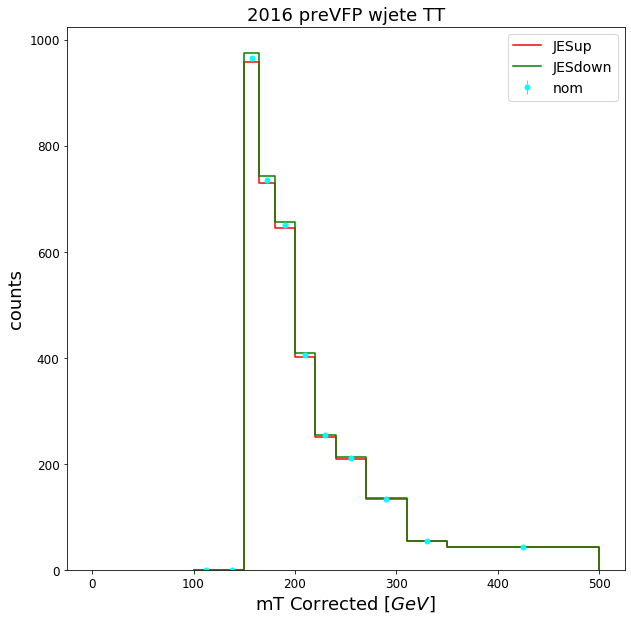

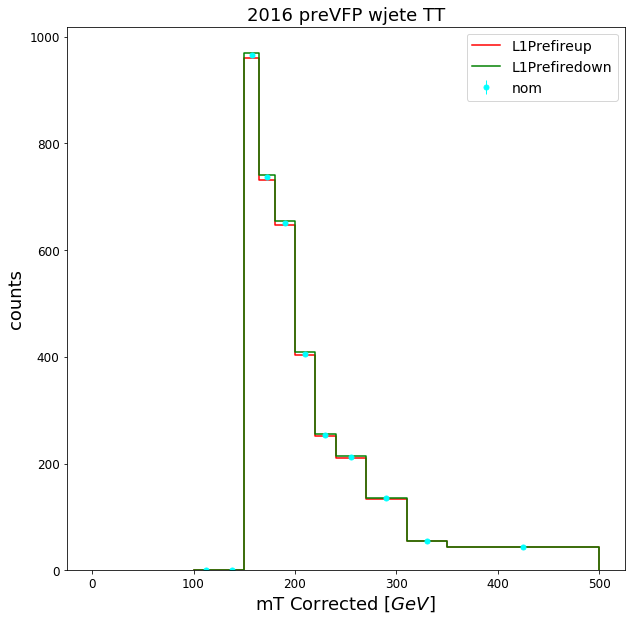

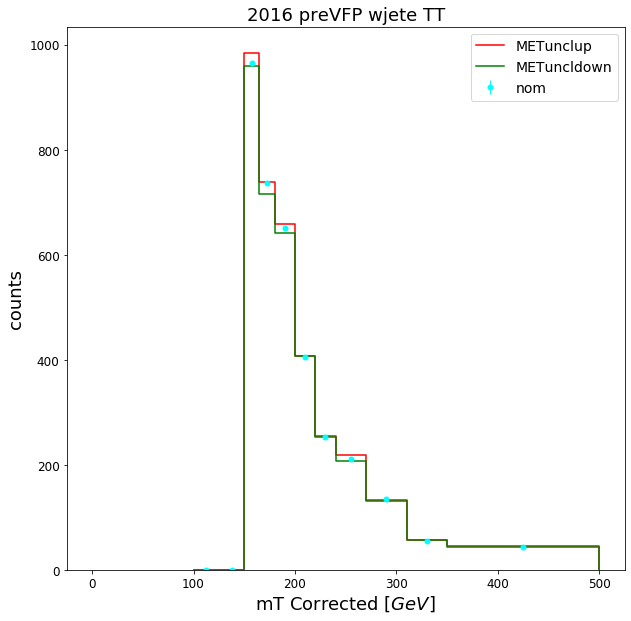

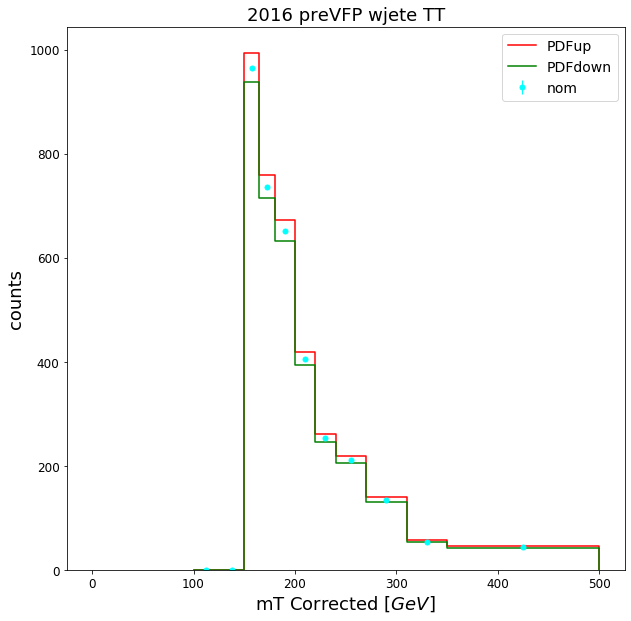

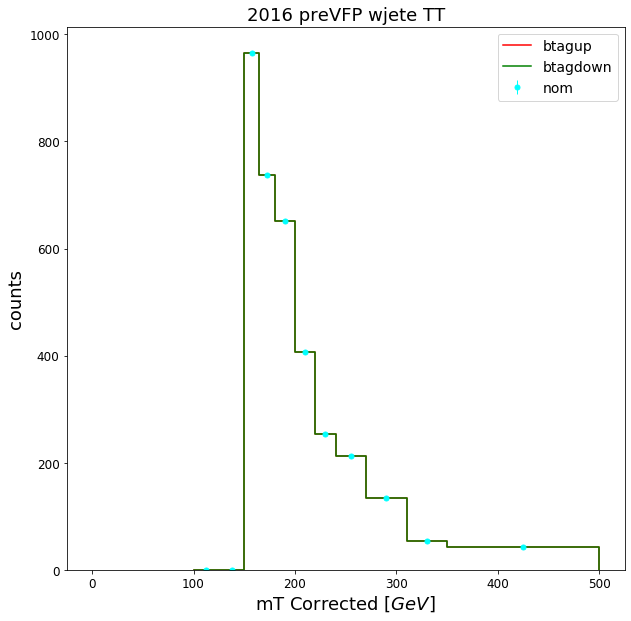

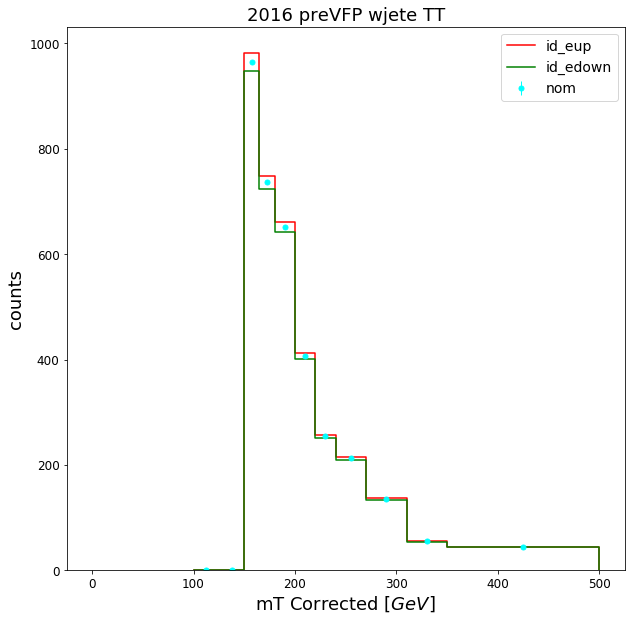

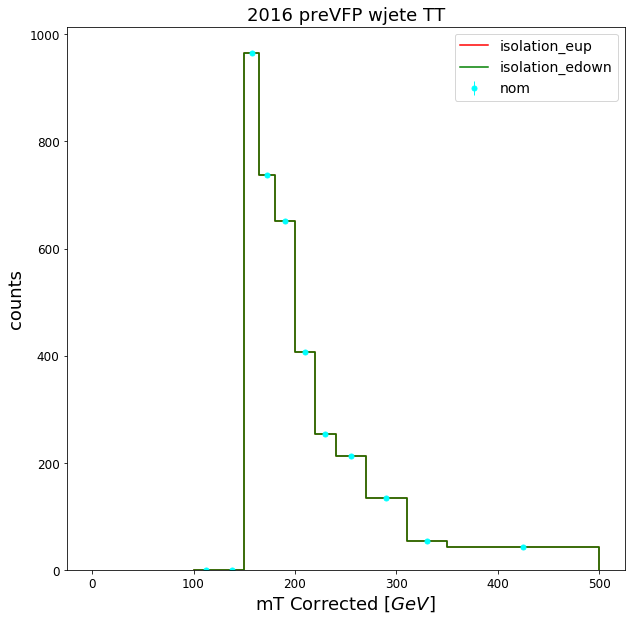

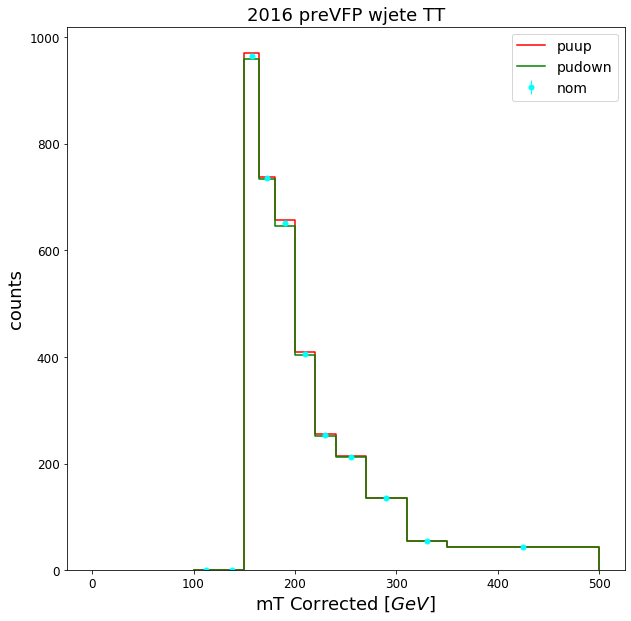

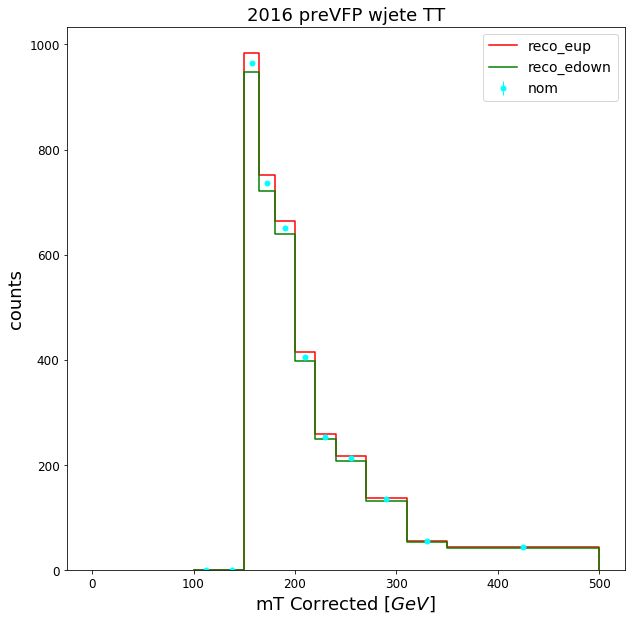

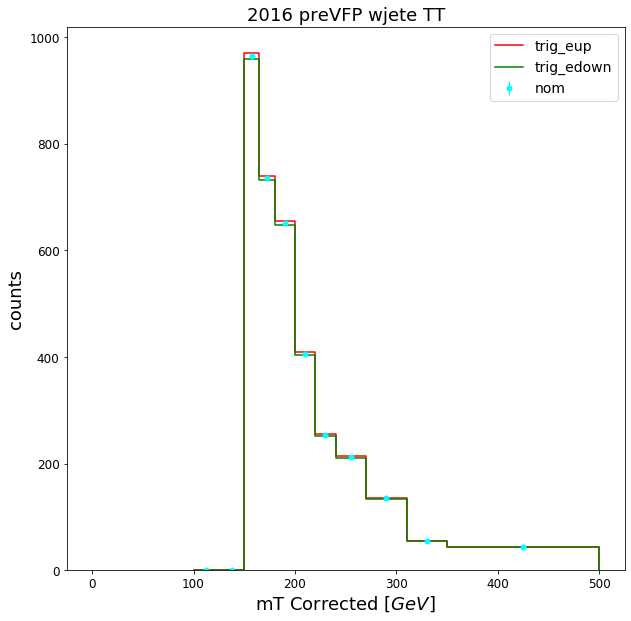

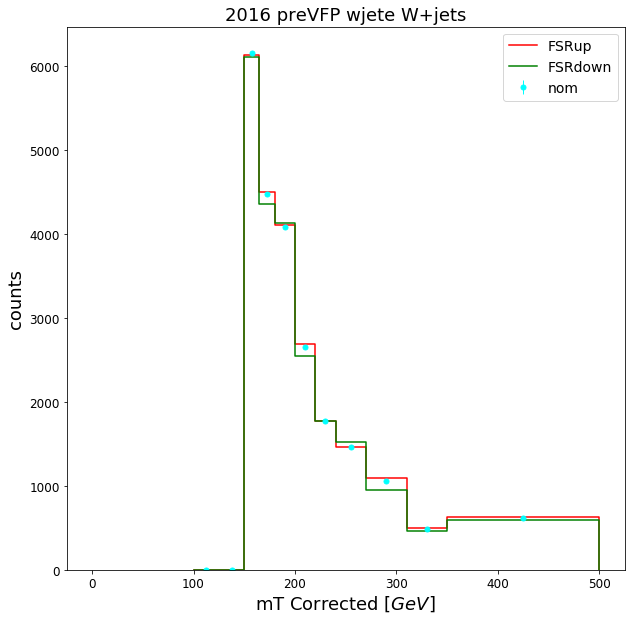

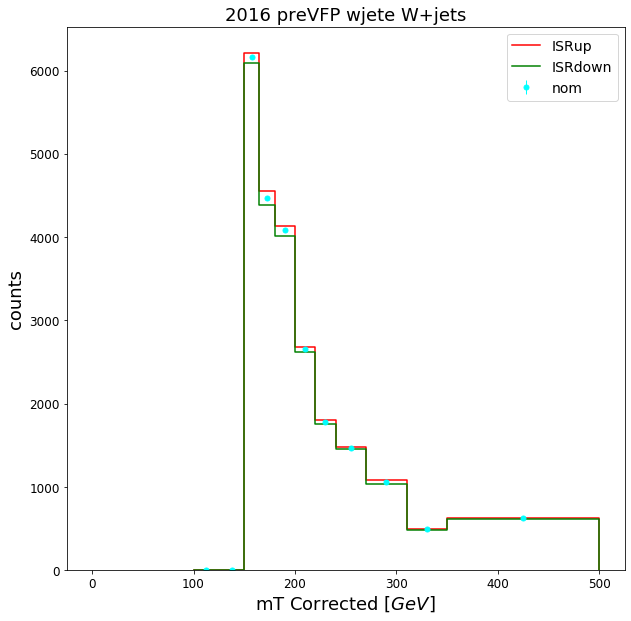

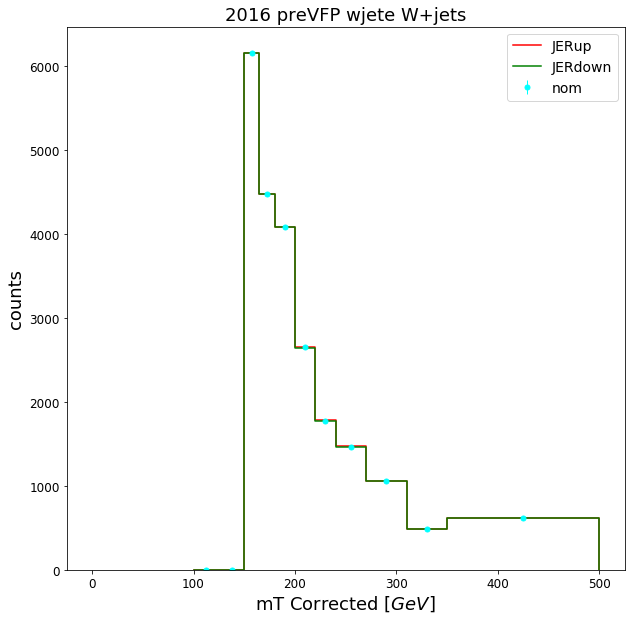

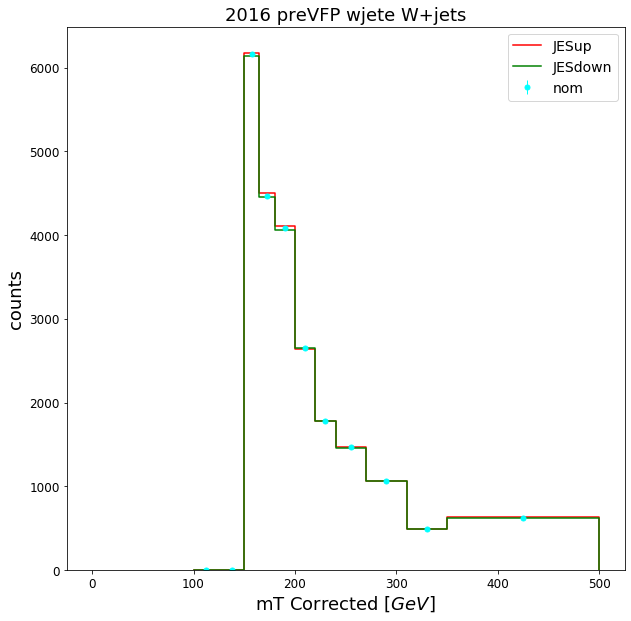

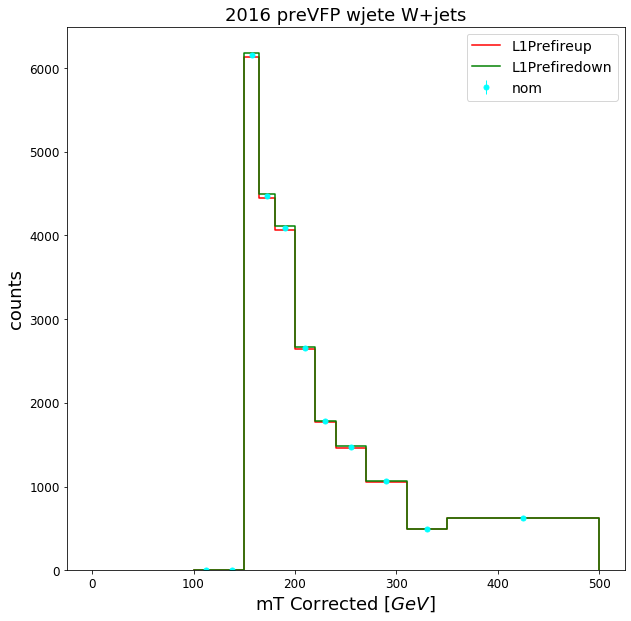

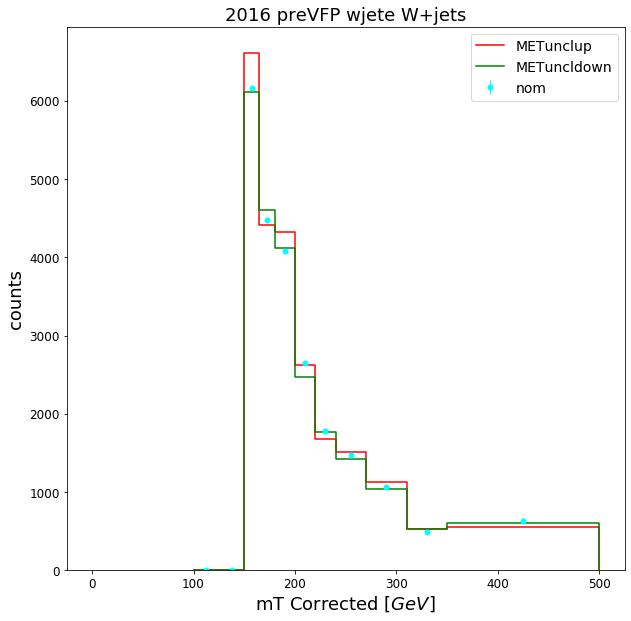

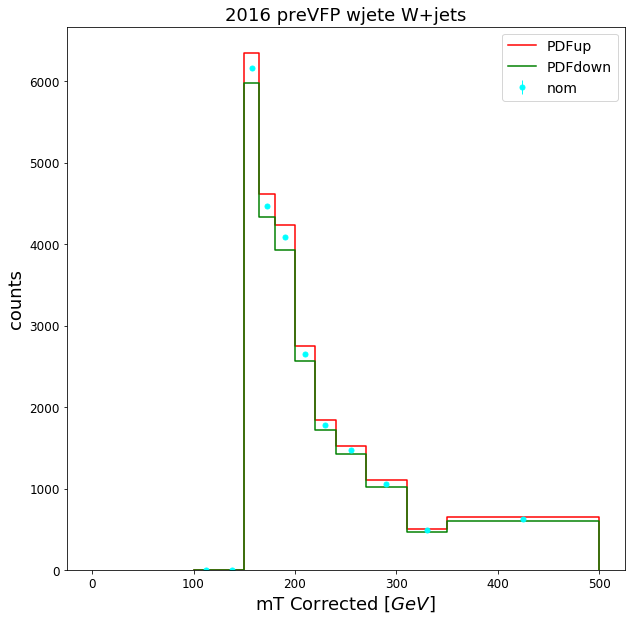

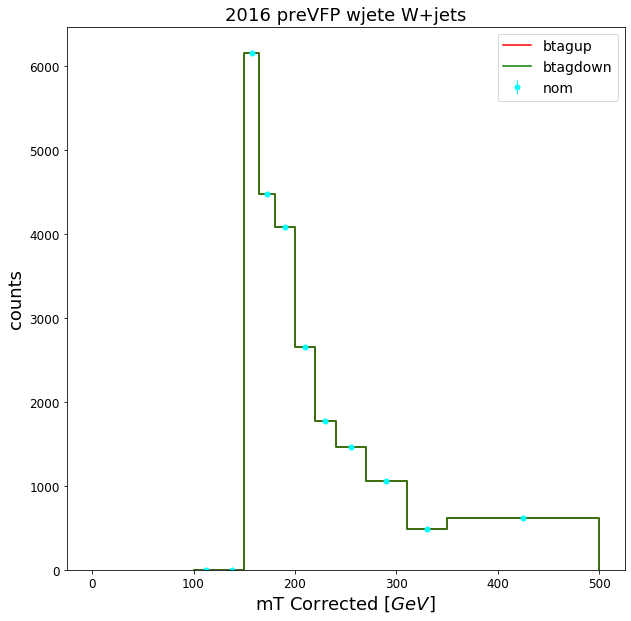

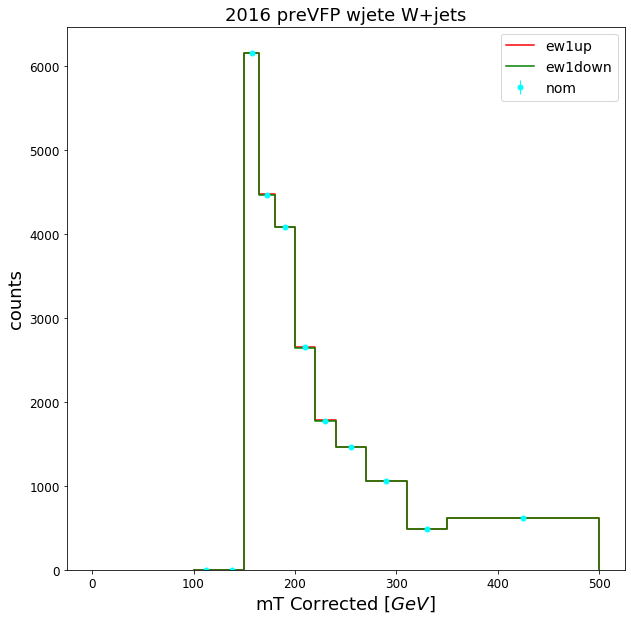

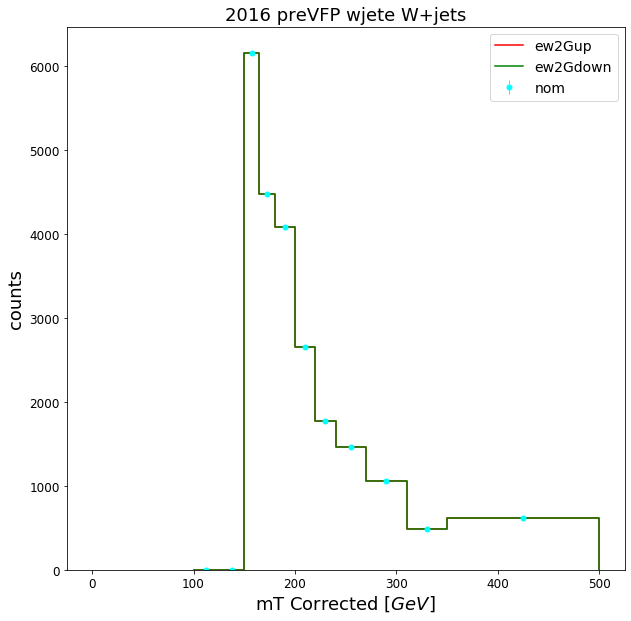

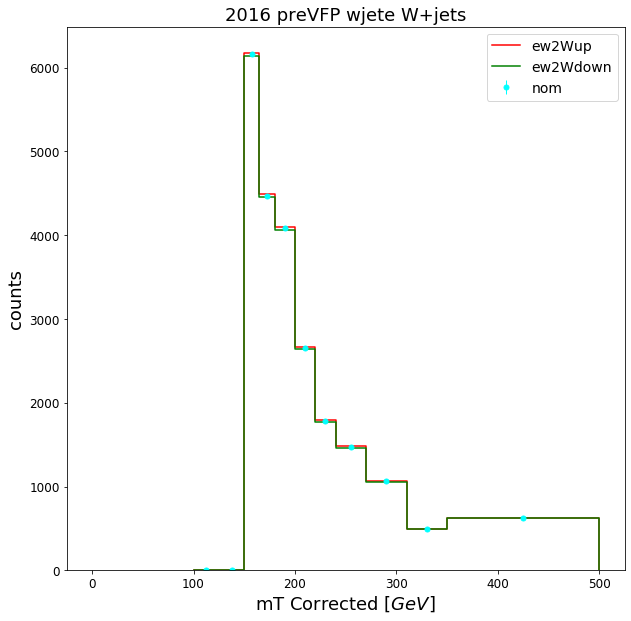

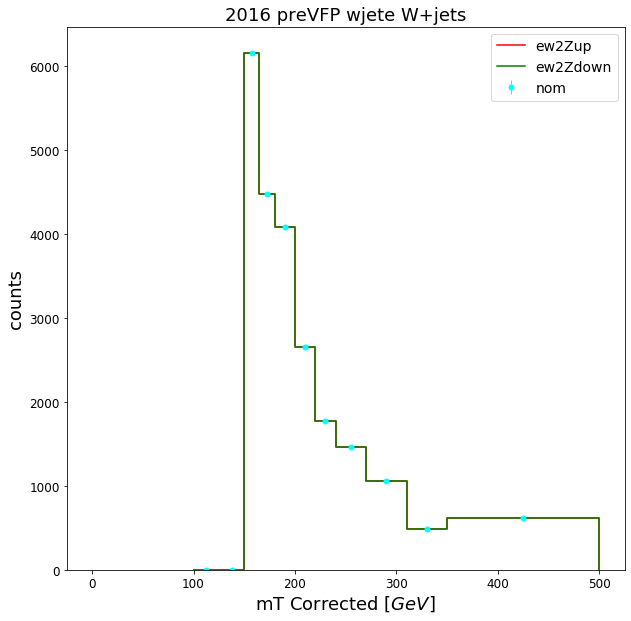

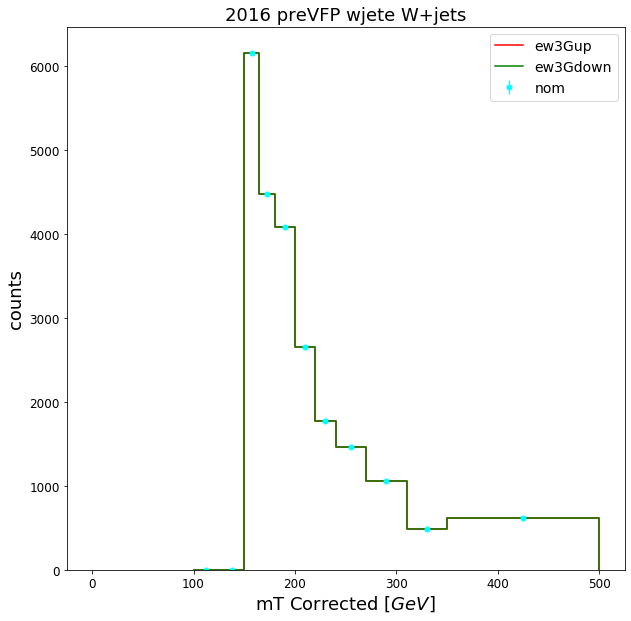

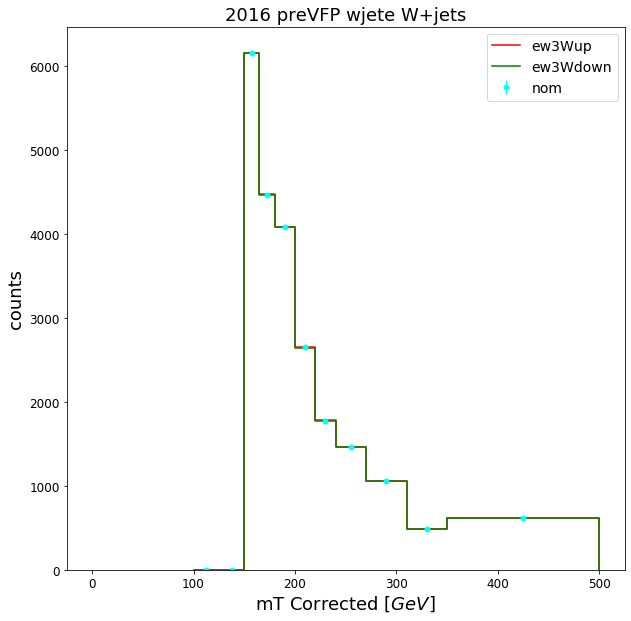

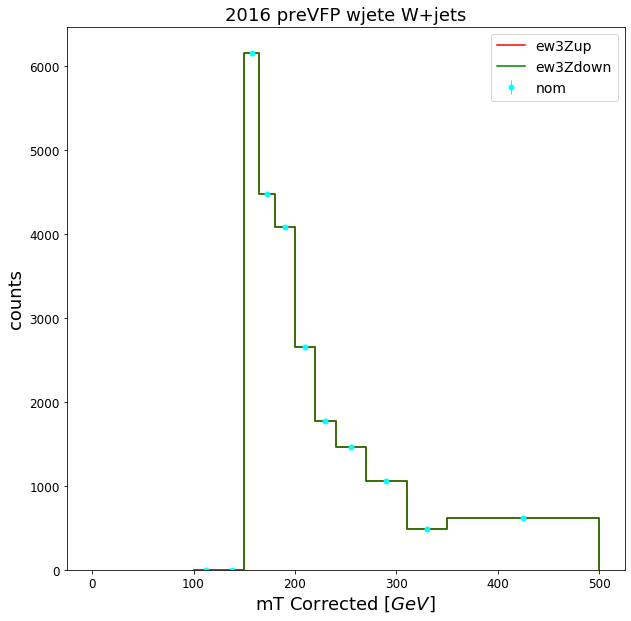

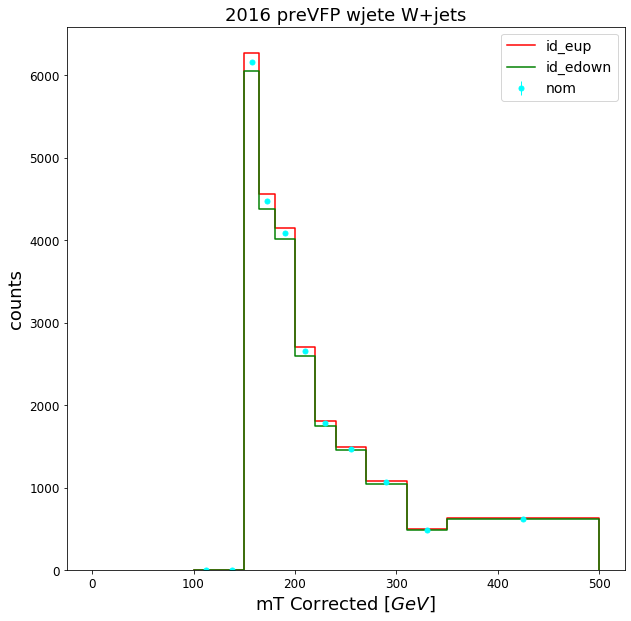

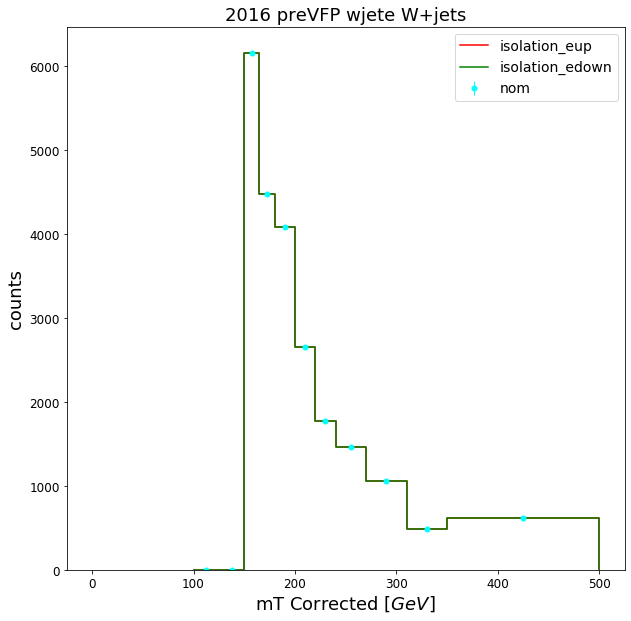

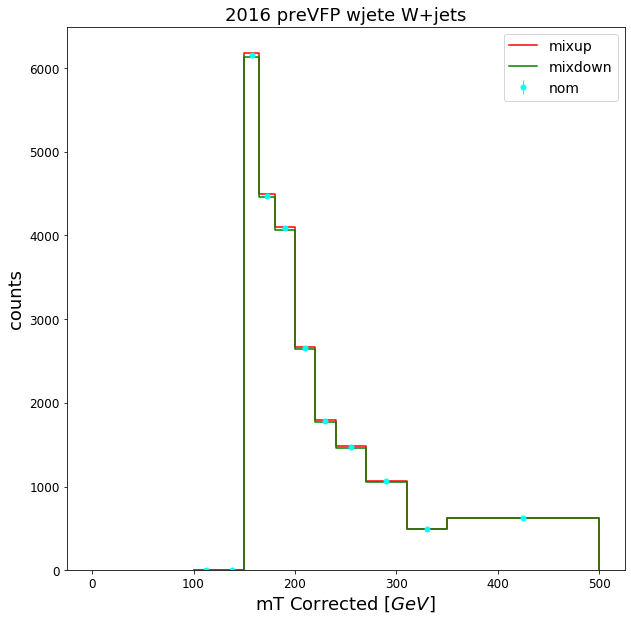

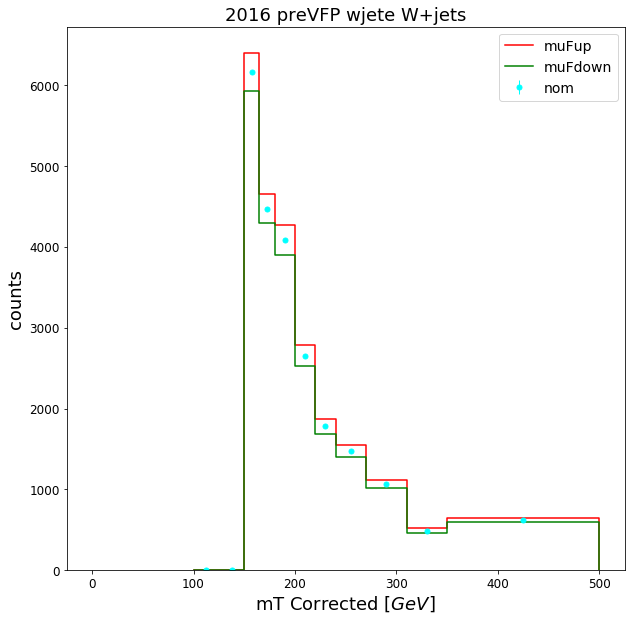

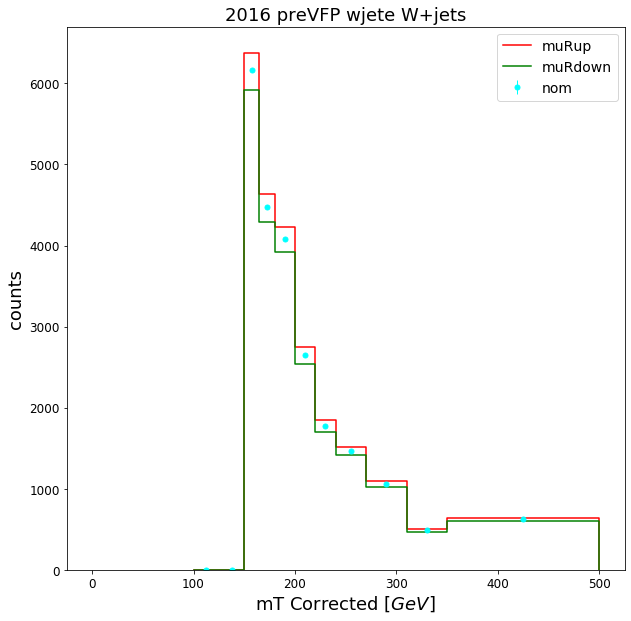

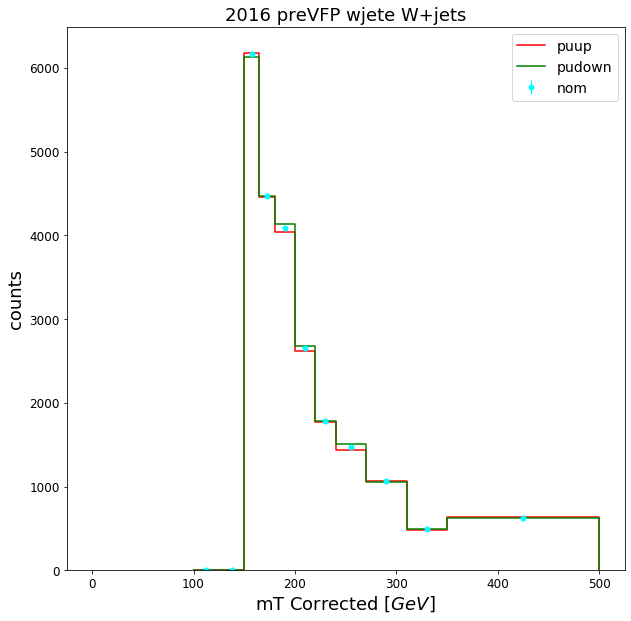

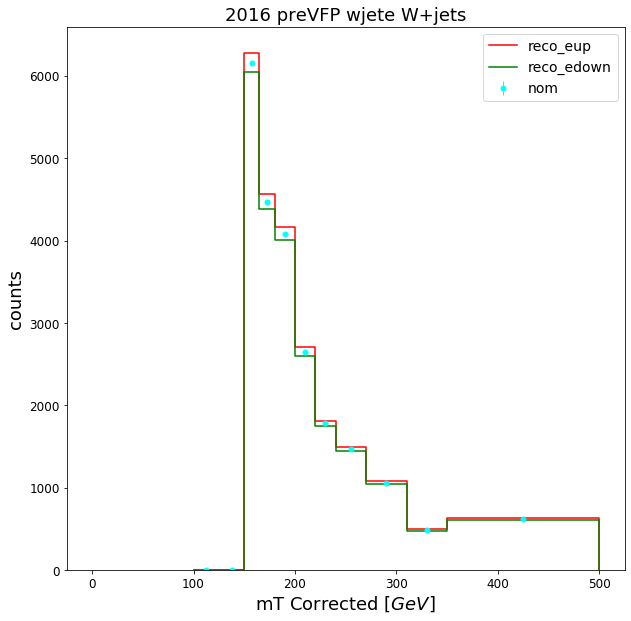

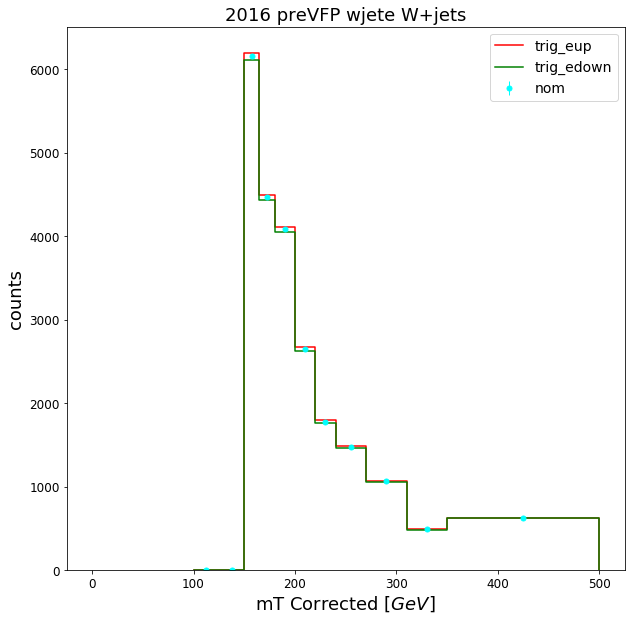

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
import re
cr = 'wjete'
# p ='DY+jets'
for p in bkg_hists['template'].integrate("region", cr).identifiers('process'):
    systematics = []
    for syst in bkg_hists['template'].integrate('region', cr).integrate('process', p).identifiers('systematic'):
        if (re.search("Up$", str(syst))):
            systematics.append(str(syst)[:-2])
    # sys = 'pu'


    for sys in systematics:
#         if ("uncl" in sys):pass
#         elif ("JES" in sys):pass
#         elif ("JER" in sys):pass
#         elif ("METuncl" in sys): pass
#         else: continue
        bins = bkg_hists['template'].integrate('region', cr).integrate("systematic",sys+"Down").axis("mT_corrected").edges()[()]
        down = bkg_hists['template'].integrate('region',cr).integrate('systematic', sys+'Down').integrate('process',p).integrate('npvs').values()[()]
        nom = bkg_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('process',p).integrate('npvs').values()[()]
        up = bkg_hists['template'].integrate('region',cr).integrate('systematic', sys+'Up').integrate('process',p).integrate('npvs').values()[()]
        if "e" in cr[-1]:
            label_data = "EGamma"
        else: label_data = "SingleMuon"
        f, ax = plt.subplots(figsize=[10,10])
        #         hep.histplot(data, bins,color='black',histtype='errorbar',
        #         label=label_data)
        hep.histplot(up, bins, color='red',
        label=sys+"up")
        hep.histplot(down, bins, color='green',
        label=sys+"down")
        hep.histplot(nom, bins, color='cyan',histtype='errorbar',
        label="nom")
        ax.legend()
#         ax.set_yscale('log')
        ax.set_ylabel("counts")
        ax.set_xlabel("mT Corrected $[GeV]$")
        ax.set_title("2016 preVFP "+cr+" "+str(p))

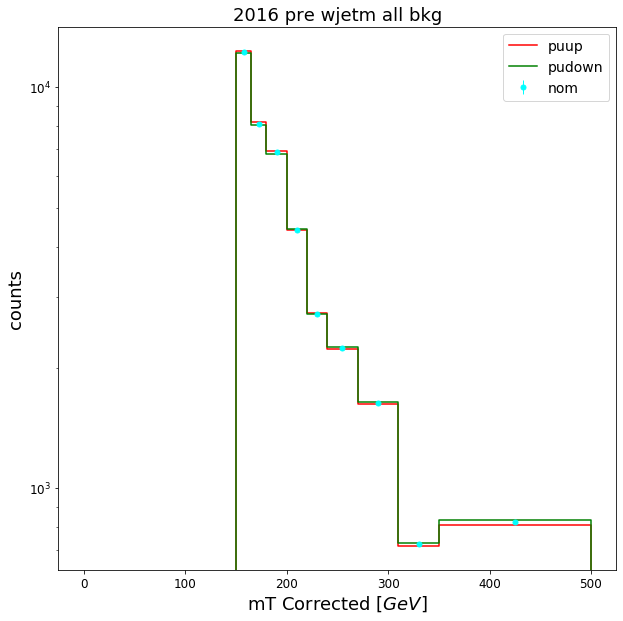

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
import re
cr = 'wjetm'
systematics = []
for syst in bkg_hists['template'].integrate('region', cr).identifiers('systematic'):
    if (re.search("Up$", str(syst))):
        systematics.append(str(syst)[:-2])


for sys in systematics:
    if ("pu" in sys):pass
#     elif ("JES" in sys):pass
#     elif ("FSR" in sys): pass
    else: continue
    bins = bkg_hists['template'].integrate('region', cr).integrate("systematic",sys+"Down").axis("mT_corrected").edges()[()]
#     data = data_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
    down = bkg_hists['template'].integrate('region',cr).integrate('systematic', sys+'Down').integrate('npvs').integrate('process').values()[()]
    nom = bkg_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
    up = bkg_hists['template'].integrate('region',cr).integrate('systematic', sys+'Up').integrate('npvs').integrate('process').values()[()]

    f, ax = plt.subplots(figsize=[10,10])
#     hep.histplot(data, bins,color='black',histtype='errorbar',
#     label="Egamma")
    hep.histplot(up, bins, color='red',
    label=sys+"up")
    hep.histplot(down, bins, color='green',
    label=sys+"down")
    hep.histplot(nom, bins, color='cyan',histtype='errorbar',
    label="nom")
    ax.legend()
    ax.set_yscale('log')
    ax.set_ylabel("counts")
    ax.set_xlabel("mT Corrected $[GeV]$")
    ax.set_title("2016 pre "+cr+ " all bkg")

In [ ]:
-rw-r--r--. 1 runiyal zh 4.5K Aug  8 21:51 sre2018Mphi-750-Mchi-150.txt
